# TP 2 — Comparer ML et deep learning sur Tiny Shakespeare

Je compare machine learning et deep learning sur l'identification du locuteur dans Tiny Shakespeare. Je pars du TP1 et de ses analyses, et je garde son protocole d'évaluation, car les réseaux changent la représentation et le modèle, mais pas la façon de mesurer.

| Étape | Section | Ce que je livre |
|---|---|---|
| 1. Nettoyage et prétraitement | section 1 | Les 962 répliques du TP1, le découpage, puis un tokenizer commun aux modèles ML et DL. |
| 2. Représentation | section 2 | La référence TF–IDF du TP1 et des embeddings appris avec le classifieur. |
| 3. Comparaison ML / DL | section 3 | Classe majoritaire, LinearSVC, puis MLP, LSTM et GRU sur les mêmes cinq folds. |
| 4. Évaluation | section 4 | Scores par fold, erreurs relues réplique par réplique, expériences ciblées, test final, journal et conclusion. |


## 0. Mon problème et les acquis du TP1

Je prédis le locuteur d'une réplique à partir de son seul texte, parmi 10 classes. Comme au TP1, je garde les répliques d'au moins 10 mots des 10 locuteurs les plus fréquents.

| Fait observé dans le TP1 | Ce que j'examine dans le TP2 |
|---|---|
| 962 répliques, de 78 à 129 par classe | Le sur-apprentissage, car le jeu est petit et modérément déséquilibré. |
| 9 confusions JULIET–ROMEO (4 + 5) et 7 de GLOUCESTER vers DUKE VINCENTIO sur le test | Les indices communs aux erreurs, dont la pièce d'origine. |
| `kate` (2,645), `romeo` (1,623), `paulina` (1,447) et `camillo` (1,211) portent les poids les plus élevés (TP1, section 8.3) | Le modèle reconnaît-il des personnages, donc une pièce, ou un style ? |
| LinearSVC obtient un F1 macro de 0,482 ± 0,035 en validation croisée, 1 sur le train des folds et 0,563 sur le test | La généralisation plutôt que l'ajustement au train. Le 0,563 sert de repère dans la section 4.4. |


> *Mes hypothèses :*
>
> - **H1, indices lexicaux.** Un MLP sur la moyenne des embeddings reste à moins de 0,05 de F1 macro de TF–IDF + LinearSVC, car les deux ignorent l'ordre des mots. Testée dans la section 3.4.
> - **H2, ordre des mots.** LSTM et GRU ne dépassent le MLP que si l'ordre porte un signal, donc mélanger les mots doit les dégrader mais pas le MLP. Testée dans les sections 3.5, 3.6 et 4.3.
> - **H3, mémorisation.** Sans régularisation, un réseau atteint un F1 macro train proche de 1 en moins de 20 epochs, avec un écart train/validation supérieur à 0,3. Testée par les courbes des sections 3.4 à 3.6.
> - **H4, coût.** À largeur égale, le GRU a moins de paramètres et s'entraîne plus vite que le LSTM pour un F1 macro comparable. Testée dans les sections 3.6 et 4.1.

Je décide sur les scores moyens, leur dispersion et le coût, avant de regarder le test.


### Mon environnement

Je sélectionne `.venv/bin/python` comme kernel et j'installe les dépendances dans le terminal :

```sh
uv pip install --python .venv/bin/python -r requirements.txt
```

> *Mes choix :*
>
> - PyTorch, pour écrire moi-même forward, loss, backward et mise à jour des poids.
> - Le CPU du M3 Max, plutôt que son GPU par MPS, le backend GPU de PyTorch sur Mac. Sur MPS, le backward des embeddings additionne les gradients dans un ordre qui varie d'un run à l'autre, donc deux runs à seed égale n'y donnent pas les mêmes poids. Sur CPU, ils sont identiques (section 3.1), et les versions sont figées dans `requirements.txt`.
> - Seed 42, la graine du générateur aléatoire, pour les données et les modèles ML. Les réseaux tournent avec les seeds 42, 43 et 44, réinitialisées avant chaque run par une fonction de la section 3.1. Je sépare ainsi la dispersion entre folds de celle de l'initialisation, et je vérifie deux runs à seed égale.


In [1]:
# Environnement : versions, matériel, device PyTorch et seed unique pour random, numpy et torch.
import platform
import random
import subprocess
import sys
from importlib.metadata import version

import numpy as np
import torch

# Seed fixée ici ; la fonction de la section 3.1 la réinitialisera avant chaque entraînement.
RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

# CPU, pour des entraînements reproductibles à seed égale
device = torch.device('cpu')

# Versions et dépendances
print(f'Python : {platform.python_version()} — {sys.executable}')
for paquet in ('numpy', 'pandas', 'matplotlib', 'scikit-learn', 'ipykernel', 'torch'):
    print(f'{paquet} : {version(paquet)}')

# Système et processeur
print(f'Système : {platform.platform()} — {platform.machine()}')
if sys.platform == 'darwin':
    processeur, ram = subprocess.check_output(
        ['sysctl', '-n', 'machdep.cpu.brand_string', 'hw.memsize'], text=True,
    ).splitlines()
    print(f'Processeur : {processeur} — RAM : {int(ram) / 2**30:g} Gio')

print(f'Device : {device} — Seed : {RANDOM_STATE}')


Python : 3.14.7 — /Users/hopy/Documents/ING3_GIA/ING3_IA_GB_S1/NLP/.venv/bin/python
numpy : 2.5.3
pandas : 3.0.5
matplotlib : 3.11.1
scikit-learn : 1.9.0
ipykernel : 7.3.0
torch : 2.14.0
Système : macOS-26.5-arm64-arm-64bit-Mach-O — arm64
Processeur : Apple M3 Max — RAM : 36 Gio
Device : cpu — Seed : 42


## 1. Nettoyage et prétraitement

### 1.1 Retrouver les mêmes répliques

Je reprends le chargement et le parser du TP1 sans dépendre de son état d'exécution. Le nom en tête de bloc donne l'étiquette et ne reste pas dans l'entrée du modèle. Le parser est mon seul nettoyage, car je garde ponctuation et majuscules pour laisser le tokenizer de la section 1.3 décider, mesure à l'appui.


In [2]:
# Corpus : téléchargement de Tiny Shakespeare et parser du TP1 (bloc = étiquette + réplique).
import re
import urllib.request

import pandas as pd
from IPython.display import display

URL = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"

# Téléchargement du texte brut
with urllib.request.urlopen(URL, timeout=30) as reponse:
    texte = reponse.read().decode('utf-8')


def parser_repliques(txt: str) -> pd.DataFrame:
    """Reprend les règles du TP1 : un bloc, une étiquette et sa réplique."""
    lignes = []
    for bloc in txt.split("\n\n"):
        bloc = bloc.strip()
        if not bloc:
            continue
        parties = bloc.split("\n")
        entete = re.match(r"^([A-Z][A-Za-z' ]*):$", parties[0])  # Nom en majuscules puis « : »
        if entete and len(parties) > 1:
            lignes.append({
                'locuteur': entete.group(1).strip(),
                'replique': " ".join(p.strip() for p in parties[1:]).strip(),
            })
    return pd.DataFrame(lignes)


df = parser_repliques(texte)


In [3]:
# Jeu retenu : répliques d'au moins 10 mots, puis les 10 locuteurs les plus fréquents, comme au TP1.
seuil, nb_locuteurs = 10, 10

# Le seuil de longueur s'applique avant de compter les locuteurs.
longueurs = df['replique'].str.split().str.len()
locuteurs = df.loc[longueurs >= seuil, 'locuteur'].value_counts().head(nb_locuteurs).index

donnees = df.loc[
    (longueurs >= seuil) & df['locuteur'].isin(locuteurs),
    ['replique', 'locuteur'],
].copy()  # Ordre et indices du TP1 conservés.


In [4]:
# Contrôles du jeu retenu : effectifs, longueurs, valeurs manquantes, doublons.
effectifs = donnees['locuteur'].value_counts()
longueurs_retenues = donnees['replique'].str.split().str.len()

# Comptes globaux
print(f'Extraction : {len(df):,} répliques, {df["locuteur"].nunique()} labels')
print(f'Jeu retenu : {len(donnees)} répliques, {len(effectifs)} classes')
print(f'Longueurs (mots) : min {longueurs_retenues.min()}, '
      f'médiane {longueurs_retenues.median():g}, max {longueurs_retenues.max()}')
print(f'Valeurs manquantes : {donnees.isna().sum().sum()}')
print(f'Répliques vides : {donnees["replique"].str.strip().eq("").sum()}')
print(f'Textes dupliqués dans le jeu retenu : {donnees["replique"].duplicated().sum()}')

# Effectifs par classe et aperçu
display(effectifs.rename('Répliques').to_frame())
display(donnees.head(3))


Extraction : 7,094 répliques, 297 labels
Jeu retenu : 962 répliques, 10 classes
Longueurs (mots) : min 10, médiane 31, max 578
Valeurs manquantes : 0
Répliques vides : 0
Textes dupliqués dans le jeu retenu : 0


,Répliques
locuteur,
GLOUCESTER,129
DUKE VINCENTIO,125
MENENIUS,107
PETRUCHIO,95
ROMEO,94
CORIOLANUS,87
JULIET,85
LEONTES,82
ISABELLA,80


,replique,locuteur
22,"What work's, my countrymen, in hand? where go ...",MENENIUS
24,"Why, masters, my good friends, mine honest nei...",MENENIUS
26,"I tell you, friends, most charitable care Have...",MENENIUS


> *Mes observations :*
>
> Je retrouve les 962 répliques du TP1, car l'extraction donne 7 094 répliques et 297 étiquettes, puis 10 classes de 78 à 129 répliques après le seuil de 10 mots. Aucune valeur manquante, aucune réplique vide, aucun doublon.
>
> Les longueurs vont de 10 à 578 mots, avec une médiane de 31. Cette asymétrie fixe un réglage de la section 2.2, car une longueur maximale égale au maximum remplirait les batches de padding pour quelques répliques.


### 1.2 Séparer apprentissage, sélection et évaluation

Je reproduis le découpage stratifié du TP1, soit 769 répliques de développement et 193 de test avec la seed 42. Mêmes données, même seed et même version de scikit-learn donnent le même découpage, et la section 1.3 le vérifie avec la taille du vocabulaire TF–IDF du TP1.


In [5]:
# Découpage développement / test du TP1 : 80/20 stratifié, seed 42.
from sklearn.model_selection import StratifiedKFold, train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    donnees['replique'], donnees['locuteur'],
    test_size=0.2, stratify=donnees['locuteur'], random_state=RANDOM_STATE,
)

# Vérifications : aucun indice ni texte partagé entre développement et test.
assert set(X_train.index).isdisjoint(X_test.index)
assert not set(X_train).intersection(X_test)

# Tailles, empreinte du découpage et répartition des classes
print(f'Développement : {len(X_train)} répliques ; test : {len(X_test)}')
print(f'Premiers indices du test : {list(X_test.index[:10])}')
display(pd.DataFrame({
    'Développement': y_train.value_counts(),
    'Test': y_test.value_counts(),
}).sort_values('Développement', ascending=False))


Développement : 769 répliques ; test : 193
Premiers indices du test : [3009, 6783, 5903, 1321, 3338, 2294, 3344, 2875, 3378, 2212]


,Développement,Test
locuteur,,
GLOUCESTER,103,26
DUKE VINCENTIO,100,25
MENENIUS,85,22
PETRUCHIO,76,19
ROMEO,75,19
CORIOLANUS,70,17
JULIET,68,17
LEONTES,66,16
ISABELLA,64,16


Sur les 769 répliques, je prépare cinq folds stratifiés avec `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)`. Tous les modèles utilisent les mêmes folds, donc je les compare sur les mêmes répliques.

| Ensemble | Taille | Rôle |
|---|---|---|
| Train du fold | 615 ou 616 | Tout ce qui dépend des données s'y apprend, donc vocabulaire, IDF, embeddings et poids. |
| Validation du fold | 154 ou 153 | Comparaison des modèles et choix des réglages, dont le nombre d'epochs des réseaux (section 3.1). |
| Test | 193 | Une seule évaluation, après avoir figé tous les choix (section 4.4). |

Je ne réserve pas de validation interne aux réseaux, car la validation du fold suffit pour choisir leur nombre d'epochs, comme expliqué dans la section 3.1.


In [6]:
# Cinq folds stratifiés sur les 769 répliques de développement, communs aux modèles ML et DL.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Indices d'origine, utilisables avec .loc, plutôt que positions
folds = [
    {'train': X_train.index[positions_train], 'validation': X_train.index[positions_validation]}
    for positions_train, positions_validation in cv.split(X_train, y_train)
]

# Vérification : les dix classes sont présentes dans chaque validation.
assert all(y_train.loc[fold['validation']].nunique() == y_train.nunique() for fold in folds)

display(pd.DataFrame(
    [{nom: len(indices) for nom, indices in fold.items()} for fold in folds],
    index=pd.RangeIndex(1, len(folds) + 1, name='Fold'),
))


,train,validation
Fold,,
1,615,154
2,615,154
3,615,154
4,615,154
5,616,153


> *Mon analyse :*
>
> Je retrouve 769 répliques de développement et 193 de test, comme au TP1, et les deux vérifications `assert` passent, donc aucun indice ni texte n'est partagé. La section 1.3 ajoutera une preuve, car le TF–IDF du TP1 recalculé sur ces 769 répliques doit retrouver ses 5 915 termes.
>
> Les cinq folds donnent 615 répliques d'apprentissage et 154 de validation pour les folds 1 à 4, puis 616 et 153 pour le dernier. Chaque réplique de développement est évaluée une fois, et les dix classes sont présentes dans chaque validation.


### 1.3 Choisir le tokenizer

Je tokenise en mots, car avec 962 répliques un vocabulaire de quelques milliers de tokens distincts reste apprenable et les séquences restent courtes, avec une médiane de 31 mots. Avant de fixer les règles, je compte les cas rencontrés dans les 769 répliques de développement, pour décider sur des chiffres.


In [7]:
# Faits sur le texte brut des 769 répliques de développement, avant toute décision de découpage.
from collections import Counter

# Chaque cas est un motif regex ; « mot » = lettres et apostrophes, sans découpage imposé.
CAS = {
    'Apostrophe en tête': r"(?<![A-Za-z])'[A-Za-z]+",
    'Apostrophe interne': r"[A-Za-z]+'[A-Za-z]+",
    'Apostrophe en fin': r"[A-Za-z]+'(?![A-Za-z])",
    'Mot d’une lettre': r"(?<![A-Za-z'])[A-Za-z](?![A-Za-z'])",
    'Tiret': r"[A-Za-z]+-[A-Za-z]+",
    'Chiffre': r"\d+",
    'Ponctuation': r"[,;:!?.]",
}


def compter_cas(motif: str) -> dict:
    """Répliques contenant le motif et les trois formes les plus fréquentes qu'il capture."""
    expression = re.compile(motif)
    formes = Counter(forme.lower() for texte in X_train for forme in expression.findall(texte))
    return {
        'Répliques concernées': sum(bool(expression.search(texte)) for texte in X_train),
        'Formes les plus fréquentes': ', '.join(
            f'{forme} ({n})' for forme, n in formes.most_common(3)),
    }


# Un tableau, une ligne par cas
with pd.option_context('display.max_colwidth', None):
    display(pd.DataFrame({cas: compter_cas(motif) for cas, motif in CAS.items()}).T
            .rename_axis('Cas dans le texte brut'))

# Longueurs médianes en mots et en caractères ; leur rapport chiffre un découpage en caractères.
mots_par_replique = X_train.str.split().str.len()
caracteres_par_replique = X_train.str.len()
caracteres_par_mot = caracteres_par_replique.median() / mots_par_replique.median()
print(f'Longueur médiane : {mots_par_replique.median():g} mots '
      f'et {caracteres_par_replique.median():g} caractères par réplique, '
      f'soit {caracteres_par_mot:.1f} caractères par mot.')


,Répliques concernées,Formes les plus fréquentes
Cas dans le texte brut,,
Apostrophe en tête,119,"'tis (61), 'twere (10), 'twas (8)"
Apostrophe interne,392,"i'll (103), that's (20), ne'er (13)"
Apostrophe en fin,81,"i' (23), o' (22), banished' (4)"
Mot d’une lettre,549,"i (902), a (574), o (128)"
Tiret,149,"to-morrow (15), to-night (7), to-day (7)"
Chiffre,3,3 (3)
Ponctuation,769,", (3783), . (1247), ; (730)"


Longueur médiane : 31 mots et 159 caractères par réplique, soit 5.1 caractères par mot.


> *Mes observations :*
>
> L'apostrophe interne touche 392 répliques, avec « i'll » (103), « that's » (20) et « ne'er » (13) en tête. L'apostrophe en tête touche 119 répliques, surtout « 'tis » (61), et l'apostrophe en fin 81 répliques, surtout « i' » (23) et « o' » (22). Les mots d'une lettre apparaissent dans 549 répliques, avec « i » (902), « a » (574) et « o » (128). Le tiret relie deux mots dans 149 répliques, les chiffres touchent 3 répliques et la ponctuation est partout. Une réplique médiane compte 31 mots pour 159 caractères, soit 5,1 caractères par mot, donc un découpage en caractères donnerait des séquences cinq fois plus longues.


Le TP1 utilisait le `token_pattern` par défaut de scikit-learn, `(?u)\b\w\w+\b`, qui supprime les tokens d'une lettre et coupe aux apostrophes. « I'll » devenait `ll` et « I » disparaissait, comme le montraient les IDF les plus élevés du TP1 avec `ll bring`. Or « I », « not » ou « Romeo » peuvent être des indices de locuteur. Je définis donc un tokenizer unique pour TF–IDF et pour les réseaux, avec ces règles :

| Cas dans le texte | Décision | Pourquoi |
|---|---|---|
| Majuscules (« Kate », « Romeo ») | minuscules | Même indice en début et en milieu de phrase, comme au TP1. |
| Ponctuation | supprimée | Un séparateur présent dans les 769 répliques, et aucune de mes hypothèses ne porte sur elle. |
| Mots d'une lettre (« I », « a », « O ») | conservés | Pronom, article et interjection, dans 549 répliques. |
| Apostrophe interne (« I'll », « that's ») | un seul token | 392 répliques, car couper « I'll » (103) donne le fragment `ll`. |
| Apostrophe en tête ou en fin (« 'tis », « i' ») | retirée | « 'tis » (61) devient `tis` et « i' » (23) devient `i`, car je garde le mot. |
| Tiret (« to-morrow ») | sépare | 149 répliques, et `to` puis `morrow` restent lisibles. |
| Chiffres | supprimés | 3 répliques seulement. |
| Caractères comme unités | non | 5,1 caractères par mot, donc des séquences cinq fois plus longues pour un petit réseau récurrent. |

Je garde aussi la référence exacte du TP1 dans la section 3.3, car l'écart entre les deux TF–IDF mesurera l'effet du tokenizer seul.


In [8]:
# Tokenizer commun aux modèles ML et DL, et reproduction du découpage par défaut du TP1.
MOTIF_TOKEN = re.compile(r"[a-z]+(?:'[a-z]+)*")  # Lettres et apostrophes internes.
MOTIF_DEFAUT = re.compile(r"(?u)\b\w\w+\b")  # token_pattern par défaut de scikit-learn (TP1).


def tokeniser(texte: str) -> list[str]:
    """Tokenizer commun : minuscules, mots et contractions."""
    return MOTIF_TOKEN.findall(texte.lower())


def tokeniser_defaut(texte: str) -> list[str]:
    """Découpage du TP1, pour mesurer ce que je change."""
    return MOTIF_DEFAUT.findall(texte.lower())


def montrer_decoupages(indices: tuple[int, ...]) -> None:
    """Affiche des répliques de développement et leurs deux découpages."""
    for indice in indices:
        print(f'{y_train.loc[indice]} : {X_train.loc[indice]}')
        print(f'   TP1    : {tokeniser_defaut(X_train.loc[indice])}')
        print(f'   commun : {tokeniser(X_train.loc[indice])}\n')


# Trois répliques : contraction, apostrophe en tête, nom propre et mots d'une lettre.
montrer_decoupages((3062, 563, 6253))


ROMEO : Switch and spurs, switch and spurs; or I'll cry a match.
   TP1    : ['switch', 'and', 'spurs', 'switch', 'and', 'spurs', 'or', 'll', 'cry', 'match']
   commun : ['switch', 'and', 'spurs', 'switch', 'and', 'spurs', 'or', "i'll", 'cry', 'a', 'match']

MENENIUS : For 'tis a sore upon us, You cannot tent yourself: be gone, beseech you.
   TP1    : ['for', 'tis', 'sore', 'upon', 'us', 'you', 'cannot', 'tent', 'yourself', 'be', 'gone', 'beseech', 'you']
   commun : ['for', 'tis', 'a', 'sore', 'upon', 'us', 'you', 'cannot', 'tent', 'yourself', 'be', 'gone', 'beseech', 'you']

PETRUCHIO : Nay, hear you, Kate: in sooth you scape not so.
   TP1    : ['nay', 'hear', 'you', 'kate', 'in', 'sooth', 'you', 'scape', 'not', 'so']
   commun : ['nay', 'hear', 'you', 'kate', 'in', 'sooth', 'you', 'scape', 'not', 'so']



Je compare maintenant les deux découpages sur les 769 répliques de développement, pour mesurer ce que le tokenizer commun ajoute et ce qu'il retire. Je recalcule aussi le TF–IDF du TP1 sur ces répliques, car retrouver ses 5 915 termes prouve que ce sont les mêmes 769 répliques.


In [9]:
# Ce que chaque découpage voit sur les 769 répliques de développement, puis l'empreinte du TP1.
from sklearn.feature_extraction.text import TfidfVectorizer

TOKENISEURS = {'TP1': tokeniser_defaut, 'commun': tokeniser}
PARAMS_TFIDF = dict(ngram_range=(1, 2), min_df=2, max_df=1.0, stop_words=None, sublinear_tf=True)


def compter_tokens(decouper) -> Counter:
    """Fréquence de chaque token sur le développement : une description, pas un apprentissage."""
    return Counter(token for texte in X_train for token in decouper(texte))


def plus_frequents(comptes: dict, n: int = 6) -> str:
    """Les n tokens les plus fréquents d'un dictionnaire de comptes, avec leur compte."""
    tries = sorted(comptes.items(), key=lambda paire: -paire[1])
    return ', '.join(f'{token} ({compte})' for token, compte in tries[:n])


def comparer_decoupages() -> pd.DataFrame:
    """Tokens vus par chaque découpage, et ceux que seul l'un des deux produit."""
    comptes = {nom: compter_tokens(decouper) for nom, decouper in TOKENISEURS.items()}
    seulement = {
        nom: {token: n for token, n in comptes[nom].items() if token not in comptes[autre]}
        for nom, autre in (('TP1', 'commun'), ('commun', 'TP1'))
    }
    return pd.DataFrame({
        'Tokens distincts': {nom: len(compte) for nom, compte in comptes.items()},
        'Tokens': {nom: sum(compte.values()) for nom, compte in comptes.items()},
        'Tokens distincts absents de l’autre': {
            nom: len(absents) for nom, absents in seulement.items()},
        'Tokens absents de l’autre': {
            nom: sum(absents.values()) for nom, absents in seulement.items()},
        'Les plus fréquents absents de l’autre': {
            nom: plus_frequents(absents) for nom, absents in seulement.items()},
    }).rename_axis('Tokenizer')


def taille_vocabulaire(vectoriseur: TfidfVectorizer) -> int:
    """Nombre de termes appris sur les 769 répliques de développement."""
    return len(vectoriseur.fit(X_train).vocabulary_)


with pd.option_context('display.max_colwidth', None):
    display(comparer_decoupages())

# Empreinte du TP1 : le même TF–IDF sur les mêmes 769 répliques doit retrouver ses 5 915 termes.
termes_tp1 = taille_vocabulaire(TfidfVectorizer(lowercase=True, **PARAMS_TFIDF))
termes_commun = taille_vocabulaire(
    TfidfVectorizer(tokenizer=tokeniser, token_pattern=None, lowercase=False, **PARAMS_TFIDF)
)
print(f'Termes TF–IDF (1-2 grammes, min_df=2) : TP1 {termes_tp1:,} ; '
      f'tokenizer commun {termes_commun:,}')


,Tokens distincts,Tokens,Tokens distincts absents de l’autre,Tokens absents de l’autre,Les plus fréquents absents de l’autre
Tokenizer,,,,,
TP1,5139,36091,129,371,"ll (119), st (56), er (26), ne (13), ld (8), rt (4)"
commun,5449,37652,439,2559,"i (927), a (576), o (151), i'll (103), that's (20), ne'er (13)"


Termes TF–IDF (1-2 grammes, min_df=2) : TP1 5,915 ; tokenizer commun 6,108


> *Mes observations :*
>
> Le tokenizer commun produit 37 652 tokens, dont 5 449 distincts, alors que le découpage du TP1 produit 36 091 tokens, dont 5 139 distincts. Les 439 tokens distincts propres au tokenizer commun sont d'abord `i` (927 après découpage), `a` (576), `o` (151) et `i'll` (103). Les 129 propres au TP1 sont des fragments comme `ll` (119), `st` (56) et `er` (26). Le TF–IDF du TP1 retrouve ses 5 915 termes, donc ce sont bien les mêmes 769 répliques, et le tokenizer commun en donne 6 108.
>
> *Ma conclusion :* le découpage du TP1 effaçait la première personne et les contractions, soit 2 559 tokens sur 36 091 ou 7 % du texte. Le tokenizer commun les rend visibles aux deux familles de modèles, et la section 3.3 mesurera si LinearSVC en profite, première ligne du journal.


## 2. Représentation

### 2.1 Ma référence TF–IDF

Je garde les paramètres du TP1, rassemblés dans `PARAMS_TFIDF` dans la section 1.3, et je construis deux références. Le TF–IDF exact du TP1, avec son `token_pattern` par défaut, assure la continuité avec le TP1, alors que le TF–IDF sur le tokenizer commun rend la comparaison avec les réseaux équitable. Chaque vectoriseur est neuf par fold, car vocabulaire et IDF doivent s'apprendre sur le train du fold seulement.


In [10]:
# Un vectoriseur TF–IDF neuf pour chaque référence, à ajuster sur le train d'un fold.


def construire_tfidf(reference: str) -> TfidfVectorizer:
    """Vectoriseur neuf : 'TP1' = découpage par défaut, 'commun' = tokenizer de la section 1.3."""
    if reference == 'TP1':
        return TfidfVectorizer(lowercase=True, **PARAMS_TFIDF)
    return TfidfVectorizer(tokenizer=tokeniser, token_pattern=None, lowercase=False, **PARAMS_TFIDF)


Pour chaque fold, je mesure la taille du vocabulaire, la densité de la matrice et la part des tokens de validation absents du vocabulaire du train. Cette dernière mesure compte, car elle deviendra le taux de `<UNK>` des embeddings dans la section 2.2. Je garde aussi les unigrammes de chaque fold, pour vérifier dans la section 2.2 qu'ils égalent le vocabulaire des embeddings.


In [11]:
# Bilan de chaque référence sur chaque fold : termes, densité et tokens de validation inconnus.


def pourcentage(partie: float, total: float) -> float:
    """Part en pourcentage."""
    return 100 * partie / total


def detailler_tokens(
    vectoriseur: TfidfVectorizer, decouper, textes_train: pd.Series, textes_validation: pd.Series,
) -> dict:
    """Unigrammes appris, tokens de validation, inconnus et fréquence documentaire du train."""
    unigrammes = {terme for terme in vectoriseur.vocabulary_ if ' ' not in terme}
    tokens_validation = [token for texte in textes_validation for token in decouper(texte)]
    inconnus = [token for token in tokens_validation if token not in unigrammes]  # Absents du train
    documents_train = Counter(token for texte in textes_train for token in set(decouper(texte)))
    return {'unigrammes': unigrammes, 'tokens_validation': tokens_validation,
            'inconnus': inconnus, 'documents_train': documents_train}


def decrire_reference(
    numero: int, reference: str, textes_train: pd.Series, textes_validation: pd.Series,
) -> tuple[dict, dict]:
    """Ajuste une référence sur le train d'un fold : ligne de bilan et détail des tokens."""
    vectoriseur = construire_tfidf(reference)
    matrice_train = vectoriseur.fit_transform(textes_train)  # Appris sur le train seul.
    matrice_validation = vectoriseur.transform(textes_validation)
    assert matrice_train.shape == (len(textes_train), len(vectoriseur.vocabulary_))
    assert matrice_validation.shape == (len(textes_validation), len(vectoriseur.vocabulary_))

    detail = detailler_tokens(vectoriseur, TOKENISEURS[reference], textes_train, textes_validation)
    taille_matrice = matrice_train.shape[0] * matrice_train.shape[1]
    bilan = {
        'Fold': numero, 'Référence': reference,
        'Termes': len(vectoriseur.vocabulary_), 'Unigrammes': len(detail['unigrammes']),
        'Bigrammes': len(vectoriseur.vocabulary_) - len(detail['unigrammes']),
        'Non nuls (%)': pourcentage(matrice_train.nnz, taille_matrice),
        'Tokens de validation inconnus (%)': pourcentage(
            len(detail['inconnus']), len(detail['tokens_validation'])),
    }
    return bilan, detail


# Boucle sur les folds : bilan par référence, unigrammes et détails conservés
bilan_tfidf, details_par_fold = [], {}
unigrammes_tfidf = {}  # (fold, référence) -> unigrammes du train, pour la section 2.2
for numero, fold in enumerate(folds, start=1):
    textes_train, textes_validation = X_train.loc[fold['train']], X_train.loc[fold['validation']]
    details_par_fold[numero] = {}
    for reference in TOKENISEURS:
        bilan, detail = decrire_reference(numero, reference, textes_train, textes_validation)
        bilan_tfidf.append(bilan)
        details_par_fold[numero][reference] = detail
        unigrammes_tfidf[(numero, reference)] = detail['unigrammes']

# Affichages : bilan par fold, puis moyenne par référence
bilan_tfidf = pd.DataFrame(bilan_tfidf).set_index(['Fold', 'Référence'])
display(bilan_tfidf.round(2))
display(bilan_tfidf.groupby('Référence').mean().round(2).rename_axis('Moyenne des cinq folds'))


Termes  Unigrammes  Bigrammes  Non nuls (%)  \
Fold Référence                                                
1    TP1          4861        1996       2865          1.00   
     commun       5025        2038       2987          1.02   
2    TP1          4716        1933       2783          1.01   
     commun       4898        1981       2917          1.02   
3    TP1          4688        1922       2766          1.00   
     commun       4843        1968       2875          1.02   
4    TP1          4644        1945       2699          1.00   
     commun       4806        1993       2813          1.01   
5    TP1          4807        1978       2829          1.01   
     commun       4970        2023       2947          1.02   

                Tokens de validation inconnus (%)  
Fold Référence                                     
1    TP1                                    13.67  
     commun                                 14.12  
2    TP1                                    15.34  
     commun                                 15.54  
3    TP1                                    14.64  
     commun                                 14.98  
4    TP1                                    13.88  
     commun                                 14.28  
5    TP1                                    13.70  
     commun                                 14.20

,Termes,Unigrammes,Bigrammes,Non nuls (%),Tokens de validation inconnus (%)
Moyenne des cinq folds,,,,,
TP1,4743.2,1954.8,2788.4,1.00,14.24
commun,4908.4,2000.6,2907.8,1.02,14.62


> *Mes observations :*
>
> Sur le train d'un fold, soit 615 répliques, le TF–IDF du TP1 compte de 4 644 à 4 861 termes, contre 5 915 sur les 769 répliques de développement. Moins de répliques laissent moins de termes atteindre `min_df=2`. Le tokenizer commun ajoute de 155 à 182 termes par fold, soit 4 908 contre 4 743 en moyenne. Les bigrammes font près de 60 % des termes dans les deux cas. La matrice reste creuse, avec 1,0 % de valeurs non nulles. En validation, 14,2 % des tokens du TP1 et 14,6 % des tokens du tokenizer commun sont absents du vocabulaire du train, de 13,7 % à 15,5 % selon le fold.


Un token de validation sur sept est donc inconnu du train, et je cherche d'où viennent ces inconnus avec deux pistes. Le tokenizer commun garde les contractions et possessifs entiers, comme « father's », qui sont plus rares que leurs fragments. Et `min_df=2` exclut les tokens vus dans une seule réplique du train, donc une partie des inconnus a pourtant été vue.


In [12]:
# Origine des tokens inconnus : apostrophes, tokens vus une seule fois dans le train, et
# unigrammes propres au tokenizer commun.


def vus_une_fois(detail: dict) -> int:
    """Tokens inconnus présents dans une seule réplique du train, donc exclus par min_df=2."""
    return sum(detail['documents_train'][token] == 1 for token in detail['inconnus'])


def analyser_inconnus(numero: int, textes_train: pd.Series, details: dict) -> dict:
    """Origine des inconnus : apostrophes, et tokens vus une seule fois dans le train."""
    tp1, commun = details['TP1'], details['commun']
    sans_apostrophe = [token for token in commun['tokens_validation'] if "'" not in token]
    inconnus_sans_apostrophe = sum(token not in commun['unigrammes'] for token in sans_apostrophe)
    propres_au_commun = commun['unigrammes'] - tp1['unigrammes']
    comptes_train = Counter(token for texte in textes_train for token in tokeniser(texte))
    return {
        'Fold': numero,
        'Inconnus TP1': len(tp1['inconnus']),
        'Inconnus commun': len(commun['inconnus']),
        'Commun avec apostrophe (%)': pourcentage(
            sum("'" in token for token in commun['inconnus']), len(commun['inconnus'])),
        'Commun sans tokens à apostrophe (%)': pourcentage(
            inconnus_sans_apostrophe, len(sans_apostrophe)),
        'Vus une fois dans le train, TP1 (%)': pourcentage(vus_une_fois(tp1), len(tp1['inconnus'])),
        'Vus une fois dans le train, commun (%)': pourcentage(
            vus_une_fois(commun), len(commun['inconnus'])),
        'Unigrammes propres au commun': plus_frequents(
            {token: comptes_train[token] for token in propres_au_commun}, n=5),
    }


detail_inconnus = [
    analyser_inconnus(numero, X_train.loc[fold['train']], details_par_fold[numero])
    for numero, fold in enumerate(folds, start=1)
]
with pd.option_context('display.max_colwidth', None):
    display(pd.DataFrame(detail_inconnus).set_index('Fold').round(2))


,Inconnus TP1,Inconnus commun,Commun avec apostrophe (%),Commun sans tokens à apostrophe (%),"Vus une fois dans le train, TP1 (%)","Vus une fois dans le train, commun (%)",Unigrammes propres au commun
Fold,,,,,,,
1,898,969,9.80,13.05,35.52,35.29,"i (747), a (472), o (128), i'll (87), that's (18)"
2,1097,1157,8.04,14.65,37.65,37.17,"i (748), a (468), o (127), i'll (87), that's (16)"
3,1096,1170,8.29,14.07,38.78,36.84,"i (741), a (451), o (111), i'll (83), that's (13)"
4,1110,1191,8.56,13.36,37.48,36.78,"i (728), a (447), o (121), i'll (75), that's (18)"
5,943,1021,9.30,13.20,36.37,36.04,"i (744), a (466), o (117), i'll (80), that's (15)"


> *Mes observations :*
>
> Entre 8 % et 10 % des inconnus du tokenizer commun contiennent une apostrophe. Sans les tokens à apostrophe, son taux d'inconnus va de 13,1 % à 14,7 %, donc sous celui du TP1 dans chaque fold. De 35 % à 39 % des tokens inconnus apparaissent une seule fois dans le train, car `min_df=2` les a exclus. Les unigrammes propres au tokenizer commun sont les mêmes dans chaque fold, soit `i`, `a`, `o`, `i'll` et `that's`.
>
> *Ma conclusion :* les deux références ont la même taille et la même densité, mais seul le découpage change, donc la section 3.3 isolera l'effet du tokenizer. Les embeddings de la section 2.2 devront absorber un token de validation sur sept avec `<UNK>`, alors que TF–IDF ignore ces tokens sans coût explicite.


### 2.2 Des tokens aux embeddings

Un réseau ne lit pas des mots mais des nombres, donc chaque token reçoit un identifiant, puis une ligne d'une matrice de vecteurs denses, son embedding. Cette matrice s'apprend avec le classifieur par rétropropagation, alors que TF–IDF fixe un poids par terme à partir des fréquences. Je n'utilise pas de vecteurs pré-entraînés, car l'anglais de Shakespeare s'éloigne des corpus modernes et la comparaison avec TF–IDF doit rester à données égales (pas l'objet du TP).


Je construis le vocabulaire sur le train de chaque fold, jamais sur la validation ni le test, car un vocabulaire vu sur la validation ferait passer de l'information de l'évaluation vers l'apprentissage. Je garde un token s'il apparaît dans au moins deux répliques du train, la règle `min_df=2` de TF–IDF. Un token vu une seule fois ne peut pas être appris, car il ajouterait une ligne de paramètres sans exemple pour la régler. Deux identifiants réservés complètent le vocabulaire. `<UNK>` remplace tout token absent, car le réseau doit produire un vecteur à chaque position. `<PAD>` complète les séquences courtes d'un batch, car un tenseur exige des lignes de même longueur.


In [13]:
# Vocabulaire par fold, encodage des répliques en identifiants et encodage des dix classes.
import math

PAD, UNK = '<PAD>', '<UNK>'  # Identifiants 0 et 1, réservés.
CLASSES = sorted(donnees['locuteur'].unique())  # Fixé une fois, ordre alphabétique.
INDICE_CLASSE = {classe: indice for indice, classe in enumerate(CLASSES)}


def construire_vocabulaire(textes_train: pd.Series) -> dict[str, int]:
    """Tokens présents dans au moins deux répliques du train (même règle que min_df=2), triés."""
    documents = Counter(token for texte in textes_train for token in set(tokeniser(texte)))
    retenus = sorted(token for token, nombre in documents.items() if nombre >= 2)
    return {token: indice for indice, token in enumerate([PAD, UNK] + retenus)}


def longueur_maximale(textes_train: pd.Series, quantile: float) -> int:
    """Plafond de longueur : quantile des longueurs en tokens du train, arrondi vers le haut."""
    longueurs = [len(tokeniser(texte)) for texte in textes_train]
    return math.ceil(np.quantile(longueurs, quantile))


def encoder(texte: str, vocabulaire: dict[str, int], longueur_max: int) -> list[int]:
    """Identifiants des tokens, <UNK> pour les absents, tronqués à la longueur maximale."""
    inconnu = vocabulaire[UNK]
    return [vocabulaire.get(token, inconnu) for token in tokeniser(texte)][:longueur_max]


def compter_troncature(textes: pd.Series, longueur_max: int) -> tuple[int, int, int]:
    """Répliques tronquées, tokens perdus et tokens au total pour une longueur maximale."""
    longueurs = [len(tokeniser(texte)) for texte in textes]
    tronquees = sum(longueur > longueur_max for longueur in longueurs)
    perdus = sum(max(longueur - longueur_max, 0) for longueur in longueurs)
    return tronquees, perdus, sum(longueurs)


print('Classes :', ', '.join(f'{indice} = {classe}' for classe, indice in INDICE_CLASSE.items()))


Classes : 0 = CORIOLANUS, 1 = DUKE VINCENTIO, 2 = GLOUCESTER, 3 = ISABELLA, 4 = JULIET, 5 = KING RICHARD II, 6 = LEONTES, 7 = MENENIUS, 8 = PETRUCHIO, 9 = ROMEO


Je vérifie d'abord que ce vocabulaire égale les unigrammes du TF–IDF commun dans chaque fold, car les deux suivent la même règle. Puis je vérifie que le taux de tokens de validation inconnus retrouve celui de la section 2.1.


In [14]:
# Vocabulaire de chaque fold, égal aux unigrammes TF–IDF, et tokens de validation inconnus.


def mesurer_fold(numero: int, fold: dict) -> dict:
    """Vocabulaire du train du fold, égal aux unigrammes TF–IDF, et inconnus de la validation."""
    textes_train, textes_validation = X_train.loc[fold['train']], X_train.loc[fold['validation']]
    vocabulaire = construire_vocabulaire(textes_train)
    assert set(vocabulaire) - {PAD, UNK} == unigrammes_tfidf[(numero, 'commun')]  # Même règle
    tokens = [token for texte in textes_validation for token in tokeniser(texte)]
    inconnus = pourcentage(sum(token not in vocabulaire for token in tokens), len(tokens))
    reference = bilan_tfidf.loc[(numero, 'commun'), 'Tokens de validation inconnus (%)']
    assert abs(inconnus - reference) < 1e-9  # Même mesure que dans la section 2.1
    return {'Fold': numero, 'Vocabulaire (avec <PAD> et <UNK>)': len(vocabulaire),
            'Tokens de validation inconnus (%)': inconnus}


mesures = pd.DataFrame(mesurer_fold(numero, fold) for numero, fold in enumerate(folds, 1))
display(mesures.set_index('Fold').round(2))
print('Vocabulaire égal aux unigrammes TF–IDF du tokenizer commun dans les cinq folds.')


,Vocabulaire (avec <PAD> et <UNK>),Tokens de validation inconnus (%)
Fold,,
1,2040,14.12
2,1983,15.54
3,1970,14.98
4,1995,14.28
5,2025,14.20


Vocabulaire égal aux unigrammes TF–IDF du tokenizer commun dans les cinq folds.


> *Mes observations :*
>
> Le vocabulaire d'un fold compte de 1 970 à 2 040 identifiants, `<PAD>` et `<UNK>` compris, et il égale les unigrammes du TF–IDF commun dans les cinq folds. Le taux de tokens de validation inconnus est le même que dans la section 2.1, de 14,1 % à 15,5 %.


Je fixe ensuite une longueur maximale de séquence, car les répliques vont de 10 à 578 mots. Un plafond borne le coût d'un réseau récurrent, qui lit les tokens un à un, et le padding des batches, mais il coupe des tokens. Je mesure ce coût pour plusieurs quantiles des longueurs du train, en répliques tronquées et en tokens perdus.


In [15]:
# Coût de chaque quantile de longueur : répliques tronquées et tokens perdus, train et validation.
QUANTILES = (0.90, 0.95, 0.99, 1.00)


def mesurer_troncature(fold: dict, quantile: float) -> dict:
    """Longueur maximale sur le train du fold, et ce qu'elle tronque en train et en validation."""
    textes_train, textes_validation = X_train.loc[fold['train']], X_train.loc[fold['validation']]
    longueur_max = longueur_maximale(textes_train, quantile)
    ligne = {'Quantile': quantile, 'Longueur maximale': longueur_max}
    for nom, textes in (('train', textes_train), ('validation', textes_validation)):
        tronquees, perdus, total = compter_troncature(textes, longueur_max)
        ligne[f'Répliques tronquées {nom} (%)'] = pourcentage(tronquees, len(textes))
        ligne[f'Tokens perdus {nom} (%)'] = pourcentage(perdus, total)
    return ligne


troncature = pd.DataFrame(
    mesurer_troncature(fold, quantile) for fold in folds for quantile in QUANTILES)
display(troncature.groupby('Quantile').mean().round(2))


,Longueur maximale,Répliques tronquées train (%),Tokens perdus train (%),Répliques tronquées validation (%),Tokens perdus validation (%)
Quantile,,,,,
0.90,100.6,9.88,15.71,10.66,15.91
0.95,147.0,4.97,8.78,5.07,8.99
0.99,281.0,1.01,2.05,1.17,2.17
1.00,573.6,0.00,0.00,0.13,0.09


> *Mes observations :*
>
> Le quantile 0,90 fixe la longueur maximale à 101 tokens en moyenne, mais tronque 9,9 % des répliques de train et 15,7 % de leurs tokens. Le quantile 0,95 monte à 147 tokens et perd encore 8,8 % des tokens. Le quantile 0,99 monte à 281 tokens, avec 1,0 % des répliques tronquées et 2,1 % des tokens perdus en train, puis 2,2 % en validation. Garder tout, soit 574 tokens, ne tronque plus rien en train.
>
> *Mon choix :* le quantile 0,99 du train du fold, soit 281 tokens en moyenne. Le quantile 0,95 perdrait 8,8 % des tokens, concentrés dans les répliques longues, alors qu'à 0,99 la perte tombe à 2,1 %. Garder tout doublerait la longueur des batches concernés pour 0,1 % des tokens de validation.


Je choisis enfin la dimension des embeddings sur le nombre de paramètres qu'elle crée, car chaque dimension ajoute une colonne à la matrice, donc autant de paramètres que de tokens du vocabulaire. Face aux 615 répliques d'un fold, ce rapport paramètres/exemples chiffre H3, l'hypothèse qu'un réseau mémorise le train sans mieux généraliser.


In [16]:
# Paramètres de la matrice d'embeddings selon sa dimension, rapportés aux répliques de train.
DIMENSIONS = (32, 64, 128)


def parametres_embeddings(taille_vocabulaire: float, dimension: int, repliques: int) -> dict:
    """Paramètres de la matrice d'embeddings et rapport aux répliques de train d'un fold."""
    parametres = taille_vocabulaire * dimension
    return {'Dimension': dimension, 'Paramètres de la matrice': round(parametres),
            'Paramètres par réplique de train': round(parametres / repliques, 1)}


taille_moyenne = mesures['Vocabulaire (avec <PAD> et <UNK>)'].mean()
repliques_train = round(np.mean([len(fold['train']) for fold in folds]))
print(f'Vocabulaire moyen : {taille_moyenne:.0f} identifiants '
      f'pour {repliques_train} répliques de train.')
display(pd.DataFrame(
    parametres_embeddings(taille_moyenne, dimension, repliques_train) for dimension in DIMENSIONS
).set_index('Dimension'))


Vocabulaire moyen : 2003 identifiants pour 615 répliques de train.


,Paramètres de la matrice,Paramètres par réplique de train
Dimension,,
32,64083,104.2
64,128166,208.4
128,256333,416.8


> *Mes observations :*
>
> Avec 2 003 identifiants en moyenne, la matrice d'embeddings compte 64 083 paramètres en dimension 32, 128 166 en dimension 64 et 256 333 en dimension 128. Cela fait 104, 208 et 417 paramètres par réplique de train.
>
> *Mon choix :* la dimension 64, car le rapport atteint déjà 208 paramètres par réplique pour la seule matrice d'embeddings, avant les couches du réseau, et c'est le terrain de H3. La dimension 32 divise ce rapport par deux mais laisse 2 003 tokens sur peu d'axes pour séparer dix locuteurs, alors que la dimension 128 le double sans données supplémentaires.


Je prépare maintenant les batches, car PyTorch consomme des tenseurs et non des listes de tokens. Un `Dataset` encode chaque réplique en identifiants avec la longueur retenue. Puis une fonction d'assemblage complète les séquences d'un batch avec `<PAD>` jusqu'à la plus longue, et garde les longueurs réelles et un masque pour les étapes suivantes.


In [17]:
# Dataset PyTorch et assemblage des batches, avec la longueur et la dimension retenues ci-dessus.
from torch.nn.utils.rnn import pad_sequence
from torch.utils.data import Dataset

QUANTILE_LONGUEUR = 0.99  # Longueur maximale : quantile 0,99 des longueurs du train du fold.
DIM_EMBEDDING = 64


class JeuRepliques(Dataset):
    """Répliques encodées en identifiants et classes encodées en indices, pour un DataLoader."""

    def __init__(self, textes: pd.Series, cibles: pd.Series, vocabulaire: dict, longueur_max: int):
        self.identifiants = [encoder(texte, vocabulaire, longueur_max) for texte in textes]
        self.classes = [INDICE_CLASSE[cible] for cible in cibles]

    def __len__(self) -> int:
        return len(self.identifiants)

    def __getitem__(self, position: int) -> tuple[torch.Tensor, int]:
        return torch.tensor(self.identifiants[position]), self.classes[position]


def assembler_batch(lot: list) -> dict:
    """Complète les séquences d'un batch avec <PAD> (0) ; garde longueurs, masque et classes."""
    sequences, classes = zip(*lot)
    identifiants = pad_sequence(sequences, batch_first=True, padding_value=0)
    return {'identifiants': identifiants, 'longueurs': torch.tensor([len(s) for s in sequences]),
            'masque': identifiants != 0, 'classes': torch.tensor(classes)}


# Fold 1 : jeu de train et un batch des quatre premières répliques
fold_1 = folds[0]
textes_1, cibles_1 = X_train.loc[fold_1['train']], y_train.loc[fold_1['train']]
vocabulaire_1 = construire_vocabulaire(textes_1)
longueur_max_1 = longueur_maximale(textes_1, QUANTILE_LONGUEUR)
jeu_1 = JeuRepliques(textes_1, cibles_1, vocabulaire_1, longueur_max_1)
batch = assembler_batch([jeu_1[position] for position in range(4)])
print(f'Fold 1 : {len(vocabulaire_1)} identifiants, longueur maximale {longueur_max_1}, '
      f'{len(jeu_1)} répliques de train')
for nom, tenseur in batch.items():
    print(f'   {nom} : forme {tuple(tenseur.shape)}, dtype {tenseur.dtype}')
print(f"   longueurs : {batch['longueurs'].tolist()} ; classes : {batch['classes'].tolist()}\n")


Fold 1 : 2040 identifiants, longueur maximale 280, 615 répliques de train
   identifiants : forme (4, 47), dtype torch.int64
   longueurs : forme (4,), dtype torch.int64
   masque : forme (4, 47), dtype torch.bool
   classes : forme (4,), dtype torch.int64
   longueurs : [31, 47, 10, 40] ; classes : [0, 2, 8, 6]



Il reste à représenter une réplique entière à partir des vecteurs de ses tokens, avec une règle par famille de réseau. Pour le MLP, je prends la moyenne des embeddings, qui ignore l'ordre, car « Romeo loves Juliet » et « Juliet loves Romeo » ont la même moyenne. J'exclus le padding de cette moyenne, sinon les répliques courtes seraient diluées par des vecteurs vides. Pour le LSTM et le GRU, je garde l'état récurrent après le dernier token réel, car lire des `<PAD>` modifierait l'état sans apporter d'information. Je vérifie ces deux règles avec un test, car ajouter du padding ne doit rien changer.


In [18]:
# Deux représentations d'une réplique entière et le test d'invariance au padding.
import torch.nn as nn
from torch.nn.utils.rnn import pack_padded_sequence

PADDING_SUPPLEMENTAIRE = 20  # Tokens <PAD> ajoutés pour le test d'invariance.


def moyenne_masquee(vecteurs: torch.Tensor, masque: torch.Tensor) -> torch.Tensor:
    """Moyenne des vecteurs des tokens réels seulement : le padding ne compte pas."""
    poids = masque.unsqueeze(-1).to(vecteurs.dtype)
    return (vecteurs * poids).sum(dim=1) / poids.sum(dim=1)


def etat_final(rnn: nn.Module, vecteurs: torch.Tensor, longueurs: torch.Tensor) -> torch.Tensor:
    """État récurrent après le dernier token réel ; les directions sont concaténées."""
    paquet = pack_padded_sequence(vecteurs, longueurs.cpu(), batch_first=True, enforce_sorted=False)
    _, etats = rnn(paquet)
    if isinstance(etats, tuple):  # LSTM : (h, c) ; je garde h.
        etats = etats[0]
    directions = 2 if rnn.bidirectional else 1
    return torch.cat(list(etats[-directions:]), dim=-1)  # Dernière couche, chaque direction


def representer(identifiants: torch.Tensor, embeddings: nn.Embedding, rnns: dict) -> dict:
    """Moyenne masquée et états finaux d'un batch, pour des modules donnés."""
    identifiants = identifiants.to(device)
    masque = identifiants != 0
    vecteurs = embeddings(identifiants)
    sorties = {'Moyenne masquée': moyenne_masquee(vecteurs, masque)}
    for nom, rnn in rnns.items():
        sorties[nom] = etat_final(rnn, vecteurs, masque.sum(dim=1))
    return sorties


def verifier_invariance(texte: str, vocabulaire: dict, longueur_max: int) -> pd.DataFrame:
    """La même réplique avec des <PAD> en plus doit donner les mêmes représentations."""
    torch.manual_seed(RANDOM_STATE)  # Modules aléatoires mais reproductibles
    embeddings = nn.Embedding(len(vocabulaire), DIM_EMBEDDING, padding_idx=0).to(device)
    rnns = {
        'GRU unidirectionnel': nn.GRU(DIM_EMBEDDING, 8, batch_first=True).to(device),
        'GRU bidirectionnel': nn.GRU(
            DIM_EMBEDDING, 8, batch_first=True, bidirectional=True).to(device),
    }
    identifiants = torch.tensor([encoder(texte, vocabulaire, longueur_max)])
    supplement = torch.zeros(1, PADDING_SUPPLEMENTAIRE, dtype=torch.long)
    sans = representer(identifiants, embeddings, rnns)
    avec = representer(torch.cat([identifiants, supplement], dim=1), embeddings, rnns)
    return pd.DataFrame([
        {'Représentation': nom, 'Dimension': sans[nom].shape[1],
         'Écart maximal': (sans[nom] - avec[nom]).abs().max().item(),
         'allclose': torch.allclose(sans[nom], avec[nom], atol=1e-6)}
        for nom in sans
    ]).set_index('Représentation')


# Invariance au padding sur la première réplique de train du fold 1
display(verifier_invariance(textes_1.iloc[0], vocabulaire_1, longueur_max_1))


,Dimension,Écart maximal,allclose
Représentation,,,
Moyenne masquée,64,0.0,True
GRU unidirectionnel,8,0.0,True
GRU bidirectionnel,16,0.0,True


> *Ma conclusion :* sur le fold 1, la longueur maximale vaut 280 tokens et un batch de quatre répliques se complète à 47 positions, la longueur de sa plus longue réplique. La moyenne masquée et l'état final d'un GRU, unidirectionnel ou bidirectionnel, ne changent pas quand j'ajoute 20 `<PAD>`. L'écart maximal vaut 0 pour les trois représentations. La section 3 reçoit donc `JeuRepliques`, `assembler_batch`, `moyenne_masquee` et `etat_final`, avec `QUANTILE_LONGUEUR = 0.99` et `DIM_EMBEDDING = 64`.


## 3. Comparaison entre modèles ML et DL

### 3.1 Préparer l'entraînement commun

Je compare la classe majoritaire, LinearSVC, puis MLP, LSTM et GRU. J'entraîne les réseaux avec la cross-entropy, car la cible est une classe parmi dix, et je les compare avec le F1 macro, car chaque classe compte autant.


Une epoch est un passage complet sur le train du fold. Le nombre d'epochs devient un hyperparamètre choisi par validation croisée, comme `C` au TP1. Chaque réseau s'entraîne un nombre maximal d'epochs dans chaque fold, puis je retiens l'epoch où la courbe moyenne de validation des cinq folds est la plus haute, l'epoch retenue. Une validation interne de 123 répliques, soit 10 à 16 par classe, aurait rendu ce choix bruité et retiré 20 % des données aux réseaux, alors que LinearSVC aurait gardé les 615. L'epoch retenue est la plus petite epoch à moins de 0,5 point du maximum de cette courbe moyenne, car un plateau atteint tôt vaut mieux qu'un pic tardif et bruité.


In [19]:
# Règle de l'epoch retenue : la plus petite epoch à moins de 0,5 point du maximum de la courbe.
TOLERANCE_EPOCH = 0.005  # 0,5 point de F1 macro, sur une échelle de 0 à 1


def epoch_retenue(courbe: pd.Series, tolerance: float = TOLERANCE_EPOCH) -> int:
    """Première epoch dont le F1 macro moyen de validation atteint le maximum moins la tolérance."""
    seuil = courbe.max() - tolerance
    return int(courbe.index[courbe >= seuil][0])


# Exemple construit : le maximum est à l'epoch 5, mais l'epoch 4 est déjà à 0,5 point de lui.
exemple = pd.Series([0.30, 0.42, 0.47, 0.476, 0.48, 0.47],
                    index=pd.RangeIndex(1, 7, name='Epoch'))
print(f'Courbe : {exemple.round(3).to_dict()}')
print(f'Epoch retenue : {epoch_retenue(exemple)}, '
      f'pour un maximum de {exemple.max():.3f} à l’epoch {exemple.idxmax()}')


Courbe : {1: 0.3, 2: 0.42, 3: 0.47, 4: 0.476, 5: 0.48, 6: 0.47}
Epoch retenue : 4, pour un maximum de 0.480 à l’epoch 5


Je fixe d'abord les réglages communs aux trois réseaux, car une comparaison n'a de sens que si seul le modèle change. Ils tiennent dans un dictionnaire `REGLAGES`, donc une expérience de la section 4.3 en change une seule clé.

| Réglage | Valeur de départ | Pourquoi |
|---|---|---|
| Loss | cross-entropy | Dix classes exclusives. |
| Optimiseur | Adam, taux d'apprentissage 1e-3 | Pas adaptatif par paramètre, robuste sans réglage fin. |
| Batch | 32 répliques | Une vingtaine de mises à jour par epoch sur 615 répliques. |
| Epochs | 40 au maximum par défaut, relevé si la courbe moyenne de validation monte encore à la fin (section 3.4), puis epoch retenue sur cette courbe | L'epoch est un hyperparamètre choisi par validation croisée, comme `C` au TP1. |
| Dropout, weight decay | 0, puis testés dans la section 4.3 | Je mesure d'abord le sur-apprentissage sans le corriger. |
| Gradient clipping | norme du gradient plafonnée à 1 | Évite les gradients qui explosent dans les séquences longues. |
| Pondération des classes | aucune | Déséquilibre modéré, de 78 à 129, et le F1 macro surveille chaque classe. |
| Seeds | 42, 43 et 44, réinitialisées avant chaque run, soit 15 runs par réseau | Séparer la dispersion des folds de celle de l'initialisation. |


In [20]:
# Réglages communs à tous les réseaux, seed et chargeurs de données d'un fold.
from torch.utils.data import DataLoader

REGLAGES = {
    'taille_batch': 32,
    'taux_apprentissage': 1e-3,
    'epochs_max': 40,
    'dropout': 0.0,
    'weight_decay': 0.0,
    'clip_gradient': 1.0,  # Norme maximale du gradient
    'largeur_cachee': 64,  # Couche cachée du MLP et état des réseaux récurrents
    'dim_embedding': DIM_EMBEDDING,
    'quantile_longueur': QUANTILE_LONGUEUR,
    'tolerance_epoch': TOLERANCE_EPOCH,
    'seeds': (RANDOM_STATE, RANDOM_STATE + 1, RANDOM_STATE + 2),  # 15 runs par réseau
    'device': device,
}


def fixer_seed(seed: int) -> None:
    """Réinitialise random, numpy et torch, y compris MPS, avant chaque entraînement."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.backends.mps.is_available():
        torch.mps.manual_seed(seed)


def construire_chargeur(jeu: JeuRepliques, reglages: dict, melanger: bool, seed: int) -> DataLoader:
    """DataLoader avec assemblage des batches, mélange du train fixé par la seed."""
    generateur = torch.Generator().manual_seed(seed) if melanger else None
    return DataLoader(jeu, batch_size=reglages['taille_batch'], shuffle=melanger,
                      generator=generateur, collate_fn=assembler_batch)


def preparer_fold(fold: dict, reglages: dict, seed: int) -> dict:
    """Vocabulaire et longueur maximale sur le train du fold, puis les deux chargeurs."""
    textes_train, textes_validation = X_train.loc[fold['train']], X_train.loc[fold['validation']]
    if reglages.get('pretraitement') is not None:  # Ajusté sur le train du fold seulement
        appliquer = reglages['pretraitement'](textes_train)
        textes_train, textes_validation = appliquer(textes_train), appliquer(textes_validation)
    vocabulaire = construire_vocabulaire(textes_train)
    longueur_max = longueur_maximale(textes_train, reglages['quantile_longueur'])
    jeu_train = JeuRepliques(textes_train, y_train.loc[fold['train']], vocabulaire, longueur_max)
    jeu_validation = JeuRepliques(
        textes_validation, y_train.loc[fold['validation']], vocabulaire, longueur_max)
    return {'vocabulaire': vocabulaire, 'longueur_max': longueur_max,
            'train': construire_chargeur(jeu_train, reglages, True, seed),
            'validation': construire_chargeur(jeu_validation, reglages, False, seed)}


print('\n'.join(f'{cle} : {valeur}' for cle, valeur in REGLAGES.items()))


taille_batch : 32
taux_apprentissage : 0.001
epochs_max : 40
dropout : 0.0
weight_decay : 0.0
clip_gradient : 1.0
largeur_cachee : 64
dim_embedding : 64
quantile_longueur : 0.99
tolerance_epoch : 0.005
seeds : (42, 43, 44)
device : cpu


Les trois réseaux partagent un modèle de base et une boucle d'entraînement, car seule la représentation d'une réplique doit changer entre eux. Le modèle de base tient les embeddings, le dropout et la couche de sortie à dix scores, et chaque réseau ne définit que sa représentation. La boucle enchaîne forward, cross-entropy, backward, gradient plafonné et mise à jour, puis mesure loss et F1 macro sur train et validation à chaque epoch, en mode évaluation pour un score exact. Elle note aussi la norme du gradient avant plafonnement et la part de batches plafonnés, car les réseaux récurrents y sont sensibles. Elle garde les prédictions de validation de chaque epoch, car l'epoch est choisie après coup sur la courbe moyenne.


In [21]:
# Un modèle de base pour les trois réseaux et une boucle d'entraînement commune.
import math
import time

import torch.nn.functional as F
from sklearn.metrics import accuracy_score, f1_score


class ClassifieurTokens(nn.Module):
    """Embeddings partagés, une représentation définie par la sous-classe, dix scores en sortie."""

    def __init__(self, taille_vocabulaire: int, reglages: dict, dim_representation: int):
        super().__init__()
        self.embeddings = nn.Embedding(taille_vocabulaire, reglages['dim_embedding'], padding_idx=0)
        self.dropout = nn.Dropout(reglages['dropout'])
        self.sortie = nn.Linear(dim_representation, len(CLASSES))

    def representer(self, vecteurs, masque, longueurs) -> torch.Tensor:
        raise NotImplementedError

    def forward(self, batch: dict) -> torch.Tensor:
        vecteurs = self.dropout(self.embeddings(batch['identifiants']))
        representation = self.representer(vecteurs, batch['masque'], batch['longueurs'])
        return self.sortie(self.dropout(representation))


class MoyenneLineaire(ClassifieurTokens):
    """Modèle minimal pour les contrôles : moyenne masquée puis couche de sortie."""

    def __init__(self, taille_vocabulaire: int, reglages: dict):
        super().__init__(taille_vocabulaire, reglages, reglages['dim_embedding'])

    def representer(self, vecteurs, masque, longueurs):
        return moyenne_masquee(vecteurs, masque)


def vers_device(batch: dict, device: torch.device) -> dict:
    """Envoie un batch sur le device, sauf les longueurs, que le packing attend sur CPU."""
    return {cle: valeur if cle == 'longueurs' else valeur.to(device)
            for cle, valeur in batch.items()}


def entrainer_epoch(modele, chargeur, optimiseur, reglages: dict) -> dict:
    """Une epoch : forward, cross-entropy, backward, gradient plafonné, mise à jour des poids."""
    modele.train()
    normes = []
    for batch in chargeur:
        batch = vers_device(batch, reglages['device'])
        optimiseur.zero_grad()
        loss = F.cross_entropy(modele(batch), batch['classes'])
        loss.backward()
        norme = nn.utils.clip_grad_norm_(modele.parameters(), reglages['clip_gradient'])
        normes.append(norme.item())  # Norme avant plafonnement
        optimiseur.step()
    normes = np.array(normes)
    return {'norme moyenne': normes.mean(), 'norme maximale': normes.max(),
            'part plafonnée': (normes > reglages['clip_gradient']).mean()}


@torch.no_grad()
def evaluer_modele(modele, chargeur, device: torch.device) -> dict:
    """Loss, prédictions en indices de classe, F1 macro et accuracy, en mode évaluation."""
    modele.eval()
    total, predictions, vrais = 0.0, [], []
    for batch in chargeur:
        batch = vers_device(batch, device)
        scores_batch = modele(batch)
        total += F.cross_entropy(scores_batch, batch['classes']).item() * len(batch['classes'])
        predictions += scores_batch.argmax(dim=1).tolist()
        vrais += batch['classes'].tolist()
    return {'loss': total / len(chargeur.dataset), 'predictions': predictions,
            'f1': f1_score(vrais, predictions, average='macro', zero_division=0),
            'accuracy': accuracy_score(vrais, predictions)}


def entrainer_reseau(construire_modele, fold: dict, reglages: dict, seed: int) -> dict:
    """Entraîne un réseau sur un fold pendant epochs_max, avec historique et prédictions."""
    fixer_seed(seed)
    donnees = preparer_fold(fold, reglages, seed)
    modele = construire_modele(len(donnees['vocabulaire']), reglages).to(reglages['device'])
    optimiseur = torch.optim.Adam(modele.parameters(), lr=reglages['taux_apprentissage'],
                                  weight_decay=reglages['weight_decay'])
    historique, predictions, debut = [], {}, time.perf_counter()
    for epoch in range(1, reglages['epochs_max'] + 1):
        gradient = entrainer_epoch(modele, donnees['train'], optimiseur, reglages)
        train = evaluer_modele(modele, donnees['train'], reglages['device'])
        validation = evaluer_modele(modele, donnees['validation'], reglages['device'])
        historique.append({
            'epoch': epoch, 'loss train': train['loss'], 'F1 train': train['f1'],
            'loss validation': validation['loss'], 'F1 validation': validation['f1'], **gradient})
        predictions[epoch] = validation['predictions']
    return {'historique': pd.DataFrame(historique).set_index('epoch'), 'predictions': predictions,
            'parametres': sum(p.numel() for p in modele.parameters()),
            'temps': time.perf_counter() - debut, 'modele': modele}


Avant les cinq folds, je contrôle la boucle sur le fold 1 avec un modèle minimal, moyenne masquée puis couche de sortie, car une erreur coûterait cinq folds fois trois réseaux. La loss initiale doit approcher ln 10 ≈ 2,303, car dix classes presque équiprobables donnent cette valeur, et les gradients doivent être finis. Un seul batch répété doit être sur-appris jusqu'à une loss proche de 0, sinon la boucle n'apprend pas. Enfin deux runs à seed égale doivent donner les mêmes prédictions, sinon la seed ne contrôle pas le hasard.


In [22]:
# Contrôles sur le fold 1 : loss initiale, gradients, un batch sur-appris, puis déterminisme.
PAS_SUR_UN_BATCH = 1000
EPOCHS_CONTROLE = 3


def verifier_batch(fold: dict, reglages: dict) -> pd.DataFrame:
    """Loss initiale face à ln 10, norme du gradient, puis loss après des pas sur un seul batch."""
    fixer_seed(RANDOM_STATE)
    donnees = preparer_fold(fold, reglages, RANDOM_STATE)
    modele = MoyenneLineaire(len(donnees['vocabulaire']), reglages).to(reglages['device'])
    batch = vers_device(next(iter(donnees['train'])), reglages['device'])
    optimiseur = torch.optim.Adam(modele.parameters(), lr=reglages['taux_apprentissage'])
    loss = F.cross_entropy(modele(batch), batch['classes'])
    loss.backward()
    norme = nn.utils.clip_grad_norm_(modele.parameters(), float('inf')).item()  # Sans plafond
    lignes = [
        {'Contrôle': 'Loss initiale sur un batch', 'Valeur': loss.item(), 'Attendu': math.log(10)},
        {'Contrôle': 'Norme du gradient', 'Valeur': norme, 'Attendu': 'finie'}]
    for _ in range(PAS_SUR_UN_BATCH):
        optimiseur.zero_grad()
        loss = F.cross_entropy(modele(batch), batch['classes'])
        loss.backward()
        optimiseur.step()
    lignes.append({'Contrôle': f'Loss après {PAS_SUR_UN_BATCH} pas sur ce batch',
                   'Valeur': loss.item(), 'Attendu': 'proche de 0'})
    return pd.DataFrame(lignes).set_index('Contrôle')


def verifier_determinisme(fold: dict, reglages: dict) -> pd.DataFrame:
    """Deux runs à seed égale : mêmes prédictions et même F1 après quelques epochs."""
    essai = dict(reglages, epochs_max=EPOCHS_CONTROLE)
    runs = [entrainer_reseau(MoyenneLineaire, fold, essai, RANDOM_STATE) for _ in range(2)]
    return pd.DataFrame([{
        'Contrôle': f'Deux runs à seed égale, {EPOCHS_CONTROLE} epochs',
        'F1 validation run 1': runs[0]['historique'].loc[EPOCHS_CONTROLE, 'F1 validation'],
        'F1 validation run 2': runs[1]['historique'].loc[EPOCHS_CONTROLE, 'F1 validation'],
        'Prédictions identiques': runs[0]['predictions'] == runs[1]['predictions'],
    }]).set_index('Contrôle')


display(verifier_batch(folds[0], REGLAGES).round(4))
display(verifier_determinisme(folds[0], REGLAGES).round(4))


,Valeur,Attendu
Contrôle,,
Loss initiale sur un batch,2.3042,2.302585
Norme du gradient,0.3741,finie
Loss après 1000 pas sur ce batch,0.0072,proche de 0


,F1 validation run 1,F1 validation run 2,Prédictions identiques
Contrôle,,,
"Deux runs à seed égale, 3 epochs",0.1508,0.1508,True


> *Mes observations :*
>
> La loss initiale vaut 2,304 pour un attendu de 2,303, donc le modèle part bien d'une hésitation uniforme entre les dix classes, et la norme du gradient, 0,374, est finie. Après 1 000 pas sur un seul batch, la loss tombe à 0,007, donc la boucle apprend. Deux runs à seed égale donnent les mêmes prédictions et le même F1 macro de 0,151 après 3 epochs, donc la seed contrôle bien le hasard.


Je termine par deux fonctions d'évaluation, une pour les pipelines scikit-learn et une pour les réseaux, car ML et DL doivent passer par la même boucle de folds et le même scoreur. Chacune range dans un registre `resultats` les scores par fold, le temps et les prédictions de validation par indice de réplique, car la section 4 comparera les modèles réplique par réplique. Pour un réseau, la fonction entraîne chaque fold, puis choisit l'epoch retenue sur la courbe moyenne et score cette epoch.


In [23]:
# Évaluer un modèle ML ou un réseau sur les mêmes folds, avec le même scoreur, dans un registre.
resultats = {}  # nom -> scores par fold, prédictions de validation par indice, coût


def scores(vrais, predits) -> dict:
    """F1 macro et accuracy, les deux métriques de comparaison."""
    return {'F1 macro': f1_score(vrais, predits, average='macro', zero_division=0),
            'Accuracy': accuracy_score(vrais, predits)}


def resumer(nom: str) -> pd.DataFrame:
    """Moyenne et écart-type entre folds des scores d'un modèle, seeds moyennées par fold."""
    table = resultats[nom]['folds'][['F1 train', 'F1 macro', 'Accuracy', 'Temps (s)']]
    table = table.groupby(level='Fold').mean()  # Un réseau a une ligne par fold et par seed
    return pd.DataFrame({'moyenne': table.mean(), 'écart-type': table.std()}).T.round(3)


def evaluer_ml(nom: str, construire_pipeline, plis: list | None = None) -> pd.DataFrame:
    """Ajuste un pipeline neuf sur chaque fold, garde scores, temps et prédictions par indice."""
    lignes, predictions = [], pd.Series(index=X_train.index, dtype=object)
    for numero, fold in enumerate(plis or folds, start=1):
        debut = time.perf_counter()
        textes, cibles = X_train.loc[fold['train']], y_train.loc[fold['train']]
        pipeline = construire_pipeline().fit(textes, cibles)
        predit = pipeline.predict(X_train.loc[fold['validation']])
        predictions.loc[fold['validation']] = predit
        f1_train = scores(cibles, pipeline.predict(textes))['F1 macro']
        lignes.append({'Fold': numero, 'F1 train': f1_train,
                       **scores(y_train.loc[fold['validation']], predit),
                       'Temps (s)': time.perf_counter() - debut})
    resultats[nom] = {'famille': 'ML', 'folds': pd.DataFrame(lignes).set_index('Fold'),
                      'predictions': predictions}
    return resultats[nom]['folds'].round(3)


def choisir_epoch(runs: list, reglages: dict) -> int:
    """Epoch retenue sur la courbe moyenne de validation de tous les runs (folds et seeds)."""
    courbe = pd.concat([run['historique']['F1 validation'] for run in runs], axis=1).mean(axis=1)
    return epoch_retenue(courbe, reglages['tolerance_epoch'])


def evaluer_reseau(nom: str, construire_modele, reglages: dict = REGLAGES,
                   plis: list | None = None) -> pd.DataFrame:
    """Entraîne un réseau sur chaque fold et chaque seed, puis score l'epoch retenue."""
    plis = plis or folds
    runs = [dict(entrainer_reseau(construire_modele, fold, reglages, seed),
                 fold=numero, seed=seed)
            for numero, fold in enumerate(plis, start=1)
            for seed in reglages['seeds']]
    epoch = choisir_epoch(runs, reglages)
    lignes, predictions = [], pd.Series(index=X_train.index, dtype=object)
    for run in runs:
        fold = plis[run['fold'] - 1]
        predit = [CLASSES[indice] for indice in run['predictions'][epoch]]
        if run['seed'] == reglages['seeds'][0]:
            predictions.loc[fold['validation']] = predit  # Prédictions de la première seed
        lignes.append({'Fold': run['fold'], 'Seed': run['seed'],
                       'F1 train': run['historique'].loc[epoch, 'F1 train'],
                       **scores(y_train.loc[fold['validation']], predit),
                       'Temps (s)': run['temps']})
    resultats[nom] = {'famille': 'DL', 'folds': pd.DataFrame(lignes).set_index(['Fold', 'Seed']),
                      'predictions': predictions, 'epoch': epoch, 'runs': runs,
                      'parametres': runs[0]['parametres']}
    return resultats[nom]['folds'].round(3)


print('Registre prêt : evaluer_ml, evaluer_reseau et resumer écrivent dans resultats.')


Registre prêt : evaluer_ml, evaluer_reseau et resumer écrivent dans resultats.


> *Ma conclusion :* la section 3 dispose des réglages `REGLAGES`, de trois seeds réinitialisées à chaque run et d'un modèle de base `ClassifieurTokens` où chaque réseau ne définit que sa représentation. La boucle est contrôlée sur un batch et sur le déterminisme, et les deux évaluateurs `evaluer_ml` et `evaluer_reseau` écrivent scores, temps et prédictions par réplique dans `resultats`. Chaque modèle des sections 3.2 à 3.6 passe donc par le même chemin.


### 3.2 Baseline majoritaire

> *Mon hypothèse :* prédire la classe la plus fréquente du train donne un repère faible mais nécessaire, car un modèle textuel doit apporter un gain mesuré par rapport à ce repère.

Ce repère passe par `evaluer_ml`, donc par les mêmes folds et le même scoreur que tous les modèles, et j'affiche la classe qu'il prédit dans chaque fold.


In [24]:
# Baseline majoritaire : la classe la plus fréquente du train de chaque fold, évaluée comme les
# autres modèles.
from sklearn.dummy import DummyClassifier

display(evaluer_ml('Majoritaire', lambda: DummyClassifier(strategy='most_frequent')))

# Classe prédite dans chaque fold
predictions_majoritaire = resultats['Majoritaire']['predictions']
for numero, fold in enumerate(folds, start=1):
    print(f'Fold {numero} : {predictions_majoritaire.loc[fold["validation"]].unique().tolist()}')

display(resumer('Majoritaire'))


,F1 train,F1 macro,Accuracy,Temps (s)
Fold,,,,
1,0.024,0.024,0.136,0.005
2,0.024,0.024,0.136,0.004
3,0.024,0.024,0.136,0.004
4,0.024,0.023,0.130,0.004
5,0.024,0.023,0.131,0.004


Fold 1 : ['GLOUCESTER']
Fold 2 : ['GLOUCESTER']
Fold 3 : ['GLOUCESTER']
Fold 4 : ['GLOUCESTER']
Fold 5 : ['GLOUCESTER']


,F1 train,F1 macro,Accuracy,Temps (s)
moyenne,0.024,0.024,0.134,0.004
écart-type,0.000,0.001,0.003,0.000


> *Mes observations :*
>
> Le repère prédit GLOUCESTER dans les cinq folds, car cette classe reste la plus fréquente du train quel que soit le découpage. Son accuracy vaut 0,134 en moyenne, soit la part de GLOUCESTER dans la validation, et son F1 macro vaut 0,024, car une seule classe sur dix reçoit un score non nul. La dispersion est presque nulle, avec un écart-type de 0,003 en accuracy, et le train donne le même F1 que la validation, car ce modèle n'apprend rien du texte.
>
> *Ma conclusion :* tout modèle doit dépasser 0,134 d'accuracy et 0,024 de F1 macro pour apporter un gain. Le F1 macro sera ma mesure principale, car l'accuracy d'un repère aveugle suit seulement la classe majoritaire. Le test du TP1 donnait 0,135 et 0,024 pour la même baseline, donc les folds reproduisent bien le repère.


### 3.3 TF–IDF + LinearSVC

> *Mon hypothèse :* sur ce petit jeu, les indices lexicaux restent compétitifs face aux réseaux, car LinearSVC convient aux vecteurs TF–IDF creux. Le tokenizer commun aide un peu, car « I » et les contractions deviennent visibles, mais sans changer l'ordre de grandeur.

Je reprends `C=1`, `class_weight=None`, `max_iter=5000` et `random_state=42`, puis j'évalue les deux références de la section 2.1 sur les folds communs. Leur écart mesure l'effet du tokenizer seul, première ligne du journal. Je regarde le F1 macro et l'accuracy par fold, leur moyenne et leur écart-type, l'écart train/validation et le temps.


In [25]:
# Deux références TF–IDF + LinearSVC, découpage du TP1 et tokenizer commun, sur les cinq folds.
from functools import partial

from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC

PARAMS_SVC = dict(C=1.0, class_weight=None, max_iter=5000, random_state=42)  # réglages du TP1
REFERENCES = {'LinearSVC TP1': 'TP1', 'LinearSVC commun': 'commun'}


def construire_svc(reference: str) -> Pipeline:
    """Pipeline neuf TF–IDF + LinearSVC, ajusté seulement sur le train d'un fold."""
    return Pipeline([('tfidf', construire_tfidf(reference)), ('svc', LinearSVC(**PARAMS_SVC))])


# Évaluation des deux références, un pipeline neuf par fold
for nom, reference in REFERENCES.items():
    print(nom)
    display(evaluer_ml(nom, partial(construire_svc, reference)))


LinearSVC TP1


,F1 train,F1 macro,Accuracy,Temps (s)
Fold,,,,
1,1.0,0.453,0.461,0.137
2,1.0,0.429,0.435,0.055
3,1.0,0.500,0.513,0.057
4,1.0,0.511,0.519,0.065
5,1.0,0.517,0.529,0.064


LinearSVC commun


,F1 train,F1 macro,Accuracy,Temps (s)
Fold,,,,
1,1.0,0.453,0.461,0.058
2,1.0,0.423,0.435,0.058
3,1.0,0.472,0.481,0.057
4,1.0,0.518,0.526,0.058
5,1.0,0.509,0.516,0.058


Je compare maintenant les deux références fold par fold, car leur écart isole l'effet du tokenizer et remplit la première ligne du journal. Je compte aussi les folds où le tokenizer commun gagne, car une moyenne peut cacher un changement de signe.

In [26]:
# Écart fold par fold entre deux modèles du registre, puis résumé des deux références.


def score_par_fold(nom: str, colonne: str = 'F1 macro') -> pd.Series:
    """Score d'un modèle par fold, moyenné sur les seeds pour un réseau."""
    return resultats[nom]['folds'][colonne].groupby(level='Fold').mean()


def ecarts_par_fold(reference: str, modele: str, colonne: str = 'F1 macro') -> pd.DataFrame:
    """Score par fold des deux modèles et écart modèle moins référence."""
    table = pd.DataFrame({reference: score_par_fold(reference, colonne),
                          modele: score_par_fold(modele, colonne)})
    table['Écart'] = table[modele] - table[reference]
    return table.round(3)


def decrire_ecarts(ecarts: pd.DataFrame) -> str:
    """Folds gagnés par le modèle et écart moyen."""
    gagnes = int((ecarts['Écart'] > 0).sum())
    moyen = ecarts['Écart'].mean()
    return f'Folds gagnés par le modèle : {gagnes} sur {len(ecarts)}, écart moyen {moyen:+.3f}'


ecarts_svc = ecarts_par_fold('LinearSVC TP1', 'LinearSVC commun')
display(ecarts_svc)
print(decrire_ecarts(ecarts_svc))
display(pd.concat({nom: resumer(nom) for nom in REFERENCES}))


,LinearSVC TP1,LinearSVC commun,Écart
Fold,,,
1,0.453,0.453,0.000
2,0.429,0.423,-0.006
3,0.500,0.472,-0.028
4,0.511,0.518,0.007
5,0.517,0.509,-0.009


Folds gagnés par le modèle : 1 sur 5, écart moyen -0.007


F1 train  F1 macro  Accuracy  Temps (s)
LinearSVC TP1    moyenne          1.0     0.482     0.492      0.076
                 écart-type       0.0     0.039     0.041      0.035
LinearSVC commun moyenne          1.0     0.475     0.484      0.058
                 écart-type       0.0     0.039     0.038      0.001

> *Mes observations :*
>
> La référence du TP1 retrouve exactement son F1 macro moyen de 0,482 et son accuracy de 0,492, donc les folds et les réglages sont bien ceux du TP1. Son écart-type vaut 0,039 ici contre 0,035 au TP1, car `resumer` divise par n − 1 alors que le TP1 divisait par n, et 0,039 × √(4/5) redonne 0,035. Le F1 train vaut 1 dans les dix ajustements, donc LinearSVC sépare tout le train, avec un écart train/validation d'environ 0,5. Le tokenizer commun obtient 0,475 ± 0,039, soit 0,007 de moins en moyenne, et il ne gagne qu'un fold sur cinq, avec des écarts de −0,028 à +0,007. Le fold 1 donne le même F1 macro avec les deux découpages, donc « i » et les contractions déplacent peu les frontières. Chaque ajustement prend moins de 0,13 s.
>
> *Ma conclusion :* les deux références valent vingt fois le repère majoritaire de 0,024 en F1 macro. Mon hypothèse d'un petit gain du tokenizer commun n'est pas confirmée, car l'écart moyen vaut −0,007. Cet écart reste pourtant bien sous l'écart-type entre folds de 0,039, donc l'ordre de grandeur ne change pas, comme prévu. Je garde `LinearSVC commun` comme référence ML des sections 3.4 à 4.1, car les réseaux lisent les mêmes tokens, et la comparaison porte alors sur le modèle seul.

### 3.4 Embeddings + moyenne + MLP

> *Mon hypothèse :* un petit MLP apprend des combinaisons utiles d'indices après la moyenne des embeddings, sans l'ordre des mots. Si H1 tient, son F1 macro reste à moins de 0,05 de LinearSVC.

Une couche cachée ReLU puis dix scores de classe, et je justifierai sa largeur par le nombre de paramètres et le sur-apprentissage observé. Je regarde les courbes loss et F1 macro train/validation, l'epoch retenue, l'écart train/validation à cette epoch, le F1 macro par fold, les paramètres et le temps.


Le MLP hérite de `ClassifieurTokens`, donc il ne définit que sa représentation, la moyenne masquée suivie d'une couche cachée ReLU. Je contrôle la forme de sa sortie sur quatre répliques du fold 1 et je compte ses paramètres par bloc, car la largeur ne touche qu'une partie du modèle.

In [27]:
# Le MLP : moyenne masquée des embeddings, couche cachée ReLU, puis dix scores de classe.


class MoyenneMLP(ClassifieurTokens):
    """Moyenne masquée des embeddings, une couche cachée ReLU, puis la sortie à dix scores."""

    def __init__(self, taille_vocabulaire: int, reglages: dict):
        super().__init__(taille_vocabulaire, reglages, reglages['largeur_cachee'])
        self.cachee = nn.Sequential(
            nn.Linear(reglages['dim_embedding'], reglages['largeur_cachee']), nn.ReLU())

    def representer(self, vecteurs, masque, longueurs):
        return self.cachee(moyenne_masquee(vecteurs, masque))


def parametres_par_bloc(modele: nn.Module) -> dict:
    """Paramètres de chaque bloc de premier niveau qui en possède."""
    blocs = {nom: sum(p.numel() for p in bloc.parameters())
             for nom, bloc in modele.named_children()}
    return {nom: nombre for nom, nombre in blocs.items() if nombre}


# Contrôle sur quatre répliques du fold 1 : forme de la sortie et paramètres par bloc
fixer_seed(RANDOM_STATE)
mlp_1 = MoyenneMLP(len(vocabulaire_1), REGLAGES).to(device)
batch_1 = vers_device(assembler_batch([jeu_1[position] for position in range(4)]), device)
with torch.no_grad():
    sortie_1 = mlp_1(batch_1)
blocs_1 = parametres_par_bloc(mlp_1)
total_1 = sum(blocs_1.values())
print(f'Sortie sur 4 répliques : forme {tuple(sortie_1.shape)}')
for nom, nombre in blocs_1.items():
    print(f'   {nom} : {nombre} paramètres, {pourcentage(nombre, total_1):.1f} %')
print(f'Total sur le fold 1 : {total_1} paramètres, pour {len(jeu_1)} répliques de train')

Sortie sur 4 répliques : forme (4, 10)
   embeddings : 130560 paramètres, 96.4 %
   sortie : 650 paramètres, 0.5 %
   cachee : 4160 paramètres, 3.1 %
Total sur le fold 1 : 135370 paramètres, pour 615 répliques de train


> *Mes observations :*
>
> Le MLP rend dix scores par réplique, donc il se branche sur la boucle commune sans changement. Sur le fold 1, il compte 135 370 paramètres, dont 96,4 % dans les embeddings et 3,1 % dans la couche cachée. Cela fait 220 paramètres par réplique de train, et la largeur cachée pèse peu dans ce total.

Je lis chaque réseau sur la moyenne de ses 15 runs, cinq folds fois trois seeds, car une courbe seule mêle le modèle et le hasard de l'initialisation. La bande autour de la moyenne vaut un écart-type entre runs. Je fixe aussi mon critère de plafond avant le premier run. Si la courbe moyenne de validation gagne plus de 0,5 point sur les 10 dernières epochs, elle monte encore et le plafond coupe l'apprentissage.

In [28]:
# Lire les 15 runs d'un réseau : courbes moyennes, critère de plafond et ligne de résultats.
import matplotlib.pyplot as plt

FENETRE_PLAFOND = 10  # Dernières epochs où je regarde si la validation monte encore


def courbes_moyennes(nom: str) -> pd.DataFrame:
    """Moyenne et écart-type, epoch par epoch, des quatre courbes de tous les runs."""
    historiques = pd.concat([run['historique'] for run in resultats[nom]['runs']])
    return historiques.groupby(level='epoch').agg(['mean', 'std'])


def resumer_courbe(nom: str, reglages: dict = REGLAGES) -> dict:
    """Epoch retenue, maximum du F1 de validation, minimum de sa loss, gain final."""
    courbes = courbes_moyennes(nom)
    validation = courbes[('F1 validation', 'mean')]
    epoch_loss = int(courbes[('loss validation', 'mean')].idxmin())
    gain = validation.iloc[-1] - validation.iloc[-1 - FENETRE_PLAFOND]
    return {'Modèle': nom, 'Epochs': len(validation), 'Epoch retenue': resultats[nom]['epoch'],
            'Epoch du maximum': int(validation.idxmax()), 'F1 validation maximal': validation.max(),
            'Epoch de loss validation minimale': epoch_loss,
            'F1 validation à cette epoch': validation[epoch_loss],
            f'Gain des {FENETRE_PLAFOND} dernières epochs': gain,
            'Monte encore': gain > reglages['tolerance_epoch']}


def ligne_modele(nom: str) -> dict:
    """Taille, epoch retenue, F1 macro, dispersions, écart train/validation et temps."""
    entree = resultats[nom]
    par_fold = entree['folds'].groupby(level='Fold').mean()
    entre_seeds = entree['folds']['F1 macro'].groupby(level='Fold').std().mean()
    return {'Modèle': nom, 'Paramètres (fold 1)': entree['parametres'],
            'Epoch retenue': entree['epoch'], 'F1 train': par_fold['F1 train'].mean(),
            'F1 macro': par_fold['F1 macro'].mean(),
            'Écart-type entre folds': par_fold['F1 macro'].std(),
            'Écart-type entre seeds': entre_seeds,
            'Écart train/validation': (par_fold['F1 train'] - par_fold['F1 macro']).mean(),
            'Temps total (s)': sum(run['temps'] for run in entree['runs'])}


def tracer_courbes(nom: str) -> None:
    """Loss et F1 macro moyens, train et validation, bande d'un écart-type, epoch retenue."""
    courbes, epoch = courbes_moyennes(nom), resultats[nom]['epoch']
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
    for axe, mesure in zip(axes, ('loss', 'F1')):
        for partie, couleur in (('train', '#1971c2'), ('validation', '#f08c00')):
            moyenne = courbes[(f'{mesure} {partie}', 'mean')]
            ecart = courbes[(f'{mesure} {partie}', 'std')]
            axe.plot(courbes.index, moyenne, color=couleur, label=partie)
            axe.fill_between(courbes.index, moyenne - ecart, moyenne + ecart,
                             color=couleur, alpha=0.2)
        axe.axvline(epoch, linestyle='--', color='#868e96', label=f'epoch retenue, {epoch}')
        axe.set(xlabel='epoch', ylabel={'loss': 'cross-entropy', 'F1': 'F1 macro'}[mesure])
        axe.legend(fontsize=8)
        axe.spines[['top', 'right']].set_visible(False)
    fig.suptitle(f'{nom}, moyenne des {len(resultats[nom]["runs"])} runs ± un écart-type')
    plt.show()

Je lance d'abord le MLP avec les réglages communs, donc 40 epochs au plus, sur les cinq folds et les trois seeds.

Modèle,MLP 40 epochs
Epochs,40
Epoch retenue,35
Epoch du maximum,38
F1 validation maximal,0.362
Epoch de loss validation minimale,20
F1 validation à cette epoch,0.3
Gain des 10 dernières epochs,0.02
Monte encore,True


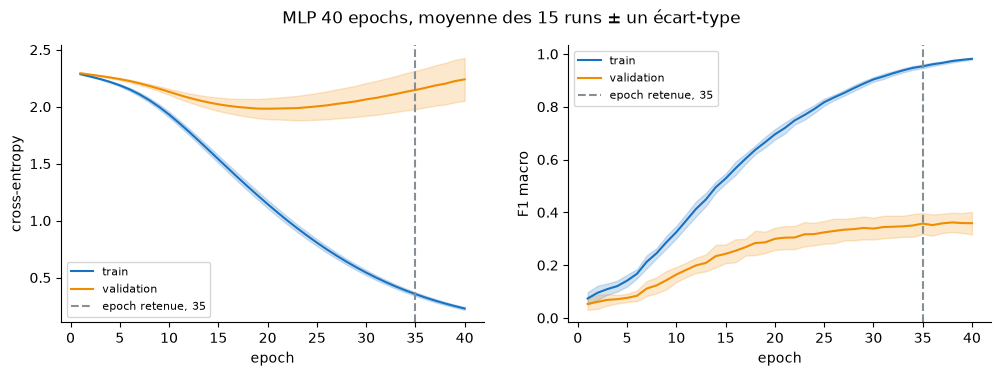

In [29]:
# MLP avec les réglages communs : 40 epochs au plus, cinq folds, trois seeds, soit 15 runs.
evaluer_reseau('MLP 40 epochs', MoyenneMLP)
display(pd.DataFrame([resumer_courbe('MLP 40 epochs')]).set_index('Modèle').round(3).T)
tracer_courbes('MLP 40 epochs')

> *Mes observations :*
>
> Avec 40 epochs, l'epoch retenue est la 35 et le maximum de 0,362 tombe à l'epoch 38, juste avant le plafond. La courbe moyenne de validation gagne encore 0,020 sur les 10 dernières epochs, soit quatre fois ma tolérance de 0,5 point. Le F1 train n'atteint pas encore 1 à l'epoch 40 sur le graphique, donc le MLP apprend toujours. La loss de validation est minimale dès l'epoch 20, puis elle remonte alors que le F1 de validation continue de monter.
>
> *Mes choix :* je relève le plafond du MLP à 100 epochs, et le même critère me dira si 100 suffit. Je garde l'epoch retenue sur le F1 et non sur la loss de validation, car au minimum de cette loss le F1 de validation ne vaut que 0,30.

Modèle,MLP 40 epochs,MLP
Epochs,40,100
Epoch retenue,35,62
Epoch du maximum,38,80
F1 validation maximal,0.362,0.381
Epoch de loss validation minimale,20,20
F1 validation à cette epoch,0.3,0.3
Gain des 10 dernières epochs,0.02,-0.002
Monte encore,True,False


,Paramètres (fold 1),Epoch retenue,F1 train,F1 macro,Écart-type entre folds,Écart-type entre seeds,Écart train/validation,Temps total (s)
Modèle,,,,,,,,
MLP 40 epochs,135370,35,0.953,0.358,0.016,0.041,0.596,25.113
MLP,135370,62,1.000,0.376,0.016,0.031,0.624,61.861


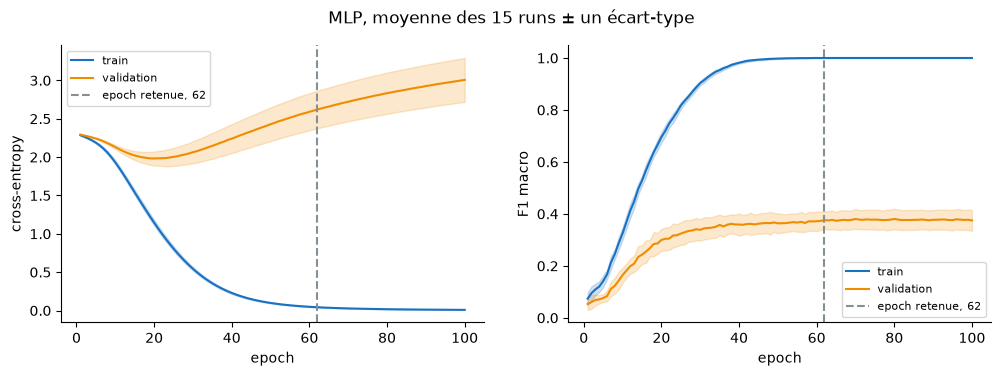

In [30]:
# MLP avec 100 epochs au plus, les autres réglages inchangés, face à la version à 40 epochs.
REGLAGES_MLP = dict(REGLAGES, epochs_max=100)
evaluer_reseau('MLP', MoyenneMLP, REGLAGES_MLP)
noms_mlp = ['MLP 40 epochs', 'MLP']
display(pd.DataFrame([resumer_courbe(nom) for nom in noms_mlp]).set_index('Modèle').round(3).T)
display(pd.DataFrame([ligne_modele(nom) for nom in noms_mlp]).set_index('Modèle').round(3))
tracer_courbes('MLP')

> *Mes observations :*
>
> Avec 100 epochs, l'epoch retenue passe de 35 à 62 et le F1 macro moyen de 0,358 à 0,376. La courbe perd 0,002 sur les 10 dernières epochs, donc 100 epochs suffisent et le plafond ne coupe plus l'apprentissage. À l'epoch retenue, le F1 train vaut 1,000 et l'écart train/validation 0,624. La loss de validation monte de l'epoch 20 à la fin sans que le F1 de validation baisse. J'y lis un MLP de plus en plus confiant dans ses erreurs. L'écart-type entre seeds, 0,031, dépasse l'écart-type entre folds, 0,016, donc l'initialisation pèse plus que le découpage dans le score d'un run. Un run prend environ 4 s.

Je compare le MLP à `LinearSVC commun` fold par fold, car les deux lisent les mêmes tokens. H1 tient si l'écart moyen de F1 macro reste sous 0,05.

In [31]:
# Écart fold par fold entre le MLP et la référence ML, puis les deux résumés.
ecarts_mlp = ecarts_par_fold('LinearSVC commun', 'MLP')
display(ecarts_mlp)
print(decrire_ecarts(ecarts_mlp))
display(pd.concat({nom: resumer(nom) for nom in ('LinearSVC commun', 'MLP')}))

,LinearSVC commun,MLP,Écart
Fold,,,
1,0.453,0.384,-0.069
2,0.423,0.356,-0.068
3,0.472,0.364,-0.108
4,0.518,0.381,-0.138
5,0.509,0.396,-0.112


Folds gagnés par le modèle : 0 sur 5, écart moyen -0.099


F1 train  F1 macro  Accuracy  Temps (s)
LinearSVC commun moyenne          1.0     0.475     0.484      0.058
                 écart-type       0.0     0.039     0.038      0.001
MLP              moyenne          1.0     0.376     0.387      4.124
                 écart-type       0.0     0.016     0.018      0.013

> *Mes observations :*
>
> Le MLP perd les cinq folds face à `LinearSVC commun`, avec des écarts de −0,068 à −0,138 et un écart moyen de −0,099. Son F1 macro vaut 0,376 contre 0,475, donc l'écart vaut presque le double du seuil de 0,05 de H1. Sa dispersion entre folds est plus faible, 0,016 contre 0,039, mais elle ne compense pas ce retard. Un run du MLP prend environ 4 s, contre moins de 0,1 s pour un ajustement de LinearSVC.
>
> *Ma conclusion :* H1 est réfutée sur ce jeu, car ignorer l'ordre des mots ne suffit pas à rejoindre LinearSVC.
>
> *Mon hypothèse :* la moyenne donne le même poids à chaque token, donc les mots fréquents noient les mots rares et discriminants. TF–IDF pondère au contraire chaque terme par sa rareté et lui donne sa propre dimension (section 2.1). Les sections 4.2 et 4.3 testeront cette piste.

H3 prévoit un F1 macro train proche de 1 en moins de 20 epochs, avec un écart train/validation supérieur à 0,3. Je prends 0,99 comme seuil de « proche de 1 » et je cherche dans chaque run la première epoch qui l'atteint. Je mesure ensuite l'écart à l'epoch retenue, fold par fold.

In [32]:
# Mémorisation (H3) : première epoch à F1 train ≥ 0,99 dans chaque run, puis écart par fold.
SEUIL_MEMORISATION = 0.99
EPOCH_H3 = 20  # Délai prévu par H3


def premiere_epoch(courbe: pd.Series, seuil: float) -> float:
    """Première epoch où la courbe atteint le seuil, NaN si elle ne l'atteint jamais."""
    atteintes = courbe.index[courbe >= seuil]
    return atteintes[0] if len(atteintes) else float('nan')


# Délai de mémorisation sur les 15 runs, puis F1 train moyen au délai de H3
premieres = pd.Series([premiere_epoch(run['historique']['F1 train'], SEUIL_MEMORISATION)
                       for run in resultats['MLP']['runs']])
f1_train_h3 = courbes_moyennes('MLP').loc[EPOCH_H3, ('F1 train', 'mean')]

# Écart train/validation à l'epoch retenue, seeds moyennées dans chaque fold
par_fold_mlp = resultats['MLP']['folds'].groupby(level='Fold').mean()
par_fold_mlp['Écart'] = par_fold_mlp['F1 train'] - par_fold_mlp['F1 macro']

print(f'Runs qui atteignent F1 train ≥ {SEUIL_MEMORISATION} : {premieres.notna().sum()} '
      f'sur {len(premieres)}')
print(f'Première epoch : moyenne {premieres.mean():.1f}, de {premieres.min():.0f} '
      f'à {premieres.max():.0f}')
print(f'F1 train moyen à l’epoch {EPOCH_H3} : {f1_train_h3:.3f}')
display(par_fold_mlp[['F1 train', 'F1 macro', 'Écart']].round(3))

Runs qui atteignent F1 train ≥ 0.99 : 15 sur 15
Première epoch : moyenne 43.3, de 41 à 49
F1 train moyen à l’epoch 20 : 0.695


,F1 train,F1 macro,Écart
Fold,,,
1,1.0,0.384,0.616
2,1.0,0.356,0.644
3,1.0,0.364,0.636
4,1.0,0.381,0.619
5,1.0,0.396,0.604


> *Mes observations :*
>
> Les 15 runs atteignent un F1 train de 0,99, mais entre les epochs 41 et 49, à 43,3 en moyenne. À l'epoch 20, le F1 train moyen ne vaut que 0,695. À l'epoch retenue, le F1 train vaut 1 dans chaque fold et l'écart train/validation va de 0,604 à 0,644.
>
> *Ma conclusion :* H3 est en partie réfutée pour le MLP. L'écart dépasse le double de 0,3, donc le MLP mémorise bien le train. Mais il lui faut plus de 40 epochs, soit deux fois le délai prévu.
>
> *Mon hypothèse :* avec une vingtaine de mises à jour par epoch et un taux d'apprentissage de 1e-3, Adam déplace peu chaque poids, donc la mémorisation est lente. Le LSTM de la section 3.5 garde ce réglage, donc il dira si ce délai tient au réglage ou à la moyenne.

Je justifie la largeur 64 en la comparant à 32 et à 128, avec le même plafond de 100 epochs. Je compare le F1 macro, ses deux dispersions et l'écart train/validation.

> *Mon hypothèse :* la largeur change peu le F1 macro, car la couche cachée ne porte que 3,1 % des paramètres et le MLP mémorise déjà le train.

,Paramètres (fold 1),Epoch retenue,F1 train,F1 macro,Écart-type entre folds,Écart-type entre seeds,Écart train/validation,Temps total (s)
Modèle,,,,,,,,
MLP largeur 32,132970,67,0.999,0.387,0.022,0.031,0.612,60.273
MLP,135370,62,1.000,0.376,0.016,0.031,0.624,61.861
MLP largeur 128,140170,70,1.000,0.378,0.044,0.021,0.622,62.649


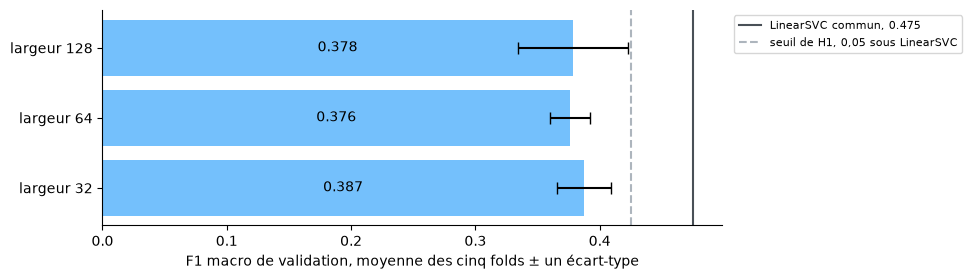

In [33]:
# Largeur de la couche cachée : 32 et 128 face à 64, avec le même plafond de 100 epochs.
LARGEURS = {'MLP largeur 32': 32, 'MLP': 64, 'MLP largeur 128': 128}
for nom, largeur in LARGEURS.items():
    if nom not in resultats:  # La largeur 64 est le MLP déjà entraîné
        evaluer_reseau(nom, MoyenneMLP, dict(REGLAGES_MLP, largeur_cachee=largeur))
table_largeur = pd.DataFrame([ligne_modele(nom) for nom in LARGEURS]).set_index('Modèle')
display(table_largeur.round(3))

# F1 macro par largeur, écart-type entre folds, et la référence ML avec le seuil de H1
f1_svc = score_par_fold('LinearSVC commun').mean()
fig, ax = plt.subplots(figsize=(8, 2.8))
barres = ax.barh([f'largeur {largeur}' for largeur in LARGEURS.values()],
                 table_largeur['F1 macro'],
                 xerr=table_largeur['Écart-type entre folds'], color='#74c0fc', capsize=4)
ax.bar_label(barres, labels=[f'{f1:.3f}' for f1 in table_largeur['F1 macro']],
             label_type='center')
ax.axvline(f1_svc, color='#495057', label=f'LinearSVC commun, {f1_svc:.3f}')
ax.axvline(f1_svc - 0.05, linestyle='--', color='#adb5bd', label='seuil de H1, 0,05 sous LinearSVC')
ax.set_xlabel('F1 macro de validation, moyenne des cinq folds ± un écart-type')
ax.legend(fontsize=8, loc='upper left', bbox_to_anchor=(1.01, 1))
ax.spines[['top', 'right']].set_visible(False)
plt.show()

> *Mes observations :*
>
> Les trois largeurs donnent un F1 macro de 0,376 à 0,387, soit 0,011 d'écart au plus. Cet écart reste sous l'écart-type entre seeds, de 0,021 à 0,031, donc je ne peux pas départager les largeurs. Les paramètres vont de 132 970 à 140 170, soit environ 5 % de variation, car les embeddings dominent. L'écart train/validation reste entre 0,612 et 0,624, donc la largeur ne change pas la mémorisation. Les trois barres restent sous le seuil de H1, et mon hypothèse tient.
>
> *Mes choix :* je garde la largeur 64, car aucune largeur ne sort du bruit des seeds. Elle donne aussi l'écart-type entre folds le plus faible, 0,016, et elle reste la largeur commune du LSTM et du GRU. H4 les comparera donc à largeur égale.

> *Ma conclusion :* le MLP sur la moyenne des embeddings atteint 0,376 ± 0,016 de F1 macro, avec 100 epochs au plus, l'epoch retenue 62 et une largeur de 64. H1 est réfutée, car il reste 0,099 sous `LinearSVC commun` et perd les cinq folds. H3 tient pour l'écart train/validation, d'environ 0,62, mais pas pour le délai, car la mémorisation demande plus de 40 epochs. Trois seeds sont nécessaires, car leur écart-type dépasse celui des folds. Pour le LSTM et le GRU, je pars de 40 epochs et j'applique le même critère de plafond avant toute comparaison.

### 3.5 Embeddings + LSTM

> *Mon hypothèse :* lire la séquence apporte des indices que la moyenne perd, malgré le faible nombre de répliques. Si H2 tient, le LSTM dépasse le MLP et le mélange des mots de la section 4.3 le fait redescendre.

Une couche unidirectionnelle, puis une couche de sortie linéaire à dix scores. Je garde une version bidirectionnelle pour la section 4.3, car classer une réplique entière n'impose aucune contrainte causale. Je regarde les mêmes éléments que pour le MLP, plus la part de répliques tronquées et la norme des gradients.


Le LSTM hérite lui aussi de `ClassifieurTokens`, et sa représentation est l'état après le dernier token réel (section 2.2). J'écris une classe récurrente dont la cellule est un paramètre, donc le GRU de la section 3.6 ne changera que ce paramètre. Je contrôle la sortie et je compare ses paramètres à ceux du MLP.

In [34]:
# Un réseau récurrent à une couche : embeddings, LSTM ou GRU, état final, dix scores de classe.


class ReseauRecurrent(ClassifieurTokens):
    """Une couche récurrente unidirectionnelle, puis l'état après le dernier token réel."""

    def __init__(self, taille_vocabulaire: int, reglages: dict, cellule: type = nn.LSTM):
        super().__init__(taille_vocabulaire, reglages, reglages['largeur_cachee'])
        self.rnn = cellule(reglages['dim_embedding'], reglages['largeur_cachee'], batch_first=True)

    def representer(self, vecteurs, masque, longueurs):
        return etat_final(self.rnn, vecteurs, longueurs)


# Contrôle sur les quatre répliques du fold 1 : forme de la sortie, puis paramètres face au MLP
fixer_seed(RANDOM_STATE)
lstm_1 = ReseauRecurrent(len(vocabulaire_1), REGLAGES).to(device)
with torch.no_grad():
    print(f'Sortie sur 4 répliques : forme {tuple(lstm_1(batch_1).shape)}')
blocs = pd.DataFrame({'MLP': parametres_par_bloc(mlp_1), 'LSTM': parametres_par_bloc(lstm_1)})
blocs = blocs.fillna(0).astype(int)
blocs.loc['total'] = blocs.sum()
display(blocs.rename_axis('Bloc, fold 1'))

Sortie sur 4 répliques : forme (4, 10)


,MLP,LSTM
"Bloc, fold 1",,
embeddings,130560,130560
sortie,650,650
cachee,4160,0
rnn,0,33280
total,135370,164490


> *Mes observations :*
>
> Le LSTM rend aussi dix scores par réplique. Sa couche récurrente compte 33 280 paramètres, soit huit fois la couche cachée du MLP. Elle calcule en effet trois portes et une mémoire candidate, chacune à partir du token et de l'état précédent. Les embeddings restent identiques, donc le LSTM passe de 135 370 à 164 490 paramètres sur le fold 1.

Je lance le LSTM avec les réglages communs, donc 40 epochs au plus et 15 runs. Puis j'applique le critère de plafond de la section 3.4 avant de lire ses scores.

Modèle,MLP,LSTM
Epochs,100,40
Epoch retenue,62,27
Epoch du maximum,80,27
F1 validation maximal,0.381,0.206
Epoch de loss validation minimale,20,6
F1 validation à cette epoch,0.3,0.116
Gain des 10 dernières epochs,-0.002,0.004
Monte encore,False,False


,Paramètres (fold 1),Epoch retenue,F1 train,F1 macro,Écart-type entre folds,Écart-type entre seeds,Écart train/validation,Temps total (s)
Modèle,,,,,,,,
MLP,135370,62,1.000,0.376,0.016,0.031,0.624,61.861
LSTM,164490,27,0.998,0.206,0.026,0.024,0.792,483.245


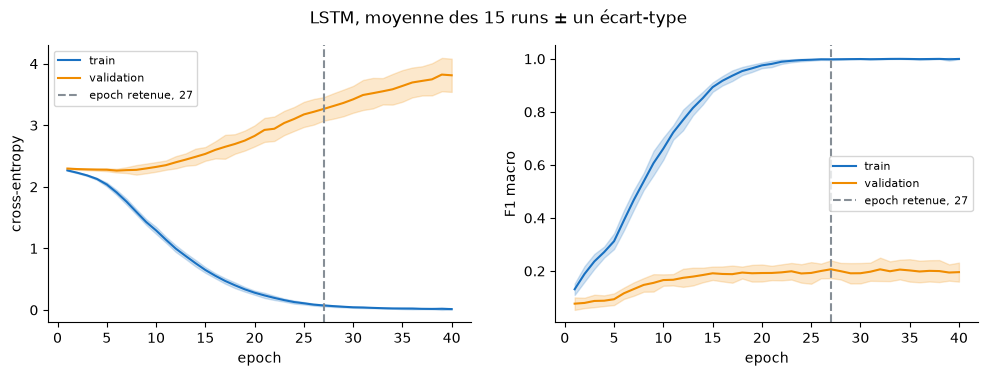

In [35]:
# LSTM avec les réglages communs : 40 epochs au plus, cinq folds, trois seeds.
evaluer_reseau('LSTM', ReseauRecurrent)
noms_reseaux = ['MLP', 'LSTM']
display(pd.DataFrame([resumer_courbe(nom) for nom in noms_reseaux]).set_index('Modèle').round(3).T)
display(pd.DataFrame([ligne_modele(nom) for nom in noms_reseaux]).set_index('Modèle').round(3))
tracer_courbes('LSTM')

> *Mes observations :*
>
> L'epoch retenue du LSTM est la 27, et son maximum de 0,206 tombe à la même epoch. La courbe ne gagne que 0,004 sur les 10 dernières epochs, sous ma tolérance de 0,005, donc elle ne monte plus au plafond. Le F1 macro vaut 0,206 contre 0,376 pour le MLP, avec un écart train/validation de 0,792 contre 0,624. La loss de validation est minimale dès l'epoch 6, puis elle monte jusqu'à la fin, alors que le F1 de validation plafonne vers 0,20 dès l'epoch 15. Les 15 runs prennent environ sept fois le temps du MLP, pour moins de la moitié des epochs.
>
> *Mes choix :* je garde le plafond de 40 epochs pour le LSTM, car le critère de la section 3.4 ne se déclenche pas. Le GRU de la section 3.6 partira du même plafond.

Je compare le LSTM au MLP fold par fold, car H2 prévoit que lire l'ordre des mots le fait passer devant. Je le place aussi face à `LinearSVC commun`, la référence ML.

In [36]:
# Écarts fold par fold du LSTM face au MLP (H2), puis face à la référence ML.
for reference in ('MLP', 'LinearSVC commun'):
    ecarts_lstm = ecarts_par_fold(reference, 'LSTM')
    display(ecarts_lstm)
    print(decrire_ecarts(ecarts_lstm))

,MLP,LSTM,Écart
Fold,,,
1,0.384,0.217,-0.167
2,0.356,0.189,-0.167
3,0.364,0.226,-0.138
4,0.381,0.171,-0.210
5,0.396,0.229,-0.167


Folds gagnés par le modèle : 0 sur 5, écart moyen -0.170


,LinearSVC commun,LSTM,Écart
Fold,,,
1,0.453,0.217,-0.236
2,0.423,0.189,-0.234
3,0.472,0.226,-0.245
4,0.518,0.171,-0.348
5,0.509,0.229,-0.279


Folds gagnés par le modèle : 0 sur 5, écart moyen -0.268


> *Mes observations :*
>
> Le LSTM perd les cinq folds face au MLP, avec des écarts de −0,138 à −0,210 et un écart moyen de −0,170. Face à `LinearSVC commun`, il perd aussi les cinq folds, avec un écart moyen de −0,268.
>
> *Ma conclusion :* mon hypothèse de cette section est réfutée, car lire la séquence ne fait pas passer le LSTM devant le MLP. H2 reste ouverte, car un LSTM peut échouer par manque de données même si l'ordre porte un signal. Le mélange des mots et la quantité de données de la section 4.3 trancheront.

Dans la section 3.4, le MLP a mis plus de 40 epochs à mémoriser le train, et je me demandais si ce délai venait du réglage ou de la moyenne. Le LSTM garde le même réglage, donc je compare les deux délais et les deux écarts train/validation.

In [37]:
# Mémorisation (H3) du MLP et du LSTM : délai pour atteindre un F1 train de 0,99, écart final.


def ligne_memorisation(nom: str) -> dict:
    """Première epoch à F1 train ≥ 0,99 sur les runs, F1 train à l'epoch 20, écart retenu."""
    premieres = pd.Series([premiere_epoch(run['historique']['F1 train'], SEUIL_MEMORISATION)
                           for run in resultats[nom]['runs']])
    f1_h3 = courbes_moyennes(nom).loc[EPOCH_H3, ('F1 train', 'mean')]
    par_fold = resultats[nom]['folds'].groupby(level='Fold').mean()
    return {'Modèle': nom, 'Runs au seuil': f'{premieres.notna().sum()} sur {len(premieres)}',
            'Première epoch moyenne': premieres.mean(), 'Première epoch minimale': premieres.min(),
            'Première epoch maximale': premieres.max(), f'F1 train à l’epoch {EPOCH_H3}': f1_h3,
            'Écart train/validation': (par_fold['F1 train'] - par_fold['F1 macro']).mean()}


memorisation = pd.DataFrame([ligne_memorisation(nom) for nom in noms_reseaux])
display(memorisation.set_index('Modèle').round(3))

,Runs au seuil,Première epoch moyenne,Première epoch minimale,Première epoch maximale,F1 train à l’epoch 20,Écart train/validation
Modèle,,,,,,
MLP,15 sur 15,43.267,41,49,0.695,0.624
LSTM,15 sur 15,22.667,21,26,0.975,0.792


> *Mes observations :*
>
> Le LSTM atteint un F1 train de 0,99 entre les epochs 21 et 26, à 22,7 en moyenne, contre 43,3 pour le MLP. À l'epoch 20, son F1 train moyen vaut déjà 0,975 contre 0,695. Son écart train/validation à l'epoch retenue vaut 0,792 contre 0,624.
>
> *Ma conclusion :* H3 tient presque pour le LSTM. Il est proche de 1 dans le délai de 20 epochs, puis le seuil de 0,99 arrive une à six epochs plus tard, avec un écart bien au-dessus de 0,3. Le réglage est le même pour les deux réseaux, donc la mémorisation lente du MLP venait de la moyenne et non du réglage commun. Mon hypothèse de la section 3.4 est donc réfutée.

Le gradient plafonné à 1 protège les réseaux récurrents des gradients qui explosent (section 3.1). Je regarde donc, epoch par epoch, la norme du gradient avant plafonnement et la part des batches plafonnés, pour le MLP et le LSTM.

MLP : norme maximale 2.3, pic de la norme moyenne à l’epoch 21, 1.2 % des batches plafonnés
LSTM : norme maximale 413.5, pic de la norme moyenne à l’epoch 22, 51.2 % des batches plafonnés


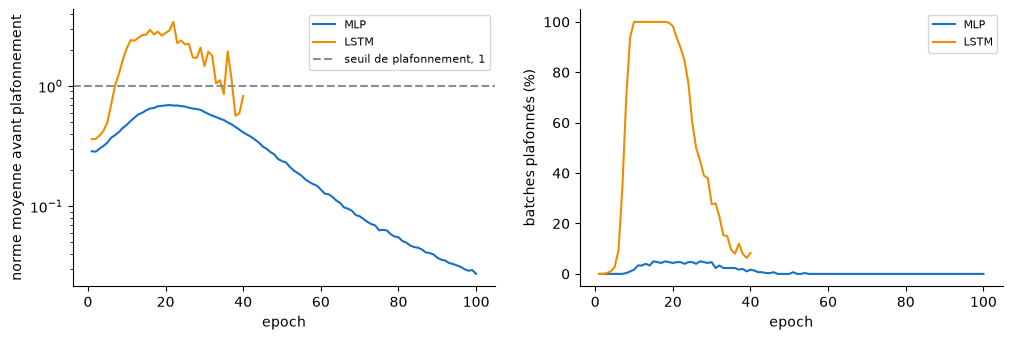

In [38]:
# Norme du gradient avant plafonnement et part des batches plafonnés, MLP face au LSTM.
COULEURS = {'LinearSVC commun': '#868e96', 'MLP': '#1971c2', 'LSTM': '#f08c00', 'GRU': '#2f9e44'}


def decrire_gradient(nom: str) -> str:
    """Norme maximale, epoch du pic de la norme moyenne et part des batches plafonnés."""
    courbes = courbes_moyennes(nom)
    historiques = pd.concat([run['historique'] for run in resultats[nom]['runs']])
    return (f'{nom} : norme maximale {historiques["norme maximale"].max():.1f}, pic de la norme '
            f'moyenne à l’epoch {courbes[("norme moyenne", "mean")].idxmax()}, '
            f'{pourcentage(historiques["part plafonnée"].sum(), len(historiques)):.1f} % '
            f'des batches plafonnés')


def tracer_gradients(noms: list) -> None:
    """Norme moyenne avant plafonnement, en échelle log, et part des batches plafonnés."""
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
    for nom in noms:
        courbes = courbes_moyennes(nom)
        axes[0].plot(courbes.index, courbes[('norme moyenne', 'mean')], color=COULEURS[nom],
                     label=nom)
        axes[1].plot(courbes.index, 100 * courbes[('part plafonnée', 'mean')],
                     color=COULEURS[nom], label=nom)
    axes[0].axhline(REGLAGES['clip_gradient'], linestyle='--', color='#868e96',
                    label='seuil de plafonnement, 1')
    axes[0].set(yscale='log', ylabel='norme moyenne avant plafonnement')
    axes[1].set(ylabel='batches plafonnés (%)')
    for axe in axes:
        axe.set_xlabel('epoch')
        axe.legend(fontsize=8)
        axe.spines[['top', 'right']].set_visible(False)
    plt.show()


# Une ligne de résumé par réseau, puis les deux panneaux
for nom in noms_reseaux:
    print(decrire_gradient(nom))
tracer_gradients(noms_reseaux)

> *Mes observations :*
>
> La norme moyenne du gradient du LSTM dépasse le seuil de 1 vers l'epoch 8 et culmine à l'epoch 22, avec une norme maximale de 413,5 sur un batch. Entre les epochs 10 et 20, presque tous ses batches sont plafonnés, et 51,2 % le sont sur tout l'entraînement. Le gradient du MLP reste sous le seuil en moyenne, avec un maximum de 2,3 et 1,2 % de batches plafonnés.
>
> *Ma conclusion :* le plafonnement agit surtout sur le LSTM, pendant les epochs où il mémorise le train. Ces pics sont le signe de gradients qui explosent dans la récurrence, donc je garde le plafonnement pour le GRU. Je n'ai pas entraîné de LSTM sans plafonnement, donc son effet sur le score reste une hypothèse.

Un état final peut oublier le début d'une réplique longue, alors que la moyenne et TF–IDF voient tous les tokens. Je coupe les 769 répliques de validation en trois tranches de longueur de même effectif, puis je compare l'accuracy des trois modèles dans chaque tranche. Je rappelle aussi la part de répliques tronquées par la longueur maximale.

In [39]:
# Accuracy par tranche de longueur pour LinearSVC commun, MLP et LSTM, puis répliques tronquées.
NOMS_LONGUEUR = ['LinearSVC commun', 'MLP', 'LSTM']
longueurs = X_train.map(lambda texte: len(tokeniser(texte)))
tranches = pd.qcut(longueurs, 3)  # Trois tranches de même effectif


def predictions_seed(nom: str, seed: int) -> pd.Series:
    """Prédictions de validation des cinq folds pour une seed, à l'epoch retenue."""
    epoch, predictions = resultats[nom]['epoch'], pd.Series(index=X_train.index, dtype=object)
    for run in resultats[nom]['runs']:
        if run['seed'] == seed:
            validation = folds[run['fold'] - 1]['validation']
            predictions.loc[validation] = [CLASSES[i] for i in run['predictions'][epoch]]
    return predictions


def justesse_par_tranche(nom: str) -> pd.Series:
    """Accuracy par tranche de longueur, moyennée sur les seeds pour un réseau."""
    if resultats[nom]['famille'] == 'ML':
        jeux = [resultats[nom]['predictions']]
    else:
        jeux = [predictions_seed(nom, seed) for seed in REGLAGES['seeds']]
    justes = pd.concat([jeu == y_train for jeu in jeux], axis=1).mean(axis=1)
    return justes.groupby(tranches, observed=True).mean()


def table_justesse(noms: list) -> pd.DataFrame:
    """Accuracy par tranche de longueur, une colonne par modèle."""
    table = pd.DataFrame({nom: justesse_par_tranche(nom) for nom in noms})
    table.index = [f'{int(t.left) + 1} à {int(t.right)} tokens' for t in table.index]
    return table


# Accuracy par tranche, effectifs, puis répliques de validation tronquées par fold
justesse = table_justesse(NOMS_LONGUEUR)
tronquees = [mesurer_troncature(fold, QUANTILE_LONGUEUR)['Répliques tronquées validation (%)']
             for fold in folds]
print(f'Répliques par tranche : {tranches.value_counts().sort_index().tolist()}')
print(f'Répliques de validation tronquées : de {min(tronquees):.2f} % à {max(tronquees):.2f} % '
      f'selon le fold')
display(justesse.round(3))

Répliques par tranche : [259, 261, 249]
Répliques de validation tronquées : de 0.00 % à 2.61 % selon le fold


,LinearSVC commun,MLP,LSTM
10 à 20 tokens,0.375,0.308,0.223
21 à 47 tokens,0.494,0.379,0.206
48 à 581 tokens,0.586,0.477,0.221


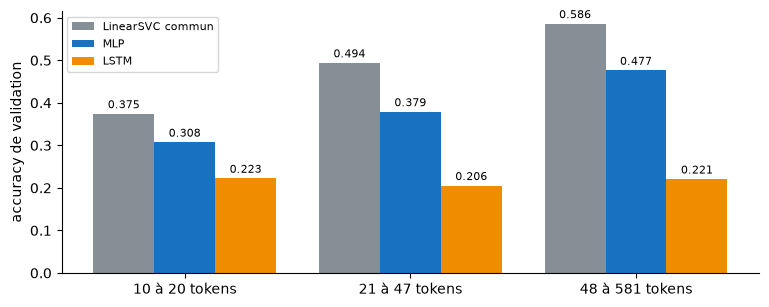

In [40]:
# Accuracy de validation par tranche de longueur, un groupe de barres par tranche.


def tracer_justesse(justesse: pd.DataFrame) -> None:
    """Un groupe de barres par tranche, une barre par modèle, valeurs sur les barres."""
    largeur, positions = 0.81 / justesse.shape[1], np.arange(len(justesse))
    fig, ax = plt.subplots(figsize=(9, 3.4))
    for rang, nom in enumerate(justesse):
        decalage = (rang - (justesse.shape[1] - 1) / 2) * largeur  # Barres centrées sur la tranche
        barres = ax.bar(positions + decalage, justesse[nom], largeur, color=COULEURS[nom],
                        label=nom)
        ax.bar_label(barres, labels=[f'{valeur:.3f}' for valeur in justesse[nom]], padding=2,
                     fontsize=8)
    ax.set_xticks(positions, justesse.index)
    ax.set_ylabel('accuracy de validation')
    ax.legend(fontsize=8)
    ax.spines[['top', 'right']].set_visible(False)
    plt.show()


tracer_justesse(justesse)

> *Mes observations :*
>
> Les trois tranches comptent 259, 261 et 249 répliques. Des répliques courtes aux longues, LinearSVC passe de 0,375 à 0,586 d'accuracy et le MLP de 0,308 à 0,477. Le LSTM reste entre 0,206 et 0,223 dans les trois tranches. La troncature touche au plus 2,61 % des répliques de validation d'un fold, donc elle n'explique pas ce plat.
>
> *Ma conclusion :* les modèles qui voient tous les tokens profitent des répliques longues, mais pas le LSTM. Il reste pourtant aussi faible sur les répliques de 10 à 20 tokens, où l'oubli du début joue peu. Son retard vient donc d'abord de ce qu'il apprend sur 615 répliques, et l'oubli explique au mieux l'absence de gain sur les répliques longues. Le LSTM bidirectionnel et la quantité de données de la section 4.3 testeront ces deux pistes.

> *Ma conclusion :* le LSTM atteint 0,206 ± 0,026 de F1 macro à l'epoch 27, soit 0,170 sous le MLP et 0,268 sous `LinearSVC commun`, et il perd tous les folds. Il mémorise le train en une vingtaine d'epochs, avec un écart de 0,792, donc il apprend les répliques plutôt que des indices qui généralisent. Ses gradients explosent pendant cette phase, et la moitié des batches sont plafonnés. Son accuracy reste plate quelle que soit la longueur de la réplique. Pour le GRU, je garde les mêmes réglages et le plafond de 40 epochs, puis H4 comparera son coût et son score à ceux du LSTM.

### 3.6 Embeddings + GRU face au LSTM

> *Mon hypothèse :* le GRU suffit pour nos répliques avec moins de paramètres qu'un LSTM de même largeur (H4), donc je compare résultats et coût avant de choisir.

Même couche unidirectionnelle, même dimension d'embedding, même largeur cachée et même couche de sortie que le LSTM. Tokenisation, vocabulaire, initialisation des embeddings et réglages restent communs, donc seuls les poids diffèrent. Une largeur égale ne donne pas un nombre de paramètres égal, donc je les compte, puis je compare F1 macro, dispersion, temps et écart train/validation, fold par fold face au LSTM.


Le GRU reprend la classe `ReseauRecurrent` de la section 3.5 avec une autre cellule, donc tout le reste du réseau est commun. Je vérifie qu'à seed égale ses embeddings et sa couche de sortie partent des mêmes poids que ceux du LSTM. Puis je compte ses paramètres par bloc.

In [41]:
# Le GRU : la classe récurrente de la section 3.5 avec une cellule GRU, contrôlée sur le fold 1.
GRU = partial(ReseauRecurrent, cellule=nn.GRU)

# Même seed que lstm_1 : les blocs communs doivent partir des mêmes poids
fixer_seed(RANDOM_STATE)
gru_1 = GRU(len(vocabulaire_1), REGLAGES).to(device)
with torch.no_grad():
    print(f'Sortie sur 4 répliques : forme {tuple(gru_1(batch_1).shape)}')
for bloc in ('embeddings', 'sortie'):
    paires = zip(getattr(lstm_1, bloc).parameters(), getattr(gru_1, bloc).parameters())
    print(f'{bloc} identiques au LSTM : {all(torch.equal(a, b) for a, b in paires)}')

# Paramètres par bloc, LSTM face au GRU
blocs = pd.DataFrame({'LSTM': parametres_par_bloc(lstm_1), 'GRU': parametres_par_bloc(gru_1)})
blocs.loc['total'] = blocs.sum()
display(blocs.rename_axis('Bloc, fold 1'))

Sortie sur 4 répliques : forme (4, 10)
embeddings identiques au LSTM : True
sortie identiques au LSTM : True


,LSTM,GRU
"Bloc, fold 1",,
embeddings,130560,130560
sortie,650,650
rnn,33280,24960
total,164490,156170


> *Mes observations :*
>
> À seed égale, les embeddings et la couche de sortie du GRU sont identiques à ceux du LSTM, donc seuls les poids récurrents diffèrent au départ. La couche GRU compte 24 960 paramètres contre 33 280, soit les trois quarts. Elle calcule en effet deux portes et un état candidat, au lieu de trois portes et une mémoire candidate. Le GRU passe donc à 156 170 paramètres sur le fold 1, soit 5 % de moins que le LSTM.

Je lance le GRU avec les mêmes réglages que le LSTM, donc 40 epochs au plus et 15 runs. Puis j'applique le critère de plafond de la section 3.4.

Modèle,LSTM,GRU
Epochs,40,40
Epoch retenue,27,31
Epoch du maximum,27,31
F1 validation maximal,0.206,0.206
Epoch de loss validation minimale,6,8
F1 validation à cette epoch,0.116,0.146
Gain des 10 dernières epochs,0.004,0.001
Monte encore,False,False


,Paramètres (fold 1),Epoch retenue,F1 train,F1 macro,Écart-type entre folds,Écart-type entre seeds,Écart train/validation,Temps total (s)
Modèle,,,,,,,,
MLP,135370,62,1.000,0.376,0.016,0.031,0.624,61.861
LSTM,164490,27,0.998,0.206,0.026,0.024,0.792,483.245
GRU,156170,31,1.000,0.206,0.027,0.022,0.794,465.391


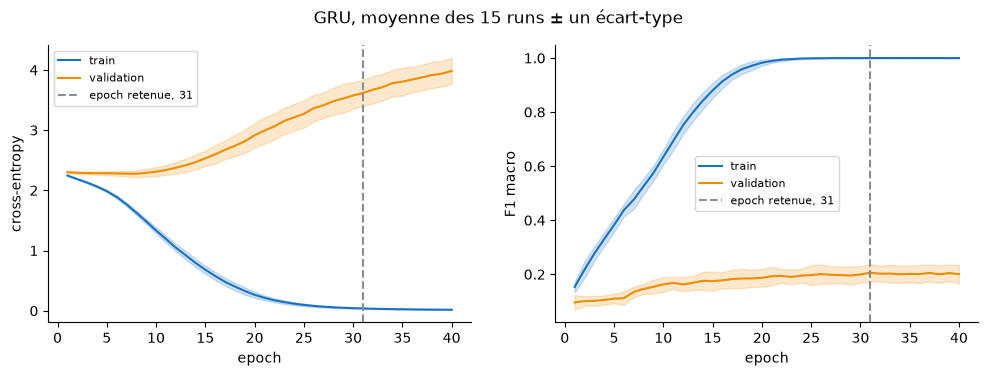

In [42]:
# GRU avec les réglages communs : 40 epochs au plus, cinq folds, trois seeds.
evaluer_reseau('GRU', GRU)
RESEAUX = ['MLP', 'LSTM', 'GRU']
display(pd.DataFrame([resumer_courbe(nom) for nom in RESEAUX[1:]]).set_index('Modèle').round(3).T)
display(pd.DataFrame([ligne_modele(nom) for nom in RESEAUX]).set_index('Modèle').round(3))
tracer_courbes('GRU')

> *Mes observations :*
>
> L'epoch retenue du GRU est la 31, où il atteint son maximum de 0,206, le même que le LSTM. Sa courbe ne gagne que 0,001 sur les 10 dernières epochs, donc elle ne monte plus au plafond. Son écart train/validation vaut 0,794 contre 0,792 pour le LSTM, et sa loss de validation remonte dès l'epoch 8. Ses écarts-types entre folds et entre seeds, 0,027 et 0,022, sont proches de ceux du LSTM, 0,026 et 0,024.
>
> *Mes choix :* je garde 40 epochs pour le GRU, car le critère de plafond ne se déclenche pas.

H4 compare le GRU au LSTM sur trois points, les paramètres, le temps et le F1 macro. Je juge deux F1 comparables si leur écart moyen reste sous l'écart-type entre seeds, comme pour les largeurs de la section 3.4. Je mesure le temps par epoch, évaluation comprise, car le temps total dépend du plafond.

In [43]:
# H4 : écart fold par fold du GRU face au LSTM, puis temps d'une epoch et taille de chaque réseau.


def temps_par_epoch(nom: str) -> float:
    """Temps total des runs divisé par leur nombre total d'epochs, évaluation comprise."""
    runs = resultats[nom]['runs']
    return sum(run['temps'] for run in runs) / sum(len(run['historique']) for run in runs)


ecarts_gru = ecarts_par_fold('LSTM', 'GRU')
display(ecarts_gru)
print(decrire_ecarts(ecarts_gru))
for nom in RESEAUX:
    print(f'{nom} : {temps_par_epoch(nom):.2f} s par epoch, '
          f'{resultats[nom]["parametres"]} paramètres sur le fold 1')

,LSTM,GRU,Écart
Fold,,,
1,0.217,0.212,-0.005
2,0.189,0.190,0.001
3,0.226,0.242,0.016
4,0.171,0.170,-0.000
5,0.229,0.214,-0.015


Folds gagnés par le modèle : 2 sur 5, écart moyen -0.001
MLP : 0.04 s par epoch, 135370 paramètres sur le fold 1
LSTM : 0.81 s par epoch, 164490 paramètres sur le fold 1
GRU : 0.78 s par epoch, 156170 paramètres sur le fold 1


> *Mes observations :*
>
> Le GRU gagne deux folds sur cinq face au LSTM, avec des écarts de −0,015 à +0,016 et un écart moyen de −0,001. Cet écart reste très en dessous de l'écart-type entre seeds du GRU, 0,022, donc les deux F1 sont comparables. Une epoch prend environ 0,8 s pour le GRU comme pour le LSTM, évaluation comprise, contre 0,04 s pour le MLP.
>
> *Ma conclusion :* H4 tient pour les paramètres et pour le F1 macro, mais pas pour le temps. Le GRU a 5 % de paramètres en moins pour le même score, alors que son epoch dure presque autant que celle du LSTM.
>
> *Mon hypothèse :* le temps vient surtout du parcours token par token, commun aux deux cellules, plus que du nombre de portes.

Je reprends la mémorisation de la section 3.5 avec le GRU, car H3 vaut pour les trois réseaux.

In [44]:
# Mémorisation (H3) des trois réseaux : délai pour un F1 train de 0,99 et écart final.
display(pd.DataFrame([ligne_memorisation(nom) for nom in RESEAUX]).set_index('Modèle').round(3))

,Runs au seuil,Première epoch moyenne,Première epoch minimale,Première epoch maximale,F1 train à l’epoch 20,Écart train/validation
Modèle,,,,,,
MLP,15 sur 15,43.267,41,49,0.695,0.624
LSTM,15 sur 15,22.667,21,26,0.975,0.792
GRU,15 sur 15,21.467,19,24,0.983,0.794


> *Mes observations :*
>
> Le GRU atteint un F1 train de 0,99 entre les epochs 19 et 24, à 21,5 en moyenne, contre 22,7 pour le LSTM et 43,3 pour le MLP. À l'epoch 20, son F1 train moyen vaut 0,983. Son écart train/validation, 0,794, égale presque celui du LSTM.
>
> *Ma conclusion :* H3 tient presque pour les deux réseaux récurrents. Ils sont proches de 1 à l'epoch 20, puis au seuil de 0,99 vers l'epoch 22, avec un écart proche de 0,8. Seul le MLP, ralenti par la moyenne, mémorise nettement plus tard.

Le LSTM a plafonné la moitié de ses batches dans la section 3.5. Le GRU a une porte de moins et pas de mémoire séparée de son état, donc je regarde si ses gradients explosent moins.

MLP : norme maximale 2.3, pic de la norme moyenne à l’epoch 21, 1.2 % des batches plafonnés
LSTM : norme maximale 413.5, pic de la norme moyenne à l’epoch 22, 51.2 % des batches plafonnés
GRU : norme maximale 101.9, pic de la norme moyenne à l’epoch 19, 28.2 % des batches plafonnés


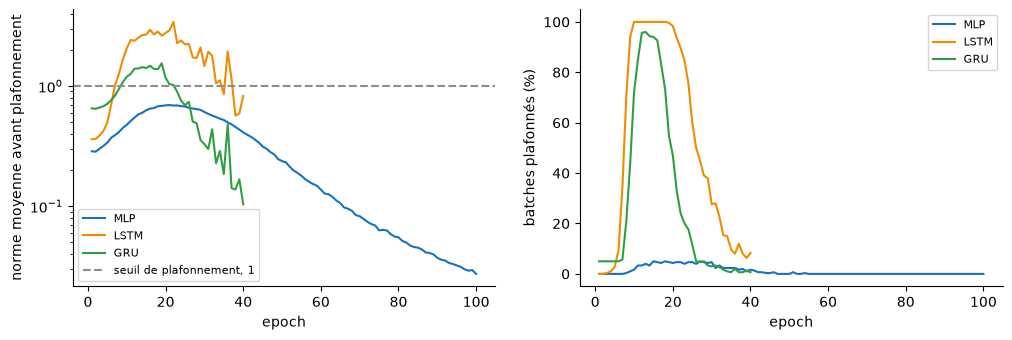

In [45]:
# Norme du gradient avant plafonnement et part des batches plafonnés pour les trois réseaux.
for nom in RESEAUX:
    print(decrire_gradient(nom))
tracer_gradients(RESEAUX)

> *Mes observations :*
>
> Le GRU plafonne 28,2 % de ses batches contre 51,2 % pour le LSTM, et sa norme maximale vaut 101,9 contre 413,5. Sa norme moyenne dépasse aussi le seuil de 1, mais elle culmine plus bas et plus tôt, à l'epoch 19 contre 22. Ses batches plafonnés montent presque à 100 % vers l'epoch 13, puis retombent plus vite que ceux du LSTM.
>
> *Ma conclusion :* les gradients du GRU explosent moins que ceux du LSTM, mais le plafonnement reste utile pendant sa phase de mémorisation.

Le LSTM restait plat quelle que soit la longueur des répliques (section 3.5). Je place le GRU dans le même graphique, pour voir s'il partage ce profil.

,LinearSVC commun,MLP,LSTM,GRU
10 à 20 tokens,0.375,0.308,0.223,0.218
21 à 47 tokens,0.494,0.379,0.206,0.209
48 à 581 tokens,0.586,0.477,0.221,0.213


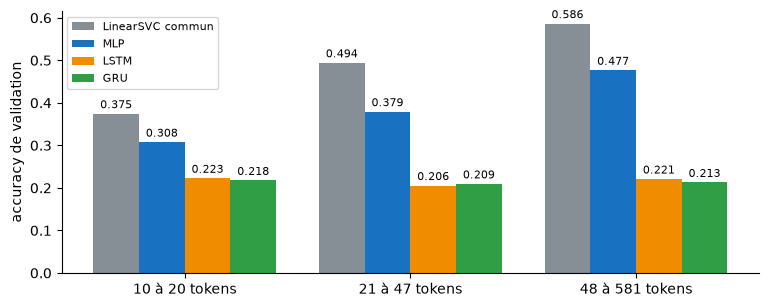

In [46]:
# Accuracy par tranche de longueur avec le GRU, face aux trois modèles de la section 3.5.
justesse_gru = table_justesse(NOMS_LONGUEUR + ['GRU'])
display(justesse_gru.round(3))
tracer_justesse(justesse_gru)

> *Mes observations :*
>
> Le GRU reste entre 0,209 et 0,218 d'accuracy dans les trois tranches, comme le LSTM entre 0,206 et 0,223. Des répliques courtes aux longues, LinearSVC gagne 0,211 et le MLP 0,169.
>
> *Ma conclusion :* les deux réseaux récurrents partagent le même profil plat, donc leur retard ne tient pas au type de cellule.

> *Ma conclusion :* le GRU atteint 0,206 ± 0,027 de F1 macro à l'epoch 31, le même score que le LSTM. Il a 5 % de paramètres en moins, pour le même temps par epoch. H4 tient donc pour les paramètres et le score, mais pas pour la vitesse. Les deux réseaux récurrents restent 0,17 sous le MLP et environ 0,27 sous `LinearSVC commun`. Ils mémorisent le train vers l'epoch 22 et ne profitent pas des répliques longues.
>
> *Mes choix :* le GRU représente les réseaux récurrents dans la section 4, car il égale le LSTM avec moins de paramètres et des gradients plus stables.

## 4. Évaluation, erreurs et conclusions

### 4.1 Comparer la généralisation

Je rassemble accuracy et F1 macro par fold, puis moyenne et écart-type. La dispersion décrit cinq scores, mais elle ne constitue pas un test de significativité.

Je compare les modèles sur les mêmes répliques. D'abord par la différence de F1 macro fold par fold entre chaque réseau et LinearSVC, avec son signe. Puis par le nombre de répliques où un modèle a raison et l'autre tort, sur les 769 prédictions de validation. Je lis les courbes train/validation et jamais le score train seul, puis les métriques par classe, les paramètres et le temps total. Chaque matrice de confusion est commentée.


Je rassemble d'abord les six modèles des sections 3.2 à 3.6 dans un seul tableau. Pour chacun, je reprends F1 macro et accuracy moyens, leur écart-type entre folds, l'epoch retenue, la taille et le temps total. Je compte aussi les poids de LinearSVC sur le fold 1, un par terme et par classe, pour comparer les tailles.

In [47]:
# Bilan des six modèles : F1 macro et accuracy entre folds, epoch retenue, taille et temps total.
MODELES = ['Majoritaire', 'LinearSVC TP1', 'LinearSVC commun', 'MLP', 'LSTM', 'GRU']


def poids_svc(reference: str) -> int:
    """Poids de LinearSVC ajusté sur le train du fold 1, un par terme et par classe."""
    fold = folds[0]
    svc = construire_svc(reference).fit(X_train.loc[fold['train']], y_train.loc[fold['train']])
    return svc.named_steps['svc'].coef_.size + svc.named_steps['svc'].intercept_.size


def ligne_bilan(nom: str) -> dict:
    """Scores moyens et écarts-types entre folds, seeds moyennées, puis epoch, taille et temps."""
    entree = resultats[nom]
    par_fold = entree['folds'].groupby(level='Fold').mean()
    return {'Modèle': nom, 'Famille': entree['famille'], 'F1 train': par_fold['F1 train'].mean(),
            'F1 macro': par_fold['F1 macro'].mean(), 'F1 écart-type': par_fold['F1 macro'].std(),
            'Accuracy': par_fold['Accuracy'].mean(),
            'Accuracy écart-type': par_fold['Accuracy'].std(),
            'Epoch retenue': entree.get('epoch'), 'Paramètres (fold 1)': entree.get('parametres'),
            'Temps total (s)': entree['folds']['Temps (s)'].sum()}


# Paramètres de LinearSVC, absents du registre ML
for nom, reference in REFERENCES.items():
    resultats[nom]['parametres'] = poids_svc(reference)

# Tableau de bilan, puis F1 macro par fold
bilan = pd.DataFrame([ligne_bilan(nom) for nom in MODELES]).set_index('Modèle')
bilan = bilan.astype({'Epoch retenue': 'Int64', 'Paramètres (fold 1)': 'Int64'})
f1_par_fold = pd.DataFrame({nom: score_par_fold(nom) for nom in MODELES})
display(bilan.round(3))
display(f1_par_fold.round(3))

,Famille,F1 train,F1 macro,F1 écart-type,Accuracy,Accuracy écart-type,Epoch retenue,Paramètres (fold 1),Temps total (s)
Modèle,,,,,,,,,
Majoritaire,ML,0.024,0.024,0.001,0.134,0.003,<NA>,<NA>,0.020
LinearSVC TP1,ML,1.000,0.482,0.039,0.492,0.041,<NA>,48620,0.379
LinearSVC commun,ML,1.000,0.475,0.039,0.484,0.038,<NA>,50260,0.290
MLP,DL,1.000,0.376,0.016,0.387,0.018,62,135370,61.861
LSTM,DL,0.998,0.206,0.026,0.216,0.024,27,164490,483.245
GRU,DL,1.000,0.206,0.027,0.213,0.026,31,156170,465.391


,Majoritaire,LinearSVC TP1,LinearSVC commun,MLP,LSTM,GRU
Fold,,,,,,
1,0.024,0.453,0.453,0.384,0.217,0.212
2,0.024,0.429,0.423,0.356,0.189,0.190
3,0.024,0.500,0.472,0.364,0.226,0.242
4,0.023,0.511,0.518,0.381,0.171,0.170
5,0.023,0.517,0.509,0.396,0.229,0.214


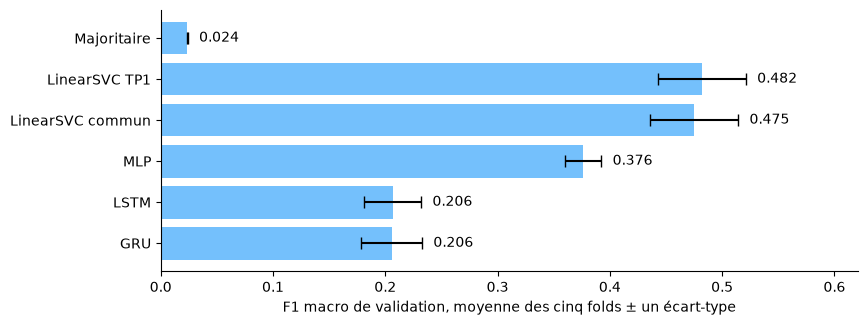

In [48]:
# F1 macro moyen de chaque modèle, avec l'écart-type entre folds.
fig, ax = plt.subplots(figsize=(9, 3.4))
moyennes, ecarts = bilan['F1 macro'][::-1], bilan['F1 écart-type'][::-1]
ax.barh(moyennes.index, moyennes, xerr=ecarts, color='#74c0fc', capsize=4)
for rang, (moyenne, ecart) in enumerate(zip(moyennes, ecarts)):
    ax.text(moyenne + ecart + 0.01, rang, f'{moyenne:.3f}', va='center')
ax.set_xlim(0, (moyennes + ecarts).max() + 0.1)
ax.set_xlabel('F1 macro de validation, moyenne des cinq folds ± un écart-type')
ax.spines[['top', 'right']].set_visible(False)
plt.show()

> *Mes observations :*
>
> LinearSVC reste en tête, avec 0,482 pour le découpage du TP1 et 0,475 pour le tokenizer commun. Le MLP suit à 0,376, puis le LSTM et le GRU à 0,206, tous loin au-dessus du repère majoritaire de 0,024. Dans chacun des cinq folds, LinearSVC commun passe devant le MLP, qui passe devant les deux réseaux récurrents. Les trois réseaux ont un F1 train d'au moins 0,998, comme LinearSVC, donc le classement se joue sur la généralisation. LinearSVC commun compte 50 260 poids et s'ajuste en moins d'une seconde sur les cinq folds, alors que le GRU compte 156 170 paramètres et demande environ 470 s.

Le F1 moyen cache le signe de chaque écart, donc je reprends fold par fold la différence de chaque réseau avec `LinearSVC commun`.

In [49]:
# Écart signé de F1 macro de chaque réseau face à LinearSVC commun, fold par fold.
ecarts_reseaux = pd.DataFrame({nom: ecarts_par_fold('LinearSVC commun', nom)['Écart']
                               for nom in RESEAUX})
display(ecarts_reseaux)
for nom in RESEAUX:
    print(f'{nom} : {decrire_ecarts(ecarts_par_fold("LinearSVC commun", nom))}')

,MLP,LSTM,GRU
Fold,,,
1,-0.069,-0.236,-0.241
2,-0.068,-0.234,-0.234
3,-0.108,-0.245,-0.230
4,-0.138,-0.348,-0.348
5,-0.112,-0.279,-0.295


MLP : Folds gagnés par le modèle : 0 sur 5, écart moyen -0.099
LSTM : Folds gagnés par le modèle : 0 sur 5, écart moyen -0.268
GRU : Folds gagnés par le modèle : 0 sur 5, écart moyen -0.270


> *Mes observations :*
>
> Les trois réseaux perdent les cinq folds face à `LinearSVC commun`. Le MLP perd entre 0,068 et 0,138, et les deux réseaux récurrents entre 0,230 et 0,348. Le plus grand retard tombe au fold 4 pour les trois réseaux, car LinearSVC y obtient son meilleur score, 0,518, sans que les réseaux en profitent.

Un écart de F1 ne dit pas sur quelles répliques deux modèles divergent. Je compte sur les 769 répliques celles où un seul des deux a raison, en moyenne sur les seeds d'un réseau. Si les deux modèles se valent, chaque désaccord tombe d'un côté ou de l'autre avec une chance sur deux. Le test de McNemar exact mesure la probabilité d'un déséquilibre aussi fort, et je garde la plus forte des trois seeds.

In [50]:
# Répliques où un seul des deux modèles a raison, sur les 769, puis test de McNemar exact.
from scipy.stats import binomtest

PAIRES = [('LinearSVC commun', 'MLP'), ('LinearSVC commun', 'LSTM'),
          ('LinearSVC commun', 'GRU'), ('MLP', 'GRU')]


def jeux_predictions(nom: str) -> list:
    """Prédictions des 769 répliques, une série par seed pour un réseau, une seule en ML."""
    if resultats[nom]['famille'] == 'ML':
        return [resultats[nom]['predictions']]
    return [predictions_seed(nom, seed) for seed in REGLAGES['seeds']]


def comparer_paire(a: str, b: str, source=jeux_predictions, vrais=y_train) -> dict:
    """Comptes de désaccord moyennés sur les seeds et p-value de McNemar la plus forte."""
    jeux_a, jeux_b = source(a), source(b)
    comptes, p_values = [], []
    for rang in range(max(len(jeux_a), len(jeux_b))):  # Seeds appariées, le modèle ML répété
        juste_a = jeux_a[rang % len(jeux_a)] == vrais
        juste_b = jeux_b[rang % len(jeux_b)] == vrais
        seul_a, seul_b = int((juste_a & ~juste_b).sum()), int((juste_b & ~juste_a).sum())
        comptes.append({'A seul juste': seul_a, 'B seul juste': seul_b,
                        'Deux justes': int((juste_a & juste_b).sum()),
                        'Deux faux': int((~juste_a & ~juste_b).sum())})
        # Sans aucun désaccord, rien ne distingue les deux modèles
        p_values.append(binomtest(seul_a, seul_a + seul_b, 0.5).pvalue if seul_a + seul_b else 1.0)
    return {'A': a, 'B': b, **pd.DataFrame(comptes).mean().to_dict(),
            'p-value maximale': f'{max(p_values):.1e}'}


paires = pd.DataFrame([comparer_paire(a, b) for a, b in PAIRES]).set_index(['A', 'B'])
display(paires.round(1))

A seul juste  B seul juste  Deux justes  Deux faux  \
A                B                                                          
LinearSVC commun MLP          150.3          75.7        221.7      321.3   
                 LSTM         268.7          63.0        103.3      334.0   
                 GRU          263.0          55.0        109.0      342.0   
MLP              GRU          196.3          63.0        101.0      408.7   

                      p-value maximale  
A                B                      
LinearSVC commun MLP           1.1e-05  
                 LSTM          3.0e-29  
                 GRU           3.4e-30  
MLP              GRU           1.6e-16

> *Mes observations :*
>
> Sur les 769 répliques, `LinearSVC commun` a seul raison sur 150,3 répliques en moyenne, contre 75,7 pour le MLP, soit deux fois plus. Face au LSTM et au GRU, le rapport dépasse quatre, avec 268,7 contre 63,0 et 263,0 contre 55,0. Le MLP a aussi seul raison trois fois plus souvent que le GRU, 196,3 contre 63,0. La plus forte p-value des seeds vaut 1,1 × 10⁻⁵ pour LinearSVC face au MLP, et elle reste sous 10⁻¹⁵ pour les trois autres couples.
>
> *Ma conclusion :* les écarts entre modèles ne sont pas un effet du hasard des répliques, car même la seed la plus favorable donne une p-value de 1,1 × 10⁻⁵. Le classement LinearSVC, MLP, puis réseaux récurrents est donc significatif sur ces 769 répliques. Les 321,3 répliques fausses à la fois pour LinearSVC et pour le MLP, soit 42 %, sont la cible de la section 4.2.

Je superpose ensuite les courbes moyennes des trois réseaux, train en pointillé et validation en trait plein, car un score train seul ne dit rien de la généralisation.

MLP : epoch retenue 62, F1 validation 0.376, F1 train 1.000, F1 validation à la dernière epoch 0.375
LSTM : epoch retenue 27, F1 validation 0.206, F1 train 0.998, F1 validation à la dernière epoch 0.196
GRU : epoch retenue 31, F1 validation 0.206, F1 train 1.000, F1 validation à la dernière epoch 0.200


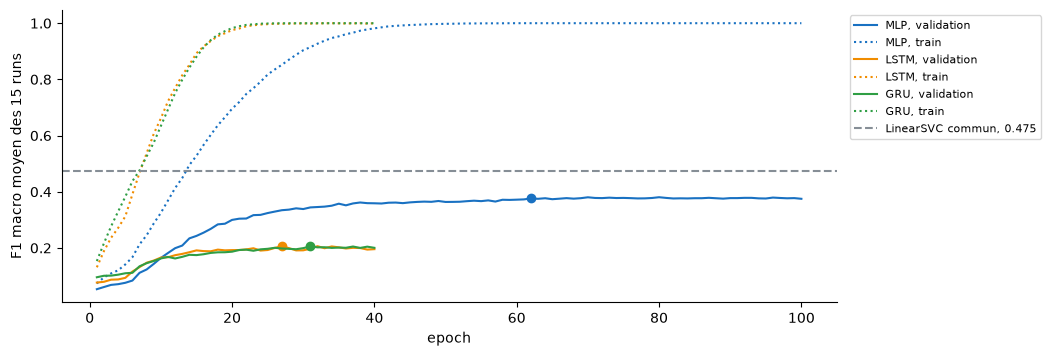

In [51]:
# F1 macro moyen de train et de validation des trois réseaux, avec leur epoch retenue.
f1_svc = score_par_fold('LinearSVC commun').mean()
fig, ax = plt.subplots(figsize=(10, 3.8))
for nom in RESEAUX:
    courbes, epoch = courbes_moyennes(nom), resultats[nom]['epoch']
    validation, train = courbes[('F1 validation', 'mean')], courbes[('F1 train', 'mean')]
    ax.plot(courbes.index, validation, color=COULEURS[nom], label=f'{nom}, validation')
    ax.plot(courbes.index, train, color=COULEURS[nom], linestyle=':', label=f'{nom}, train')
    ax.plot(epoch, validation[epoch], 'o', color=COULEURS[nom])
    print(f'{nom} : epoch retenue {epoch}, F1 validation {validation[epoch]:.3f}, '
          f'F1 train {train[epoch]:.3f}, '
          f'F1 validation à la dernière epoch {validation.iloc[-1]:.3f}')
ax.axhline(f1_svc, linestyle='--', color=COULEURS['LinearSVC commun'],
           label=f'LinearSVC commun, {f1_svc:.3f}')
ax.set(xlabel='epoch', ylabel='F1 macro moyen des 15 runs')
ax.legend(fontsize=8, loc='upper left', bbox_to_anchor=(1.01, 1))
ax.spines[['top', 'right']].set_visible(False)
plt.show()

> *Mes observations :*
>
> Les trois courbes train atteignent 1, celles du LSTM et du GRU vers l'epoch 20 et celle du MLP vers l'epoch 40. Les courbes de validation plafonnent bien plus bas, à 0,376 pour le MLP à l'epoch 62 et à 0,206 pour les deux réseaux récurrents. Aucune ne s'approche de la ligne de `LinearSVC commun`, à 0,475. À la dernière epoch, la validation vaut encore 0,375 pour le MLP, 0,196 pour le LSTM et 0,200 pour le GRU, donc elle ne perd qu'au plus 0,010 après l'epoch retenue.

Le F1 macro moyenne dix locuteurs, donc je le décompose par classe. Je calcule précision, rappel et F1 de chaque locuteur sur les 769 répliques, en moyenne sur les seeds pour les réseaux.

LinearSVC commun                     MLP                \
                       Précision Rappel     F1 Précision Rappel     F1   
CORIOLANUS                 0.483  0.400  0.438     0.346  0.419  0.379   
DUKE VINCENTIO             0.465  0.590  0.520     0.479  0.527  0.501   
GLOUCESTER                 0.495  0.495  0.495     0.388  0.369  0.378   
ISABELLA                   0.560  0.438  0.491     0.389  0.286  0.329   
JULIET                     0.407  0.353  0.378     0.305  0.270  0.286   
KING RICHARD II            0.552  0.516  0.533     0.408  0.382  0.393   
LEONTES                    0.468  0.333  0.389     0.223  0.318  0.262   
MENENIUS                   0.435  0.553  0.487     0.507  0.424  0.461   
PETRUCHIO                  0.630  0.671  0.650     0.462  0.491  0.476   
ROMEO                      0.385  0.400  0.392     0.349  0.302  0.322   

                     LSTM                     GRU               Support  
                Précision Rappel     F1 Précision Rappel     F1          
CORIOLANUS          0.211  0.229  0.219     0.254  0.252  0.253      70  
DUKE VINCENTIO      0.262  0.280  0.269     0.259  0.263  0.259     100  
GLOUCESTER          0.175  0.184  0.179     0.187  0.191  0.189     103  
ISABELLA            0.169  0.188  0.178     0.150  0.146  0.147      64  
JULIET              0.205  0.167  0.183     0.213  0.196  0.203      68  
KING RICHARD II     0.235  0.231  0.233     0.203  0.183  0.192      62  
LEONTES             0.132  0.131  0.132     0.109  0.101  0.104      66  
MENENIUS            0.308  0.290  0.293     0.278  0.302  0.288      85  
PETRUCHIO           0.252  0.259  0.253     0.243  0.250  0.246      76  
ROMEO               0.192  0.169  0.178     0.203  0.200  0.201      75

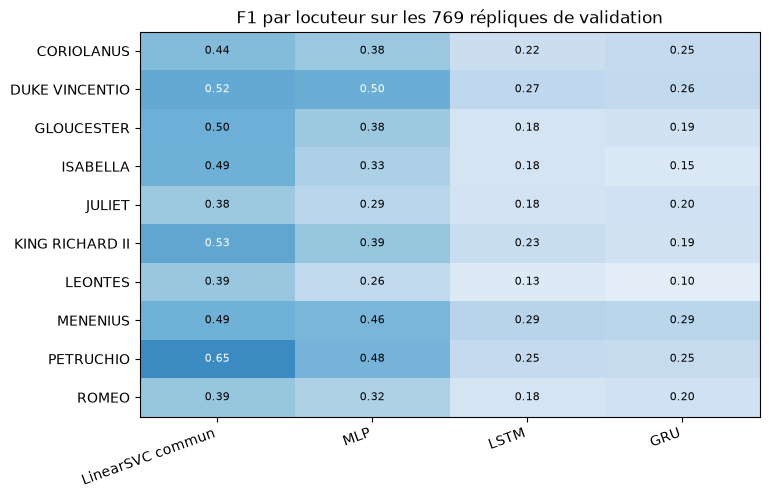

In [52]:
# Précision, rappel et F1 de chaque locuteur, moyennés sur les seeds, puis carte des F1.
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support

MODELES_CLASSES = ['LinearSVC commun', 'MLP', 'LSTM', 'GRU']


def metriques_par_classe(nom: str, source=jeux_predictions, vrais=y_train) -> pd.DataFrame:
    """Précision, rappel et F1 de chaque locuteur, moyennés sur les seeds."""
    tables = []
    for jeu in source(nom):
        precision, rappel, f1, _ = precision_recall_fscore_support(
            vrais, jeu, labels=CLASSES, zero_division=0)
        tables.append(pd.DataFrame({'Précision': precision, 'Rappel': rappel, 'F1': f1},
                                   index=CLASSES))
    return sum(tables) / len(tables)


# Tableau par locuteur avec le support, puis carte des F1
par_classe = pd.concat({nom: metriques_par_classe(nom) for nom in MODELES_CLASSES}, axis=1)
par_classe['Support'] = y_train.value_counts().reindex(CLASSES)
display(par_classe.round(3))

f1_classes = par_classe.xs('F1', axis=1, level=1)
fig, ax = plt.subplots(figsize=(8, 5))
ax.imshow(f1_classes, cmap='Blues', vmin=0, vmax=1, aspect='auto')
for (ligne, colonne), valeur in np.ndenumerate(f1_classes.to_numpy()):
    ax.text(colonne, ligne, f'{valeur:.2f}', ha='center', va='center', fontsize=8,
            color='white' if valeur > 0.5 else 'black')
ax.set_xticks(range(len(MODELES_CLASSES)), MODELES_CLASSES, rotation=20, ha='right')
ax.set_yticks(range(len(CLASSES)), CLASSES)
ax.set_title('F1 par locuteur sur les 769 répliques de validation')
plt.show()

> *Mes observations :*
>
> `LinearSVC commun` obtient le meilleur F1 pour les dix locuteurs, de 0,378 pour JULIET à 0,650 pour PETRUCHIO. Le MLP reconnaît le mieux DUKE VINCENTIO, PETRUCHIO et MENENIUS, avec 0,501, 0,476 et 0,461. Il perd le plus sur PETRUCHIO, de 0,650 à 0,476, puis sur ISABELLA, de 0,491 à 0,329. Le LSTM et le GRU restent entre 0,104 et 0,293 pour tous les locuteurs, avec MENENIUS comme meilleure classe et LEONTES comme pire.
>
> *Ma conclusion :* les réseaux perdent sur tous les locuteurs, et pas sur quelques classes isolées. Le plus grand retard du MLP tombe sur PETRUCHIO, dont le TP1 reliait les bonnes prédictions au nom « kate ». La section 4.3 testera donc le masquage des noms, en lisant le résultat par classe.

Je termine par les matrices de confusion de `LinearSVC commun`, du MLP et du GRU, qui représente aussi le LSTM (section 3.6). Pour les réseaux, je somme les trois seeds, donc j'exprime chaque ligne en % des répliques du locuteur réel. Je relève ensuite les trois plus fortes confusions de chaque modèle et les couples JULIET–ROMEO et GLOUCESTER–DUKE VINCENTIO, suivis depuis le TP1.

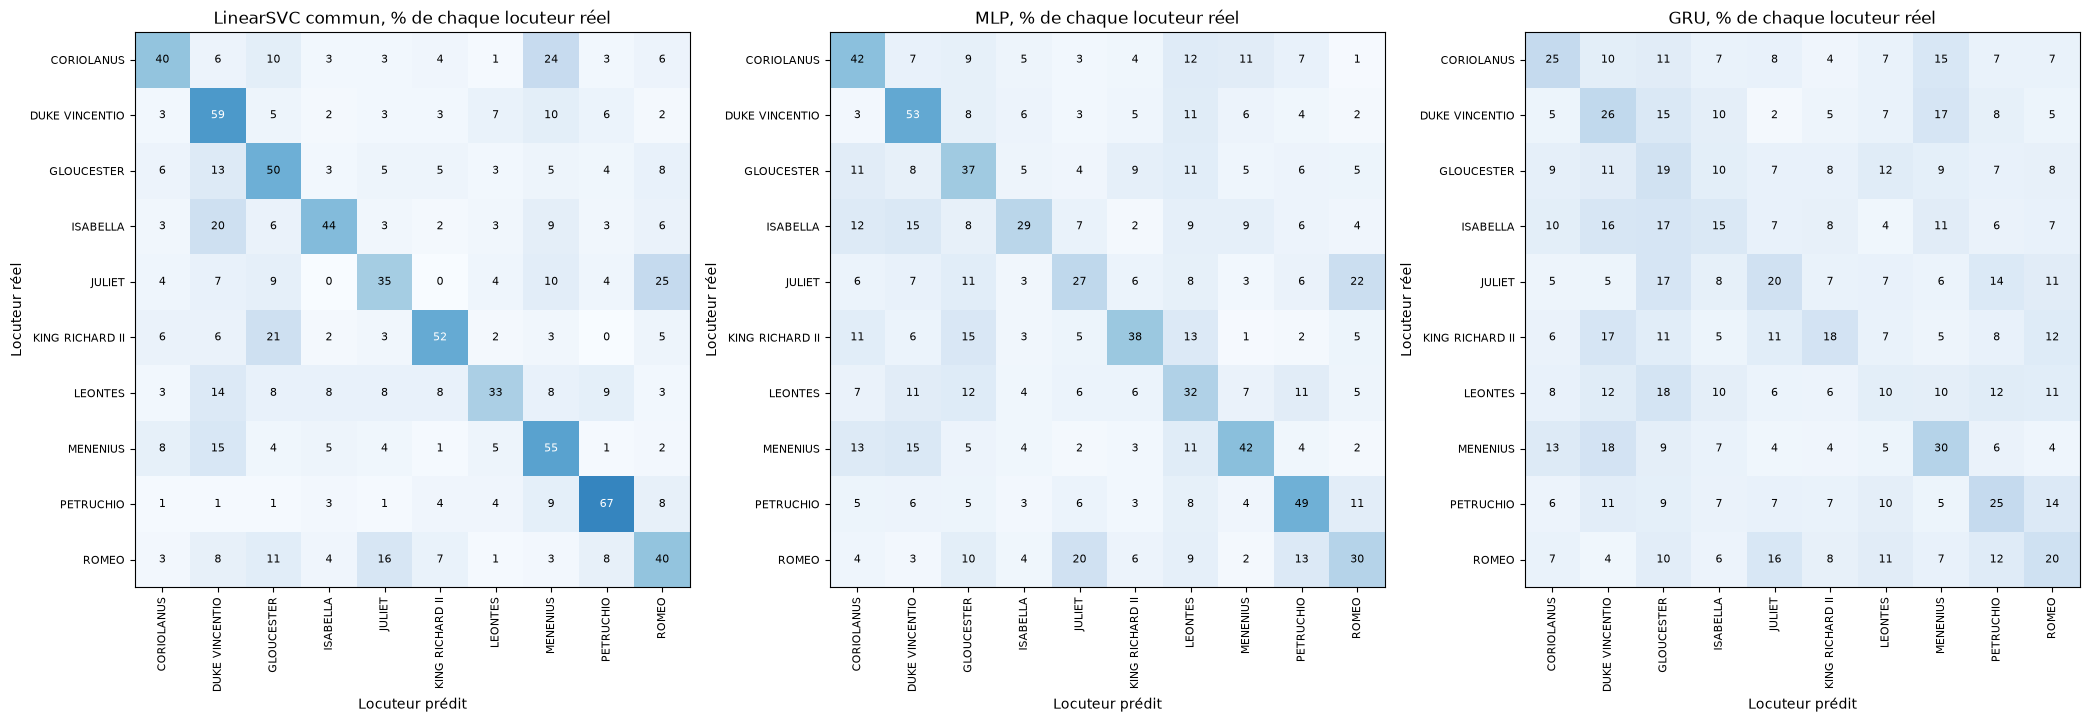

In [53]:
# Matrices de confusion de LinearSVC commun, du MLP et du GRU, en % de chaque locuteur réel.
MODELES_MATRICES = ['LinearSVC commun', 'MLP', 'GRU']


def matrice_confusion(nom: str, source=jeux_predictions, vrais=y_train) -> pd.DataFrame:
    """Effectifs réel × prédit, sommés sur les seeds d'un réseau."""
    effectifs = sum(confusion_matrix(vrais, jeu, labels=CLASSES) for jeu in source(nom))
    return pd.DataFrame(effectifs, index=CLASSES, columns=CLASSES)


def en_pourcentage(matrice: pd.DataFrame) -> pd.DataFrame:
    """Chaque ligne en % des répliques du locuteur réel."""
    return matrice.apply(lambda ligne: pourcentage(ligne, ligne.sum()), axis=1)


def tracer_matrice(axe, nom: str, matrice: pd.DataFrame) -> None:
    """Carte d'une matrice en % par ligne, valeurs arrondies écrites dans les cases."""
    lignes = en_pourcentage(matrice)
    axe.imshow(lignes, cmap='Blues', vmin=0, vmax=100)
    for (ligne, colonne), valeur in np.ndenumerate(lignes.to_numpy()):
        axe.text(colonne, ligne, f'{valeur:.0f}', ha='center', va='center', fontsize=8,
                 color='white' if valeur > 50 else 'black')
    axe.set_xticks(range(len(CLASSES)), CLASSES, rotation=90, fontsize=8)
    axe.set_yticks(range(len(CLASSES)), CLASSES, fontsize=8)
    axe.set(title=f'{nom}, % de chaque locuteur réel', xlabel='Locuteur prédit',
            ylabel='Locuteur réel')


matrices = {nom: matrice_confusion(nom) for nom in MODELES_MATRICES}
fig, axes = plt.subplots(1, 3, figsize=(21, 7))
for axe, (nom, matrice) in zip(axes, matrices.items()):
    tracer_matrice(axe, nom, matrice)
plt.tight_layout()
plt.show()

In [54]:
# Les trois plus fortes confusions de chaque modèle et les deux couples suivis depuis le TP1.
COUPLES_TP1 = [('JULIET', 'ROMEO'), ('ROMEO', 'JULIET'),
               ('GLOUCESTER', 'DUKE VINCENTIO'), ('DUKE VINCENTIO', 'GLOUCESTER')]


def decrire_case(matrice: pd.DataFrame, reel: str, predit: str) -> str:
    """Part d'une case dans les répliques du locuteur réel, avec les effectifs."""
    case, total = matrice.loc[reel, predit], matrice.loc[reel].sum()
    return f'{reel} → {predit} : {pourcentage(case, total):.1f} % ({case} sur {total})'


def decrire_confusions(matrices: dict) -> None:
    """Rappel moyen, trois plus fortes confusions et couples du TP1 de chaque matrice."""
    for nom, matrice in matrices.items():
        parts = en_pourcentage(matrice)
        hors_diagonale = parts.where(~np.eye(len(CLASSES), dtype=bool)).stack().dropna()
        print(f'{nom} : rappel moyen {np.diag(parts).mean():.1f} %')
        for titre, cases in (('plus fortes confusions', hors_diagonale.nlargest(3).index),
                             ('couples suivis depuis le TP1', COUPLES_TP1)):
            print(f'   {titre}')
            for reel, predit in cases:
                print(f'      {decrire_case(matrice, reel, predit)}')


decrire_confusions(matrices)

LinearSVC commun : rappel moyen 47.5 %
   plus fortes confusions
      JULIET → ROMEO : 25.0 % (17 sur 68)
      CORIOLANUS → MENENIUS : 24.3 % (17 sur 70)
      KING RICHARD II → GLOUCESTER : 21.0 % (13 sur 62)
   couples suivis depuis le TP1
      JULIET → ROMEO : 25.0 % (17 sur 68)
      ROMEO → JULIET : 16.0 % (12 sur 75)
      GLOUCESTER → DUKE VINCENTIO : 12.6 % (13 sur 103)
      DUKE VINCENTIO → GLOUCESTER : 5.0 % (5 sur 100)
MLP : rappel moyen 37.9 %
   plus fortes confusions
      JULIET → ROMEO : 22.1 % (45 sur 204)
      ROMEO → JULIET : 19.6 % (44 sur 225)
      KING RICHARD II → GLOUCESTER : 15.1 % (28 sur 186)
   couples suivis depuis le TP1
      JULIET → ROMEO : 22.1 % (45 sur 204)
      ROMEO → JULIET : 19.6 % (44 sur 225)
      GLOUCESTER → DUKE VINCENTIO : 8.1 % (25 sur 309)
      DUKE VINCENTIO → GLOUCESTER : 8.3 % (25 sur 300)
GRU : rappel moyen 20.8 %
   plus fortes confusions
      MENENIUS → DUKE VINCENTIO : 18.0 % (46 sur 255)
      LEONTES → GLOUCESTER : 17.7

> *Mes observations :*
>
> Pour `LinearSVC commun`, la diagonale domine chaque ligne, avec un rappel moyen de 47,5 %. Ses trois plus fortes confusions sont JULIET → ROMEO à 25,0 %, CORIOLANUS → MENENIUS à 24,3 % et KING RICHARD II → GLOUCESTER à 21,0 %. Le couple du TP1 GLOUCESTER–DUKE VINCENTIO reste plus faible, à 12,6 % et 5,0 % selon le sens.
>
> Pour le MLP, la diagonale domine encore chaque ligne, avec un rappel moyen de 37,9 %. JULIET et ROMEO se confondent dans les deux sens, à 22,1 % et 19,6 %, puis KING RICHARD II part vers GLOUCESTER à 15,1 %. La colonne LEONTES reçoit 8 à 13 % des neuf autres lignes, ce qui explique sa précision de 0,223 pour un rappel de 0,318.
>
> Pour le GRU, le rappel moyen tombe à 20,8 %, et la diagonale ne domine plus. ISABELLA et LEONTES sont plus souvent prédits GLOUCESTER que bien classés, à 17 % et 18 % contre 15 % et 10 %. Ses plus fortes confusions vont vers DUKE VINCENTIO, GLOUCESTER et MENENIUS, les trois locuteurs les plus fréquents des 769 répliques.
>
> *Ma conclusion :* LinearSVC et le MLP confondent d'abord JULIET et ROMEO, alors que les erreurs du GRU suivent surtout la fréquence des classes. Le couple GLOUCESTER–DUKE VINCENTIO du TP1 pèse moins ici, de 5,0 % à 14,7 % selon le sens et le modèle. La section 4.2 dira si les confusions de LinearSVC et du MLP restent dans une même pièce.

> *Ma conclusion :* en validation croisée, `LinearSVC commun` reste le meilleur modèle, avec 0,475 de F1 macro, devant le MLP à 0,376 et les deux réseaux récurrents à 0,206. Ce classement tient dans les cinq folds et pour les dix locuteurs, et les tests de McNemar le jugent significatif. Les réseaux mémorisent le train comme LinearSVC, mais ils généralisent moins bien, pour un temps d'entraînement plus de cent fois plus long. La section 4.2 doit maintenant expliquer leurs erreurs, et la section 4.3 tester l'ordre des mots, les noms et la quantité de données.

### 4.2 Revenir aux répliques

Je lis les erreurs communes et les désaccords entre ML et DL, en suivant JULIET–ROMEO et GLOUCESTER–DUKE VINCENTIO sans supposer que les erreurs du TP1 se reproduisent.

Le TP1 (section 8.3) suggérait que le modèle reconnaît la pièce plutôt que le style, donc je le teste. Je regroupe les dix locuteurs par pièce à partir du corpus, car les locuteurs qui se répondent dans une fenêtre de répliques consécutives appartiennent à la même pièce. Puis je compare la part d'erreurs intra-pièce à la part inter-pièce et au hasard, car JULIET–ROMEO est intra-pièce alors que GLOUCESTER–DUKE VINCENTIO est inter-pièce.

Quelles erreurs le DL corrige-t-il et lesquelles introduit-il ? Les noms, le vocabulaire partagé, la longueur ou les tokens inconnus donnent-ils une explication vérifiable ?


Je reconstruis d'abord les pièces à partir des seules étiquettes du corpus, sans lire les répliques. Un même nom peut revenir dans une autre pièce, donc je coupe les apparitions de chaque locuteur en morceaux séparés par plus de 400 répliques. Puis je relie deux morceaux qui se répondent au moins 20 fois dans une fenêtre de 5 répliques.

In [55]:
# Pièces reconstruites à partir des seules étiquettes du corpus : morceaux de locuteurs, puis liens.
ECART_PIECE = 400  # Positions sans le locuteur au-delà desquelles il change de pièce
FENETRE_PIECE = 5  # Répliques suivantes où je cherche une réponse
SEUIL_PIECE = 20  # Réponses nécessaires pour relier deux morceaux


def morceaux_locuteurs() -> dict:
    """Positions de chaque locuteur retenu dans le corpus, coupées aux grands écarts."""
    etiquettes, morceaux = df['locuteur'].to_numpy(), {}
    for locuteur in CLASSES:
        positions = np.flatnonzero(etiquettes == locuteur)
        coupures = np.flatnonzero(np.diff(positions) > ECART_PIECE) + 1
        for numero, bloc in enumerate(np.split(positions, coupures), start=1):
            morceaux[(locuteur, numero)] = bloc
    return morceaux


def compter_reponses(morceaux: dict) -> Counter:
    """Fois où deux morceaux de locuteurs différents se suivent à moins de la fenêtre."""
    morceau_de = {position: cle for cle, bloc in morceaux.items() for position in bloc}
    liens = Counter()
    for position, cle in morceau_de.items():
        for suivante in range(position + 1, position + FENETRE_PIECE + 1):
            autre = morceau_de.get(suivante)
            if autre is not None and autre[0] != cle[0]:
                liens[tuple(sorted((cle, autre)))] += 1
    return liens


def numeroter_pieces(morceaux: dict, liens: Counter) -> dict:
    """Pièce de chaque morceau : liens d'au moins SEUIL_PIECE réponses, numéros dans l'ordre."""
    parent = {cle: cle for cle in morceaux}

    def racine(cle):
        while parent[cle] != cle:
            cle = parent[cle]
        return cle

    for (a, b), nombre in liens.items():
        if nombre >= SEUIL_PIECE:
            parent[racine(a)] = racine(b)
    debuts = {}
    for cle, bloc in morceaux.items():
        debuts[racine(cle)] = min(debuts.get(racine(cle), bloc[0]), bloc[0])
    numeros = {r: k for k, r in enumerate(sorted(debuts, key=debuts.get), start=1)}
    return {cle: numeros[racine(cle)] for cle in morceaux}


# Morceaux, liens et pièces
morceaux = morceaux_locuteurs()
liens = compter_reponses(morceaux)
piece_morceau = numeroter_pieces(morceaux, liens)

# Pièce de chaque réplique de développement, par sa position dans le corpus
assert (df.loc[X_train.index, 'locuteur'] == y_train).all()  # Indices du TP1 conservés
piece_position = {p: piece_morceau[cle] for cle, bloc in morceaux.items() for p in bloc}
piece_de = pd.Series({indice: piece_position[indice] for indice in X_train.index})
pieces_du_locuteur = {locuteur: {piece for (nom, _), piece in piece_morceau.items()
                                 if nom == locuteur} for locuteur in CLASSES}

# Affichages : morceaux, liens, puis locuteurs de chaque pièce
table_morceaux = pd.DataFrame([
    {'Morceau': f'{nom} {numero}', 'Répliques': len(bloc), 'Première position': bloc[0],
     'Dernière position': bloc[-1], 'Pièce': piece_morceau[(nom, numero)]}
    for (nom, numero), bloc in morceaux.items()]).sort_values('Première position')
display(table_morceaux.set_index('Morceau'))
for (a, b), nombre in liens.most_common():
    statut = 'relié' if nombre >= SEUIL_PIECE else 'coupé'
    print(f'{a[0]} {a[1]} – {b[0]} {b[1]} : {nombre} réponses, {statut}')
for piece in sorted(set(piece_morceau.values())):
    membres = [f'{nom} {numero}' for (nom, numero), p in piece_morceau.items() if p == piece]
    print(f'Pièce {piece} : {", ".join(membres)}, {(piece_de == piece).sum()} répliques de '
          f'développement')

,Répliques,Première position,Dernière position,Pièce
Morceau,,,,
MENENIUS 1,161,22,1041,1
CORIOLANUS 1,148,219,1086,1
GLOUCESTER 1,160,1098,1799,2
KING RICHARD II 1,98,2168,2706,3
ROMEO 1,160,2781,3496,4
JULIET 1,117,2844,3513,4
GLOUCESTER 2,51,3900,4328,5
LEONTES 1,124,4346,5066,6
DUKE VINCENTIO 1,189,5067,5938,7


DUKE VINCENTIO 1 – ISABELLA 1 : 247 réponses, relié
JULIET 1 – ROMEO 1 : 222 réponses, relié
CORIOLANUS 1 – MENENIUS 1 : 173 réponses, relié
DUKE VINCENTIO 1 – JULIET 2 : 36 réponses, relié
DUKE VINCENTIO 1 – LEONTES 1 : 3 réponses, coupé
ISABELLA 1 – JULIET 2 : 1 réponses, coupé
Pièce 1 : CORIOLANUS 1, MENENIUS 1, 155 répliques de développement
Pièce 2 : GLOUCESTER 1, 78 répliques de développement
Pièce 3 : KING RICHARD II 1, 62 répliques de développement
Pièce 4 : JULIET 1, ROMEO 1, 142 répliques de développement
Pièce 5 : GLOUCESTER 2, 25 répliques de développement
Pièce 6 : LEONTES 1, 66 répliques de développement
Pièce 7 : DUKE VINCENTIO 1, ISABELLA 1, JULIET 2, 165 répliques de développement
Pièce 8 : PETRUCHIO 1, 76 répliques de développement


> *Mes observations :*
>
> Les douze morceaux forment huit pièces. GLOUCESTER revient après plus de 2 000 positions sans lui, donc il a deux morceaux, de 160 puis 51 répliques, dans les pièces 2 et 5. JULIET a aussi un second morceau de 7 répliques, relié à DUKE VINCENTIO par 36 réponses, donc il rejoint la pièce 7. Le lien de 3 réponses entre DUKE VINCENTIO et LEONTES tombe à la frontière de leurs morceaux, des positions 5066 à 5067, donc le seuil de 20 le coupe à raison. Seules trois pièces réunissent plusieurs des dix locuteurs.
>
> *Ma conclusion :* une étiquette ne désigne pas toujours un seul personnage. Les 25 répliques de développement de la pièce 5 portent l'étiquette GLOUCESTER sans venir de la même pièce que les 78 autres.

Si un modèle reconnaît la pièce plutôt que le style, ses erreurs restent dans la pièce de la réplique plus souvent que le hasard. Je mesure cette part pour LinearSVC, le MLP et le GRU. Le hasard suppose que l'erreur tombe sur l'un des neuf autres locuteurs avec la même chance.

,Erreurs,Dans la pièce (%),Hasard (%),Rapport au hasard
Modèle,,,,
LinearSVC commun,397.00,18.64,9.07,2.06
MLP,471.67,14.99,8.91,1.68
GRU,605.00,11.12,8.88,1.25


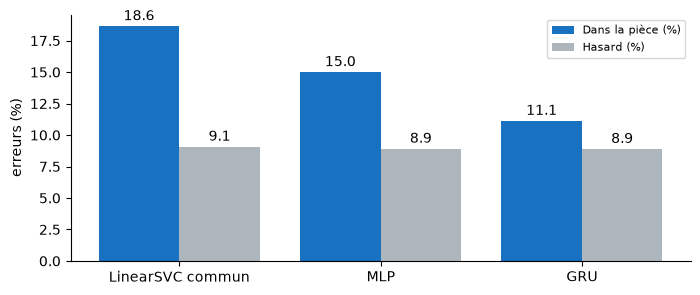

In [56]:
# Part des erreurs qui restent dans la pièce de la réplique, face au hasard, pour trois modèles.
MODELES_PIECE = ['LinearSVC commun', 'MLP', 'GRU']


def dans_la_piece(indice, predit: str) -> bool:
    """Vrai si le locuteur prédit a un morceau dans la pièce de la réplique."""
    return piece_position[indice] in pieces_du_locuteur[predit]


def part_intra(nom: str, source=jeux_predictions, vrais=y_train) -> dict:
    """Erreurs, part dans la même pièce et part attendue au hasard, moyennées sur les seeds."""
    lignes = []
    for jeu in source(nom):
        erreurs = jeu.index[jeu != vrais]
        dedans = sum(dans_la_piece(i, jeu.loc[i]) for i in erreurs)
        # Hasard : l'erreur tombe sur l'un des neuf autres locuteurs, chacun avec la même chance
        hasard = sum(dans_la_piece(i, autre) for i in erreurs for autre in CLASSES
                     if autre != vrais.loc[i]) / (len(CLASSES) - 1)
        lignes.append({'Erreurs': len(erreurs),
                       'Dans la pièce (%)': pourcentage(dedans, len(erreurs)),
                       'Hasard (%)': pourcentage(hasard, len(erreurs))})
    moyenne = pd.DataFrame(lignes).mean()
    return {'Modèle': nom, **moyenne.to_dict(),
            'Rapport au hasard': moyenne['Dans la pièce (%)'] / moyenne['Hasard (%)']}


intra = pd.DataFrame([part_intra(nom) for nom in MODELES_PIECE]).set_index('Modèle')
display(intra.round(2))

# Erreurs dans la pièce face au hasard, deux barres par modèle
positions = np.arange(len(intra))
fig, ax = plt.subplots(figsize=(8, 3.2))
for decalage, colonne, couleur in ((-0.2, 'Dans la pièce (%)', '#1971c2'),
                                   (0.2, 'Hasard (%)', '#adb5bd')):
    barres = ax.bar(positions + decalage, intra[colonne], 0.4, color=couleur, label=colonne)
    ax.bar_label(barres, labels=[f'{valeur:.1f}' for valeur in intra[colonne]], padding=2)
ax.set_xticks(positions, intra.index)
ax.set_ylabel('erreurs (%)')
ax.legend(fontsize=8)
ax.spines[['top', 'right']].set_visible(False)
plt.show()

> *Mes observations :*
>
> Les erreurs de LinearSVC restent dans la pièce de la réplique dans 18,6 % des cas, contre 9,1 % au hasard, soit 2,06 fois plus. Le rapport tombe à 1,68 pour le MLP et à 1,25 pour le GRU. Plus de 81 % des erreurs de chaque modèle sortent donc de la pièce.
>
> *Ma conclusion :* l'idée du TP1 tient en partie. LinearSVC reconnaît un peu la pièce, car ses erreurs y restent deux fois plus souvent qu'au hasard. Mais la pièce n'explique qu'une erreur sur cinq, et les réseaux s'en servent moins que LinearSVC.

Je reprends ensuite les deux couples suivis depuis le TP1, avec la pièce de chaque confusion. GLOUCESTER a deux morceaux, donc je mesure aussi son rappel dans chacun.

In [57]:
# Couples suivis depuis le TP1 : confusions par modèle, seeds sommées, puis GLOUCESTER par morceau.


def confusions_couple(nom: str, reel: str, predit: str) -> dict:
    """Confusions d'un couple sur toutes les seeds, et combien restent dans la même pièce."""
    cas = [i for jeu in jeux_predictions(nom)
           for i in jeu.index[(y_train == reel) & (jeu == predit)]]
    return {'Modèle': nom, 'Couple': f'{reel} → {predit}', 'Confusions': len(cas),
            'Dans la même pièce': sum(dans_la_piece(i, predit) for i in cas)}


def rappel_par_piece(nom: str, locuteur: str) -> dict:
    """Rappel d'un locuteur dans chacune de ses pièces, toutes seeds confondues."""
    rappels = {'Modèle': nom}
    for piece in sorted(pieces_du_locuteur[locuteur]):
        indices = y_train.index[(y_train == locuteur) & (piece_de == piece)]
        justes = sum((jeu.loc[indices] == locuteur).sum() for jeu in jeux_predictions(nom))
        rappels[f'Pièce {piece}, {len(indices)} répliques'] = pourcentage(
            justes, len(indices) * len(jeux_predictions(nom)))
    return rappels


couples = pd.DataFrame([confusions_couple(nom, reel, predit) for nom in MODELES_PIECE
                        for reel, predit in COUPLES_TP1])
display(couples.pivot(index='Couple', columns='Modèle',
                      values=['Confusions', 'Dans la même pièce']))
display(pd.DataFrame([rappel_par_piece(nom, 'GLOUCESTER') for nom in MODELES_PIECE])
        .set_index('Modèle').round(1).rename_axis('Rappel de GLOUCESTER (%)'))

Confusions                       \
Modèle                             GRU LinearSVC commun MLP   
Couple                                                        
DUKE VINCENTIO → GLOUCESTER         44                5  25   
GLOUCESTER → DUKE VINCENTIO         34               13  25   
JULIET → ROMEO                      23               17  45   
ROMEO → JULIET                      35               12  44   

                            Dans la même pièce                       
Modèle                                     GRU LinearSVC commun MLP  
Couple                                                               
DUKE VINCENTIO → GLOUCESTER                  0                0   0  
GLOUCESTER → DUKE VINCENTIO                  0                0   0  
JULIET → ROMEO                              23               17  45  
ROMEO → JULIET                              35               12  44

,"Pièce 2, 78 répliques","Pièce 5, 25 répliques"
Rappel de GLOUCESTER (%),,
LinearSVC commun,47.4,56.0
MLP,39.3,29.3
GRU,19.2,18.7


> *Mes observations :*
>
> Toutes les confusions entre JULIET et ROMEO restent dans la même pièce, pour les trois modèles. Celles entre GLOUCESTER et DUKE VINCENTIO en sortent toujours. LinearSVC en fait 13 et 5. Sur ses trois seeds, le MLP en fait 25 dans chaque sens, soit environ 8 par seed. Le GRU en fait 34 et 44, soit environ 11 et 15 par seed. Le rappel de GLOUCESTER vaut 47,4 % dans la pièce 2 et 56,0 % dans la pièce 5 pour LinearSVC, mais 39,3 % et 29,3 % pour le MLP.
>
> *Ma conclusion :* JULIET–ROMEO est bien une confusion dans la pièce et GLOUCESTER–DUKE VINCENTIO une confusion hors de la pièce, comme je l'annonçais. LinearSVC reconnaît le second GLOUCESTER aussi bien que le premier, donc il s'appuie sur des indices communs aux deux pièces, et pas seulement au personnage. Le MLP perd surtout sur le petit morceau de 25 répliques.

Pour expliquer les erreurs, je calcule quatre facteurs par réplique, avec les listes du train de son fold seulement. Ce sont la longueur, la part de tokens inconnus, la présence d'un nom et la part de tokens utilisés par les dix locuteurs. Un nom est un mot écrit avec une majuscule dans au moins 95 % de ses 3 occurrences ou plus, hors « I » et ses contractions.

In [58]:
# Facteurs de chaque réplique de validation, calculés avec les listes du train de son fold.
MOT = r"[A-Za-z]+(?:'[A-Za-z]+)*"  # Mot du texte brut, apostrophes internes comprises
SEUIL_MAJUSCULE, MINIMUM_NOM = 0.95, 3


def detecter_noms(textes: pd.Series) -> set:
    """Mots presque toujours en majuscule et assez fréquents, hors « I » et ses contractions."""
    total, majuscules = Counter(), Counter()
    for texte in textes:
        for mot in re.findall(MOT, texte):
            cle = mot.lower()
            if len(cle) < 2 or cle.startswith("i'"):
                continue
            total[cle] += 1
            majuscules[cle] += mot[0].isupper()
    return {mot for mot, nombre in total.items()
            if nombre >= MINIMUM_NOM and majuscules[mot] / nombre >= SEUIL_MAJUSCULE}


def facteurs_fold(fold: dict, textes: pd.Series = X_train) -> pd.DataFrame:
    """Longueur, tokens inconnus, noms et tokens partagés, avec les listes du train du fold."""
    textes_train = X_train.loc[fold['train']]
    vocabulaire, noms = construire_vocabulaire(textes_train), detecter_noms(textes_train)
    locuteurs_du_token = {}
    for texte, cible in zip(textes_train, y_train.loc[fold['train']]):
        for token in set(tokeniser(texte)):
            locuteurs_du_token.setdefault(token, set()).add(cible)
    lignes = []
    for indice in fold['validation']:
        tokens = tokeniser(textes.loc[indice])
        partages = sum(len(locuteurs_du_token.get(t, ())) == len(CLASSES) for t in tokens)
        lignes.append({'Indice': indice, 'Longueur': len(tokens),
                       'Inconnus (%)': pourcentage(sum(t not in vocabulaire for t in tokens),
                                                   len(tokens)),
                       'Partagés (%)': pourcentage(partages, len(tokens)),
                       'Noms': sorted({t for t in tokens if t in noms})})
    return pd.DataFrame(lignes).set_index('Indice')


# Facteurs des 769 répliques, puis ce que la règle des noms retient
facteurs = pd.concat([facteurs_fold(fold) for fold in folds]).loc[X_train.index]
facteurs['Nom'] = facteurs['Noms'].str.len() > 0
noms_fold_1 = detecter_noms(X_train.loc[folds[0]['train']])
frequences = Counter(token for texte in X_train.loc[folds[0]['train']]
                     for token in tokeniser(texte) if token in noms_fold_1)
print(f'Noms par fold : {[len(detecter_noms(X_train.loc[f["train"]])) for f in folds]}')
print('Fold 1, les 20 plus fréquents : '
      + ', '.join(f'{nom} ({nombre})' for nom, nombre in frequences.most_common(20)))
print(f'Répliques de validation avec au moins un nom : '
      f'{pourcentage(facteurs["Nom"].sum(), len(facteurs)):.1f} %')

Noms par fold : [53, 51, 55, 54, 56]
Fold 1, les 20 plus fréquents : kate (39), romeo (27), angelo (24), rome (16), clarence (13), juliet (13), marcius (11), tybalt (11), bolingbroke (10), edward (10), aufidius (9), claudio (8), edward's (6), camillo (6), cominius (6), paulina (6), richard (6), henry (6), tybalt's (6), polixenes (5)
Répliques de validation avec au moins un nom : 28.5 %


> *Mes observations :*
>
> La règle retient de 51 à 56 mots selon le fold. Sur le fold 1, les plus fréquents sont des personnages, comme « kate » (39), « romeo » (27) et « angelo » (24). La liste contient aussi des lieux, comme « rome » (16). Les formes possessives comme « edward's » et « tybalt's » comptent comme des noms à part. Au moins un nom apparaît dans 28,5 % des répliques de validation.

Je compare maintenant ces facteurs entre quatre groupes de répliques, selon que `LinearSVC commun` et le MLP ont raison. Je calcule les groupes pour chaque seed du MLP, puis je fais la moyenne, comme pour les comptes de la section 4.1.

,Répliques,Longueur,Avec un nom (%),Inconnus (%),Partagés (%)
Groupe,,,,,
Deux justes,221.7,60.3,45.8,12.7,55.2
LinearSVC seul juste,150.3,54.9,35.8,12.8,54.7
MLP seul juste,75.7,45.9,22.4,13.3,54.8
Deux faux,321.3,39.0,14.7,13.1,56.0


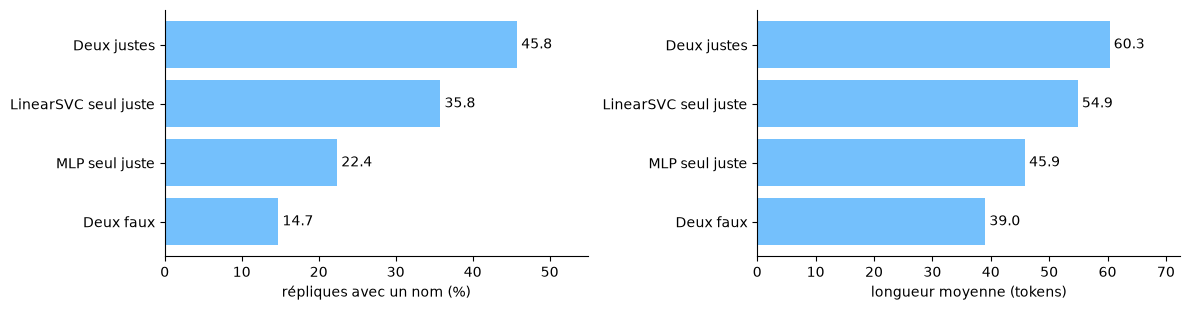

In [59]:
# Quatre groupes de répliques selon LinearSVC commun et le MLP, puis leurs facteurs moyens.
ORDRE_GROUPES = ['Deux justes', 'LinearSVC seul juste', 'MLP seul juste', 'Deux faux']


def groupes_svc_mlp(jeu_mlp: pd.Series, jeu_svc=None, vrais=y_train) -> pd.Series:
    """Groupe de chaque réplique selon que LinearSVC commun et une seed du MLP ont raison."""
    if jeu_svc is None:
        jeu_svc = jeux_predictions('LinearSVC commun')[0]
    svc, mlp = jeu_svc == vrais, jeu_mlp == vrais
    choix = np.select([svc & mlp, svc & ~mlp, ~svc & mlp], ORDRE_GROUPES[:3], ORDRE_GROUPES[3])
    return pd.Series(choix, index=vrais.index)


def facteurs_par_groupe(jeu_mlp: pd.Series, jeu_svc=None, vrais=y_train,
                        table=None) -> pd.DataFrame:
    """Effectif et facteurs moyens de chaque groupe pour une seed du MLP."""
    table = facteurs if table is None else table
    return table.assign(Groupe=groupes_svc_mlp(jeu_mlp, jeu_svc, vrais)).groupby('Groupe').agg(
        Répliques=('Longueur', 'size'), Longueur=('Longueur', 'mean'),
        **{'Avec un nom (%)': ('Nom', lambda s: pourcentage(s.sum(), len(s))),
           'Inconnus (%)': ('Inconnus (%)', 'mean'), 'Partagés (%)': ('Partagés (%)', 'mean')})


tables = [facteurs_par_groupe(jeu) for jeu in jeux_predictions('MLP')]
facteurs_groupes = (sum(tables) / len(tables)).loc[ORDRE_GROUPES]
display(facteurs_groupes.round(1))

# Part de répliques avec un nom et longueur moyenne, par groupe
fig, axes = plt.subplots(1, 2, figsize=(12, 3.2))
for axe, colonne in zip(axes, ('Avec un nom (%)', 'Longueur')):
    barres = axe.barh(ORDRE_GROUPES[::-1], facteurs_groupes[colonne][::-1], color='#74c0fc')
    axe.bar_label(barres, labels=[f'{v:.1f}' for v in facteurs_groupes[colonne][::-1]], padding=3)
    axe.set_xlim(0, facteurs_groupes[colonne].max() * 1.2)
    axe.set_xlabel({'Longueur': 'longueur moyenne (tokens)'}.get(
        colonne, 'répliques avec un nom (%)'))
    axe.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

> *Mes observations :*
>
> Les quatre groupes ont les effectifs de la section 4.1, de 221,7 répliques justes pour les deux modèles à 321,3 fausses pour les deux. Un nom apparaît dans 45,8 % des répliques justes pour les deux et dans 35,8 % de celles que seul LinearSVC trouve. Il apparaît dans 22,4 % de celles que seul le MLP trouve et dans 14,7 % des erreurs communes. La longueur suit le même ordre, de 60,3 à 39,0 tokens. Les tokens inconnus, de 12,7 % à 13,3 %, et les tokens partagés par les dix locuteurs, de 54,7 % à 56,0 %, changent à peine d'un groupe à l'autre.
>
> *Ma conclusion :* le MLP perd surtout des répliques nommées, car 35,8 % des 150,3 répliques que seul LinearSVC trouve contiennent un nom. Les répliques qu'il corrige sont plus courtes et moins souvent nommées que celles qu'il perd. Les erreurs communes sont courtes et rarement nommées, donc elles manquent d'indices pour les deux modèles. Les noms et la longueur expliquent donc les erreurs de façon vérifiable, alors que les tokens inconnus et le vocabulaire partagé ne les expliquent pas. Cela soutient mon hypothèse de la section 3.4, où la moyenne noie les mots rares.

Je lis enfin cinq répliques entières, une par catégorie. Pour ne pas choisir celles qui m'arrangent, je prends dans chaque catégorie la première réplique dans l'ordre du corpus. Le MLP a raison quand au moins deux de ses trois seeds ont raison.

In [60]:
# Cinq cas concrets : dans chaque catégorie, la première réplique dans l'ordre du corpus.
import textwrap

svc = jeux_predictions('LinearSVC commun')[0]
mlp_seeds = pd.concat(jeux_predictions('MLP'), axis=1)
gru_seeds = pd.concat(jeux_predictions('GRU'), axis=1)
svc_juste = svc == y_train
mlp_juste = mlp_seeds.eq(y_train, axis=0).mean(axis=1) > 0.5  # Majorité des seeds
svc_dans_piece = pd.Series([dans_la_piece(i, svc.loc[i]) for i in X_train.index], X_train.index)
CATEGORIES = {
    'Erreur commune dans la pièce': ~svc_juste & ~mlp_juste & svc_dans_piece,
    'Erreur commune hors de la pièce': ~svc_juste & ~mlp_juste & ~svc_dans_piece,
    'Corrigée par le MLP': ~svc_juste & mlp_juste,
    'Introduite par le MLP': svc_juste & ~mlp_juste,
    'JULIET prédite ROMEO par LinearSVC': (y_train == 'JULIET') & (svc == 'ROMEO'),
}


def decrire_cas(titre: str, indice) -> str:
    """Réplique entière, locuteur réel, prédictions des trois modèles et facteurs."""
    ligne = facteurs.loc[indice]
    return (f'{titre}, indice {indice}, pièce {piece_de.loc[indice]}\n'
            f'   réel : {y_train.loc[indice]} | LinearSVC : {svc.loc[indice]} | '
            f'MLP : {", ".join(mlp_seeds.loc[indice])} | GRU : {", ".join(gru_seeds.loc[indice])}\n'
            f'   {ligne["Longueur"]} tokens, {ligne["Inconnus (%)"]:.1f} % inconnus, '
            f'{ligne["Partagés (%)"]:.1f} % partagés, '
            f'noms : {", ".join(ligne["Noms"]) or "aucun"}\n'
            + textwrap.fill(X_train.loc[indice], width=96, initial_indent='   ',
                            subsequent_indent='   ') + '\n')


for titre, masque in CATEGORIES.items():
    print(f'{titre} : {masque.sum()} répliques')
print()
for titre, masque in CATEGORIES.items():
    if masque.any():
        print(decrire_cas(titre, masque.index[masque].min()))

Erreur commune dans la pièce : 58 répliques
Erreur commune hors de la pièce : 282 répliques
Corrigée par le MLP : 57 répliques
Introduite par le MLP : 139 répliques
JULIET prédite ROMEO par LinearSVC : 17 répliques

Erreur commune dans la pièce, indice 259, pièce 1
   réel : MENENIUS | LinearSVC : CORIOLANUS | MLP : LEONTES, MENENIUS, LEONTES | GRU : LEONTES, DUKE VINCENTIO, DUKE VINCENTIO
   19 tokens, 31.6 % inconnus, 42.1 % partagés, noms : rome
   Why, then you should discover a brace of unmeriting, proud, violent, testy magistrates, alias
   fools, as any in Rome.

Erreur commune hors de la pièce, indice 24, pièce 1
   réel : MENENIUS | LinearSVC : LEONTES | MLP : LEONTES, PETRUCHIO, LEONTES | GRU : MENENIUS, PETRUCHIO, MENENIUS
   12 tokens, 25.0 % inconnus, 50.0 % partagés, noms : aucun
   Why, masters, my good friends, mine honest neighbours, Will you undo yourselves?

Corrigée par le MLP, indice 26, pièce 1
   réel : MENENIUS | LinearSVC : CORIOLANUS | MLP : MENENIUS, MENENIUS

> *Mes observations :*
>
> Les quatre premiers cas viennent tous de MENENIUS, car la pièce 1 ouvre le corpus. Cette règle évite de choisir les cas qui m'arrangent, mais elle limite leur portée.
>
> Erreur commune dans la pièce. La seule piste est « rome », et LinearSVC choisit CORIOLANUS, l'autre locuteur de la pièce 1. La réplique compte 19 tokens dont 31,6 % sont inconnus du train, donc il reste peu d'indices, et les seeds du MLP se partagent entre LEONTES et MENENIUS.
>
> Erreur commune hors de la pièce. La réplique compte 12 tokens, sans nom, et la moitié de ses tokens sont utilisés par les dix locuteurs. LinearSVC choisit LEONTES, le MLP hésite entre LEONTES et PETRUCHIO, alors que deux seeds du GRU trouvent MENENIUS.
>
> Corrigée par le MLP. LinearSVC prédit CORIOLANUS, l'autre locuteur de la pièce, alors que deux seeds du MLP trouvent MENENIUS. La réplique est longue, 112 tokens, mais sans nom, donc LinearSVC n'y avait pas d'indice fort.
>
> Introduite par le MLP. LinearSVC trouve MENENIUS, mais les trois seeds du MLP partent vers ISABELLA ou PETRUCHIO, hors de la pièce. La réplique n'a pas de nom et 56,1 % de ses tokens sont partagés. Mon hypothèse est que la moyenne de ces mots courants efface les quelques indices que LinearSVC pondère.
>
> JULIET prédite ROMEO. La réplique parle de regard, avec « look » et « eye », sans nom. LinearSVC choisit ROMEO, le locuteur de la même pièce, alors que le MLP et le GRU se dispersent surtout hors de la pièce.

> *Ma conclusion :* la pièce explique une petite part des erreurs, 18,6 % pour LinearSVC contre 9,1 % au hasard, et encore moins pour les réseaux. Les noms et la longueur expliquent bien plus. Les répliques justes pour les deux modèles contiennent un nom trois fois plus souvent que les erreurs communes, 45,8 % contre 14,7 %. Le MLP perd surtout des répliques nommées, ce qui rejoint son retard sur PETRUCHIO dans la section 4.1. La section 4.3 testera donc d'abord le masquage des noms, avec la règle `detecter_noms` sur le train de chaque fold.

### 4.3 Expériences ciblées, si les résultats le justifient

Un seul facteur change à la fois, une clé de `REGLAGES` ou une fonction de prétraitement, puis je réentraîne dans les folds avant le test. Par priorité :

1. **Ordre des mots.** Mélanger les mots après tokenisation avec un générateur fixé par l'indice de la réplique, pour que ML et DL voient la même perturbation. Si H2 tient, LSTM et GRU baissent mais MLP et unigrammes TF–IDF ne bougent pas.
2. **Noms propres.** Masquer une liste de noms choisie sur le train du fold seulement, car `kate` et `paulina` motivent la question depuis le TP1. Je lis le résultat par classe, car les classes dont le F1 chute le plus sont reconnues par leurs noms.
3. **Régularisation.** Dropout et weight decay activés, contre le réglage de départ.
4. **Bidirectionnel.** LSTM ou GRU bidirectionnel, à largeur égale.
5. **Quantité de données.** 25, 50, 75 et 100 % du train de chaque fold pour LinearSVC et le meilleur réseau. C'est la seule expérience qui dit si le deep learning manque de données ici.

Une comparaison MLP/LSTM/GRU ne suffit pas à attribuer un gain à l'ordre, et masquer quelques noms ne démontre pas que le signal restant est du style.


> *Mes choix :* je mène quatre des cinq expériences, dans cet ordre.
>
> - Les noms d'abord, car un nom apparaît dans 45,8 % des répliques justes pour LinearSVC et le MLP, contre 14,7 % des erreurs communes (section 4.2).
> - L'ordre des mots, car H2 reste ouverte depuis les sections 3.5 et 3.6, où le LSTM et le GRU restent sous le MLP.
> - La quantité de données, car c'est la seule expérience qui dit si les réseaux manquent de répliques.
> - La régularisation du MLP, car son écart train/validation atteint 0,624 sans dropout ni weight decay.
>
> Je ne mène pas l'expérience bidirectionnelle. Dans la section 3.5, le LSTM est aussi faible sur les répliques de 10 à 20 tokens que sur les longues, donc l'oubli du début n'explique pas son retard.

Chaque expérience passe par un prétraitement ajusté sur le train du fold, ou par une clé de `REGLAGES`, donc le reste du protocole ne change pas. Je contrôle d'abord les deux prétraitements sur une réplique du fold 1 qui contient un nom.

In [61]:
# Outils des expériences : prétraitements ajustés sur le train du fold, folds réduits, comparaison.
from sklearn.base import BaseEstimator, TransformerMixin


class Pretraitement(BaseEstimator, TransformerMixin):
    """Étape de pipeline : ajuste un prétraitement sur les textes du train, puis l'applique."""

    def __init__(self, ajuster):
        self.ajuster = ajuster

    def fit(self, textes: pd.Series, cibles=None):
        self.appliquer_ = self.ajuster(textes)
        return self

    def transform(self, textes: pd.Series) -> pd.Series:
        return self.appliquer_(textes)


def ajuster_masque_noms(textes_train: pd.Series):
    """Noms détectés sur le train du fold, puis retirés des tokens de toute réplique."""
    noms = detecter_noms(textes_train)
    return lambda textes: textes.map(
        lambda texte: ' '.join(token for token in tokeniser(texte) if token not in noms))


def ajuster_melange(textes_train: pd.Series):
    """Tokens de chaque réplique mélangés par un générateur fixé par son indice."""
    def melanger(textes: pd.Series) -> pd.Series:
        return pd.Series([' '.join(np.random.default_rng(indice).permutation(tokeniser(texte)))
                          for indice, texte in textes.items()], index=textes.index)
    return melanger


def construire_svc_experience(ajuster=None, unigrammes: bool = False) -> Pipeline:
    """LinearSVC commun, avec un prétraitement en tête ou des unigrammes seuls."""
    tfidf = construire_tfidf('commun')
    if unigrammes:
        tfidf.set_params(ngram_range=(1, 1))
    etapes = [('tfidf', tfidf), ('svc', LinearSVC(**PARAMS_SVC))]
    if ajuster is not None:
        etapes.insert(0, ('pretraitement', Pretraitement(ajuster)))
    return Pipeline(etapes)


def reduire_folds(part: float) -> list:
    """Chaque fold garde une part stratifiée de son train, seed 42, et toute sa validation."""
    if part == 1.0:
        return folds
    return [{'train': train_test_split(fold['train'], train_size=part, random_state=RANDOM_STATE,
                                       stratify=y_train.loc[fold['train']])[0],
             'validation': fold['validation']} for fold in folds]


def comparer_experience(base: str, variante: str) -> dict:
    """F1 des deux entrées, écart moyen, folds en baisse, epoch, F1 train et p-value de McNemar."""
    ecarts = ecarts_par_fold(base, variante)
    bilans = {nom: ligne_bilan(nom) for nom in (base, variante)}
    return {'Variante': variante, 'F1 base': bilans[base]['F1 macro'],
            'F1 variante': bilans[variante]['F1 macro'], 'Écart moyen': ecarts['Écart'].mean(),
            'Folds en baisse': int((ecarts['Écart'] < 0).sum()),
            'Epoch variante': bilans[variante]['Epoch retenue'],
            'F1 train variante': bilans[variante]['F1 train'],
            'p-value McNemar': comparer_paire(base, variante)['p-value maximale']}


# Contrôle sur le fold 1 : première réplique de validation avec un nom, brute, sans noms, mélangée
textes_train_1 = X_train.loc[folds[0]['train']]
masquer, melanger = ajuster_masque_noms(textes_train_1), ajuster_melange(textes_train_1)
indice_exemple = min(i for i in folds[0]['validation'] if facteurs.loc[i, 'Nom'])
exemple = X_train.loc[[indice_exemple]]
for titre, version in (('brute', exemple), ('sans noms', masquer(exemple)),
                       ('mélangée', melanger(exemple))):
    print(f'{titre} : {version.iloc[0]}')
retour = all(tokeniser(' '.join(tokeniser(texte))) == tokeniser(texte) for texte in X_train)
print(f'Tokens identiques après un passage par le texte joint, sur les 769 répliques : {retour}')

brute : In what enormity is Marcius poor in, that you two have not in abundance?
sans noms : in what enormity is poor in that you two have not in abundance
mélangée : marcius have you not two abundance that is what in in poor in enormity
Tokens identiques après un passage par le texte joint, sur les 769 répliques : True


> *Mes observations :*
>
> Sur la première réplique nommée du fold 1, le masque retire « marcius » et garde les autres tokens. Le mélange garde les mêmes tokens dans un autre ordre, nom compris. Passer par le texte joint redonne les mêmes tokens pour les 769 répliques, donc les deux prétraitements ne changent que ce que je veux changer.

Je retire les noms détectés sur le train de chaque fold, dans le train et dans la validation, pour `LinearSVC commun`, le MLP et le GRU.

> *Mon hypothèse :* LinearSVC perd plus que le MLP, car il trouve seul davantage de répliques nommées (section 4.2).

In [62]:
# Expérience 1 : noms retirés, détectés sur le train de chaque fold, pour trois modèles.
evaluer_ml('LinearSVC commun sans noms', partial(construire_svc_experience, ajuster_masque_noms))
evaluer_reseau('MLP sans noms', MoyenneMLP, dict(REGLAGES_MLP, pretraitement=ajuster_masque_noms))
evaluer_reseau('GRU sans noms', GRU, dict(REGLAGES, pretraitement=ajuster_masque_noms))
SANS_NOMS = {'LinearSVC commun': 'LinearSVC commun sans noms', 'MLP': 'MLP sans noms',
             'GRU': 'GRU sans noms'}
experience_noms = pd.DataFrame([comparer_experience(base, variante)
                                for base, variante in SANS_NOMS.items()]).set_index('Variante')
display(experience_noms.round(3))

,F1 base,F1 variante,Écart moyen,Folds en baisse,Epoch variante,F1 train variante,p-value McNemar
Variante,,,,,,,
LinearSVC commun sans noms,0.475,0.421,-0.054,5,NaN,1.000,1.7e-07
MLP sans noms,0.376,0.325,-0.051,5,58.0,1.000,1.8e-01
GRU sans noms,0.206,0.182,-0.024,4,20.0,0.983,8.3e-01


> *Mes observations :*
>
> Sans les noms, `LinearSVC commun` perd 0,054 de F1 macro, de 0,475 à 0,421, et baisse dans les cinq folds, avec une p-value de 1,7 × 10⁻⁷. Le MLP perd presque autant, 0,051, de 0,376 à 0,325, et baisse aussi dans les cinq folds. Sa p-value la plus forte vaut 0,18, donc l'écart n'est pas significatif pour au moins une seed. Le GRU perd 0,024 et baisse dans quatre folds.
>
> *Ma conclusion :* mon hypothèse est réfutée, car LinearSVC et le MLP perdent presque autant. Les noms que ma règle détecte portent 11 % du score de LinearSVC et 14 % de celui du MLP. L'essentiel du signal vient donc d'autres mots.

Je lis ensuite la variation du F1 de chaque locuteur, car les classes qui chutent le plus sont celles qu'un modèle reconnaît par un nom.

> *Mon hypothèse :* PETRUCHIO chute le plus, car le TP1 reliait ses bonnes prédictions au nom « kate ».

,LinearSVC commun,MLP,GRU
CORIOLANUS,-0.019,-0.008,-0.006
DUKE VINCENTIO,-0.056,-0.087,-0.008
GLOUCESTER,-0.045,-0.086,0.007
ISABELLA,-0.028,-0.028,-0.020
JULIET,-0.063,-0.048,-0.073
KING RICHARD II,-0.012,-0.039,-0.067
LEONTES,-0.091,-0.044,0.028
MENENIUS,-0.043,-0.085,-0.020
PETRUCHIO,-0.127,-0.044,-0.045
ROMEO,-0.048,-0.037,-0.030


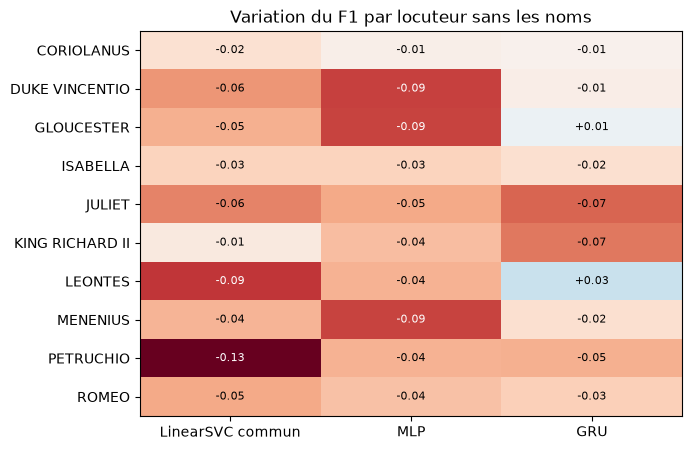

In [63]:
# Variation du F1 de chaque locuteur quand les noms disparaissent, pour les trois modèles.
variation_noms = pd.DataFrame({
    base: metriques_par_classe(variante)['F1'] - metriques_par_classe(base)['F1']
    for base, variante in SANS_NOMS.items()})
display(variation_noms.round(3))

borne = variation_noms.abs().to_numpy().max()
fig, ax = plt.subplots(figsize=(7, 5))
ax.imshow(variation_noms, cmap='RdBu', vmin=-borne, vmax=borne, aspect='auto')
for (ligne, colonne), valeur in np.ndenumerate(variation_noms.to_numpy()):
    ax.text(colonne, ligne, f'{valeur:+.2f}', ha='center', va='center', fontsize=8,
            color='white' if abs(valeur) > 0.6 * borne else 'black')
ax.set_xticks(range(len(SANS_NOMS)), list(SANS_NOMS))
ax.set_yticks(range(len(CLASSES)), CLASSES)
ax.set_title('Variation du F1 par locuteur sans les noms')
plt.show()

> *Mes observations :*
>
> Pour LinearSVC, PETRUCHIO perd le plus, 0,127, puis LEONTES, 0,091. Pour le MLP, les plus fortes baisses touchent DUKE VINCENTIO, GLOUCESTER et MENENIUS, de 0,085 à 0,087, alors que PETRUCHIO ne perd que 0,044. Le GRU perd surtout sur JULIET et KING RICHARD II, 0,073 et 0,067, et gagne un peu sur LEONTES et GLOUCESTER.
>
> *Ma conclusion :* mon hypothèse tient pour LinearSVC, qui reconnaît PETRUCHIO par « kate ». Il reconnaît aussi LEONTES par des noms comme « paulina » et « camillo », que le TP1 relevait déjà. Le MLP perd surtout sur les trois locuteurs les plus fréquents, donc les noms ne l'aident pas sur les mêmes classes.

Je mélange les tokens de chaque réplique avec un générateur fixé par son indice, donc tous les modèles voient le même texte mélangé. J'ajoute LinearSVC en unigrammes seuls, car les bigrammes de `LinearSVC commun` dépendent de l'ordre.

> *Mon hypothèse :* si H2 tient, le GRU et les bigrammes baissent, alors que le MLP et les unigrammes ne bougent pas, car ils ignorent l'ordre.

In [64]:
# Expérience 2 : tokens mélangés dans chaque réplique, même perturbation pour tous les modèles.
evaluer_ml('LinearSVC unigrammes', partial(construire_svc_experience, unigrammes=True))
evaluer_ml('LinearSVC unigrammes mélangé',
           partial(construire_svc_experience, ajuster_melange, unigrammes=True))
evaluer_ml('LinearSVC commun mélangé', partial(construire_svc_experience, ajuster_melange))
evaluer_reseau('MLP mélangé', MoyenneMLP, dict(REGLAGES_MLP, pretraitement=ajuster_melange))
evaluer_reseau('GRU mélangé', GRU, dict(REGLAGES, pretraitement=ajuster_melange))
MELANGES = {'LinearSVC unigrammes': 'LinearSVC unigrammes mélangé',
            'LinearSVC commun': 'LinearSVC commun mélangé', 'MLP': 'MLP mélangé',
            'GRU': 'GRU mélangé'}
experience_ordre = pd.DataFrame([comparer_experience(base, variante)
                                 for base, variante in MELANGES.items()]).set_index('Variante')
display(experience_ordre.round(3))

,F1 base,F1 variante,Écart moyen,Folds en baisse,Epoch variante,F1 train variante,p-value McNemar
Variante,,,,,,,
LinearSVC unigrammes mélangé,0.464,0.464,0.000,0,NaN,1.0,1.0e+00
LinearSVC commun mélangé,0.475,0.445,-0.030,4,NaN,1.0,1.6e-01
MLP mélangé,0.376,0.377,0.001,2,80.0,1.0,1.0e+00
GRU mélangé,0.206,0.199,-0.007,3,37.0,1.0,1.0e+00


> *Mes observations :*
>
> LinearSVC en unigrammes donne exactement le même F1, 0,464, avec ou sans mélange, et aucun désaccord, ce qui contrôle le mélange. Avec les bigrammes, `LinearSVC commun` perd 0,030 et baisse dans quatre folds, mais sa p-value vaut 0,16. Le MLP bouge de +0,001, car sa moyenne ignore l'ordre, et seuls l'ordre des additions et la troncature des plus longues répliques changent. Le GRU perd 0,007, avec une p-value la plus forte de 1,0.
>
> *Ma conclusion :* le mélange ne dégrade pas le GRU, donc il n'exploite pas l'ordre des mots sur 615 répliques. H2 se vérifie dans sa logique, car le GRU ne dépasse pas le MLP faute d'utiliser l'ordre, mais pas dans la baisse que je prévoyais. Seuls les bigrammes de LinearSVC tirent un peu d'ordre, sans écart significatif.

Je réduis le train de chaque fold à 25, 50 et 75 %, par un tirage stratifié de seed 42, et je garde toute la validation. Une epoch compte alors moins de batches, donc je divise le plafond de 100 epochs par la part du train, pour garder le même nombre de mises à jour.

> *Mon hypothèse :* si les réseaux manquent de données, l'écart entre le MLP et LinearSVC se réduit quand le train grandit.

In [65]:
# Expérience 3 : 25, 50 et 75 % du train de chaque fold pour LinearSVC commun et le MLP.
PARTS = (0.25, 0.5, 0.75, 1.0)


def nom_part(modele: str, part: float) -> str:
    """Nom du registre pour un modèle entraîné sur une part du train."""
    return modele if part == 1.0 else f'{modele} {100 * part:.0f} %'


def ligne_part(modele: str, part: float) -> dict:
    """F1 macro, dispersion, F1 train, epoch et plafond d'un modèle pour une part du train."""
    bilan = ligne_bilan(nom_part(modele, part))
    ligne = {'Modèle': modele, 'Part du train (%)': 100 * part,
             'Répliques de train (fold 1)': len(reduire_folds(part)[0]['train']),
             'F1 macro': bilan['F1 macro'], 'F1 écart-type': bilan['F1 écart-type'],
             'F1 train': bilan['F1 train'], 'Epoch retenue': bilan['Epoch retenue']}
    if bilan['Famille'] == 'DL':
        ligne['Monte encore'] = resumer_courbe(nom_part(modele, part), REGLAGES_MLP)['Monte encore']
    return ligne


for part in PARTS[:-1]:
    plis = reduire_folds(part)
    evaluer_ml(nom_part('LinearSVC commun', part), partial(construire_svc, 'commun'), plis)
    # Plafond divisé par la part, pour garder le même nombre de mises à jour qu'à 100 %
    reglages_part = dict(REGLAGES_MLP, epochs_max=round(REGLAGES_MLP['epochs_max'] / part))
    evaluer_reseau(nom_part('MLP', part), MoyenneMLP, reglages_part, plis)
quantite = pd.DataFrame([ligne_part(modele, part) for modele in ('LinearSVC commun', 'MLP')
                         for part in PARTS])
display(quantite.set_index(['Modèle', 'Part du train (%)']).round(3))

Répliques de train (fold 1)  F1 macro  \
Modèle           Part du train (%)                                          
LinearSVC commun 25.0                                       153     0.312   
                 50.0                                       307     0.394   
                 75.0                                       461     0.433   
                 100.0                                      615     0.475   
MLP              25.0                                       153     0.233   
                 50.0                                       307     0.295   
                 75.0                                       461     0.346   
                 100.0                                      615     0.376   

                                    F1 écart-type  F1 train  Epoch retenue  \
Modèle           Part du train (%)                                           
LinearSVC commun 25.0                       0.051       1.0            NaN   
                 50.0                       0.051       1.0            NaN   
                 75.0                       0.029       1.0            NaN   
                 100.0                      0.039       1.0            NaN   
MLP              25.0                       0.024       1.0           98.0   
                 50.0                       0.024       1.0           99.0   
                 75.0                       0.024       1.0           62.0   
                 100.0                      0.016       1.0           62.0   

                                   Monte encore  
Modèle           Part du train (%)               
LinearSVC commun 25.0                       NaN  
                 50.0                       NaN  
                 75.0                       NaN  
                 100.0                      NaN  
MLP              25.0                     False  
                 50.0                     False  
                 75.0                     False  
                 100.0                    False

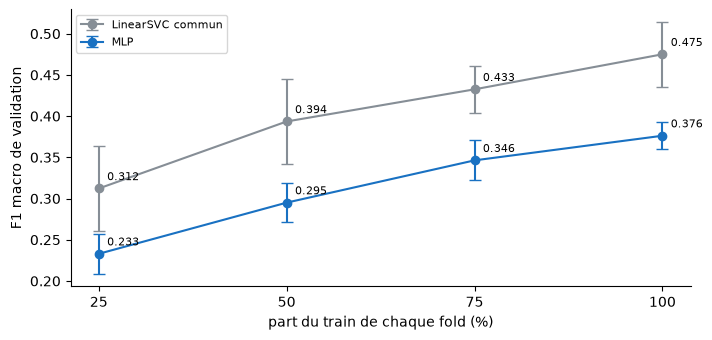

In [66]:
# Courbe d'apprentissage : F1 macro selon la part du train, avec l'écart-type entre folds.
fig, ax = plt.subplots(figsize=(8, 3.6))
for modele, lignes in quantite.groupby('Modèle', sort=False):
    ax.errorbar(lignes['Part du train (%)'], lignes['F1 macro'], yerr=lignes['F1 écart-type'],
                marker='o', capsize=4, color=COULEURS[modele], label=modele)
    for part, f1 in zip(lignes['Part du train (%)'], lignes['F1 macro']):
        ax.annotate(f'{f1:.3f}', (part, f1), textcoords='offset points', xytext=(6, 6), fontsize=8)
ax.set_xticks([100 * part for part in PARTS])
ax.set(xlabel='part du train de chaque fold (%)', ylabel='F1 macro de validation')
ax.legend(fontsize=8)
ax.spines[['top', 'right']].set_visible(False)
plt.show()

> *Mes observations :*
>
> Les deux modèles progressent à chaque quart de train. LinearSVC passe de 0,312 à 0,475, et le MLP de 0,233 à 0,376. L'écart entre eux vaut 0,079 à 25 %, puis 0,099, 0,087 et 0,099. Entre 75 et 100 %, LinearSVC gagne encore 0,042 et le MLP 0,030, donc aucune courbe ne plafonne. Le MLP ne monte plus à son plafond d'epochs, quelle que soit la part.
>
> *Ma conclusion :* mon hypothèse est réfutée, car l'écart ne se réduit pas quand le train grandit. Plus de répliques aideraient les deux modèles, mais ce jeu ne montre aucun signe que le MLP rattraperait LinearSVC.

Je teste enfin le dropout à 0,3, puis le weight decay à 1e-4, sur le MLP. Je monte leur plafond à 200 epochs, car une régularisation ralentit l'apprentissage, et l'epoch retenue reste choisie sur la validation. Le dropout met à zéro une part des activations à chaque pas d'entraînement, et le weight decay tire les poids vers zéro.

> *Mon hypothèse :* ils réduisent l'écart train/validation de 0,624, mais ils montent peu le F1 de validation.

In [67]:
# Expérience 4 : dropout 0,3 puis weight decay 1e-4 sur le MLP, un réglage à la fois.
REGLAGES_REGULARISES = dict(REGLAGES_MLP, epochs_max=200)  # Apprentissage ralenti
evaluer_reseau('MLP dropout 0,3', MoyenneMLP, dict(REGLAGES_REGULARISES, dropout=0.3))
evaluer_reseau('MLP weight decay 1e-4', MoyenneMLP, dict(REGLAGES_REGULARISES, weight_decay=1e-4))
REGULARISATION = ['MLP', 'MLP dropout 0,3', 'MLP weight decay 1e-4']
display(pd.DataFrame([ligne_modele(nom) for nom in REGULARISATION]).set_index('Modèle').round(3))
display(pd.DataFrame([resumer_courbe(nom, REGLAGES_MLP) for nom in REGULARISATION])
        .set_index('Modèle').round(3).T)
display(pd.DataFrame([comparer_experience('MLP', variante) for variante in REGULARISATION[1:]])
        .set_index('Variante').round(3))

,Paramètres (fold 1),Epoch retenue,F1 train,F1 macro,Écart-type entre folds,Écart-type entre seeds,Écart train/validation,Temps total (s)
Modèle,,,,,,,,
MLP,135370,62,1.000,0.376,0.016,0.031,0.624,61.861
"MLP dropout 0,3",135370,141,1.000,0.410,0.034,0.027,0.590,190.262
MLP weight decay 1e-4,135370,58,0.995,0.367,0.026,0.037,0.628,125.430


Modèle,MLP,"MLP dropout 0,3",MLP weight decay 1e-4
Epochs,100,200,200
Epoch retenue,62,141,58
Epoch du maximum,80,193,130
F1 validation maximal,0.381,0.413,0.371
Epoch de loss validation minimale,20,34,26
F1 validation à cette epoch,0.3,0.331,0.299
Gain des 10 dernières epochs,-0.002,0.001,0.005
Monte encore,False,False,False


,F1 base,F1 variante,Écart moyen,Folds en baisse,Epoch variante,F1 train variante,p-value McNemar
Variante,,,,,,,
"MLP dropout 0,3",0.376,0.410,0.034,0,141,1.000,1.9e-02
MLP weight decay 1e-4,0.376,0.367,-0.009,4,58,0.995,9.1e-01


> *Mes observations :*
>
> Le dropout à 0,3 monte le F1 macro de 0,376 à 0,410, ne baisse dans aucun fold, avec une p-value la plus forte de 0,019. Son epoch retenue passe de 62 à 141, et sa courbe ne gagne plus que 0,001 sur les 10 dernières epochs, donc le plafond de 200 suffit. Son F1 train reste à 1, et l'écart train/validation ne descend que de 0,624 à 0,590. Le weight decay à 1e-4 donne 0,367, baisse dans quatre folds et laisse l'écart à 0,628.
>
> *Ma conclusion :* mon hypothèse est en partie réfutée, car le dropout réduit à peine la mémorisation mais améliore le F1 de validation de 0,034, de façon significative. Le weight decay à cette valeur n'aide pas. Je fige donc pour la section 4.4 le MLP avec dropout 0,3, plafond de 200 epochs et epoch retenue 141.
>
> *Mon hypothèse :* le dropout oblige le MLP à répartir l'information sur plus de dimensions de la moyenne, au lieu de s'appuyer sur quelques mots du train.

> *Ma conclusion :* les quatre expériences précisent ce que les modèles apprennent. Les noms portent environ 0,05 de F1 macro pour LinearSVC et le MLP, mais pas l'essentiel du signal. Le GRU n'exploite pas l'ordre des mots, et les bigrammes n'en tirent qu'un gain non significatif. Plus de données aident LinearSVC et le MLP au même rythme, donc l'écart entre eux ne vient pas seulement du manque de répliques. Le dropout est le seul changement qui améliore le MLP, de 0,376 à 0,410. Je fige pour la section 4.4 `LinearSVC commun`, le MLP avec dropout 0,3 et le GRU, chacun avec son epoch retenue.

### 4.4 Figer les choix et évaluer sur le test

Je choisis les configurations sur le F1 macro moyen en validation, avec leur dispersion et leur coût. Chaque réseau retenu prend son epoch retenue, reconstruit son vocabulaire sur les 769 répliques et se réentraîne depuis une nouvelle initialisation, sans utiliser le test pour s'arrêter. Une epoch sur 769 répliques compte 25 % de mises à jour de plus qu'une epoch de fold, et je le signale sans le corriger.

Les références ML sont réajustées sur les 769 répliques. Je compare les choix figés sur les 193 répliques de test, avec le repère du TP1 de 0,563 de F1 macro pour LinearSVC, puis j'analyse les erreurs sans relancer de réglage.

Ce test a déjà servi au TP1 pour choisir LinearSVC, donc la comparaison reste exploratoire, et les hypothèses tirées de ses erreurs ne le rendent pas indépendant.


Je reprends les trois choix figés dans la section 4.3, plus deux repères. Le repère majoritaire donne le plancher, et `LinearSVC TP1` doit retrouver son F1 macro du TP1 sur ce test, ce qui contrôle le découpage et le pipeline.

In [68]:
# Les cinq modèles figés pour le test : constructeur et, pour un réseau, réglages de validation.
FIGES = {
    'Majoritaire': {'construire': lambda: DummyClassifier(strategy='most_frequent')},
    'LinearSVC TP1': {'construire': partial(construire_svc, 'TP1')},
    'LinearSVC commun': {'construire': partial(construire_svc, 'commun')},
    'MLP dropout 0,3': {'construire': MoyenneMLP,
                        'reglages': dict(REGLAGES_REGULARISES, dropout=0.3)},
    'GRU': {'construire': GRU, 'reglages': REGLAGES},
}

# Bilan de validation des modèles figés, puis taille d'une epoch sur les 769 répliques
display(pd.DataFrame([ligne_bilan(nom) for nom in FIGES]).set_index('Modèle')
        .astype({'Epoch retenue': 'Int64', 'Paramètres (fold 1)': 'Int64'}).round(3))
batches_fold = math.ceil(len(folds[0]['train']) / REGLAGES['taille_batch'])
batches_final = math.ceil(len(X_train) / REGLAGES['taille_batch'])
print(f'Une epoch compte {batches_final} batches sur les 769 répliques, contre {batches_fold} '
      f'dans un fold, soit {pourcentage(batches_final - batches_fold, batches_fold):.0f} % '
      f'de mises à jour en plus')

,Famille,F1 train,F1 macro,F1 écart-type,Accuracy,Accuracy écart-type,Epoch retenue,Paramètres (fold 1),Temps total (s)
Modèle,,,,,,,,,
Majoritaire,ML,0.024,0.024,0.001,0.134,0.003,<NA>,<NA>,0.020
LinearSVC TP1,ML,1.000,0.482,0.039,0.492,0.041,<NA>,48620,0.379
LinearSVC commun,ML,1.000,0.475,0.039,0.484,0.038,<NA>,50260,0.290
"MLP dropout 0,3",DL,1.000,0.410,0.034,0.422,0.036,141,135370,190.262
GRU,DL,1.000,0.206,0.027,0.213,0.026,31,156170,465.391


Une epoch compte 25 batches sur les 769 répliques, contre 20 dans un fold, soit 25 % de mises à jour en plus


Le MLP figé arrive à 0,410 de F1 macro en validation à l'epoch 141, et le GRU à 0,206 à l'epoch 31. Une epoch sur les 769 répliques compte 25 batches contre 20 dans un fold, soit 25 % de mises à jour en plus, et je le laisse ainsi comme prévu.

Chaque réseau repart d'une initialisation neuve pour chacune de ses trois seeds. Il construit son vocabulaire sur les 769 répliques et s'entraîne exactement jusqu'à son epoch retenue, sans aucune mesure sur le test. Pour lire l'incertitude d'un score sur 193 répliques, je tire 1 000 échantillons avec remise de ces répliques, les mêmes pour tous les modèles. Je garde l'intervalle à 95 % du F1 macro.

In [69]:
# Outils du test : réentraînement sur les 769 répliques, une seule prédiction du test, intervalles.
resultats_test = {}  # nom -> prédictions du test par seed et temps
TIRAGES_BOOTSTRAP = 1000


def entrainer_final(construire_modele, reglages: dict, epochs: int, seed: int) -> pd.Series:
    """Réseau neuf entraîné sur les 769 répliques pendant `epochs`, puis une prédiction du test."""
    fixer_seed(seed)
    vocabulaire = construire_vocabulaire(X_train)
    longueur_max = longueur_maximale(X_train, reglages['quantile_longueur'])
    train = construire_chargeur(JeuRepliques(X_train, y_train, vocabulaire, longueur_max),
                                reglages, True, seed)
    test = construire_chargeur(JeuRepliques(X_test, y_test, vocabulaire, longueur_max),
                               reglages, False, seed)
    modele = construire_modele(len(vocabulaire), reglages).to(reglages['device'])
    optimiseur = torch.optim.Adam(modele.parameters(), lr=reglages['taux_apprentissage'],
                                  weight_decay=reglages['weight_decay'])
    for _ in range(epochs):  # Aucune mesure sur le test pendant l'entraînement
        entrainer_epoch(modele, train, optimiseur, reglages)
    predictions = evaluer_modele(modele, test, reglages['device'])['predictions']
    return pd.Series([CLASSES[indice] for indice in predictions], index=X_test.index)


def evaluer_test(nom: str) -> None:
    """Réajuste un modèle figé sur les 769 répliques et garde ses prédictions du test par seed."""
    choix, debut = FIGES[nom], time.perf_counter()
    if 'reglages' in choix:
        epoch = resultats[nom]['epoch']  # Epoch retenue en validation croisée
        jeux = [entrainer_final(choix['construire'], choix['reglages'], epoch, seed)
                for seed in choix['reglages']['seeds']]
    else:
        pipeline = choix['construire']().fit(X_train, y_train)
        jeux = [pd.Series(pipeline.predict(X_test), index=X_test.index)]
    resultats_test[nom] = {'predictions': jeux, 'temps': time.perf_counter() - debut}


def jeux_test(nom: str) -> list:
    """Prédictions du test d'un modèle figé, une série par seed."""
    return resultats_test[nom]['predictions']


def intervalle_bootstrap(jeux: list, vrais: pd.Series) -> tuple:
    """Intervalle à 95 % du F1 macro moyen des seeds, mêmes tirages pour tous les modèles."""
    generateur = np.random.default_rng(RANDOM_STATE)
    tirages = generateur.integers(0, len(vrais), (TIRAGES_BOOTSTRAP, len(vrais)))
    valeurs = [np.mean([f1_score(vrais.iloc[t], jeu.iloc[t], average='macro', zero_division=0)
                        for jeu in jeux]) for t in tirages]
    return tuple(np.percentile(valeurs, [2.5, 97.5]))

Je réajuste maintenant les cinq modèles et je mesure le test une seule fois.

In [70]:
# Les cinq modèles figés sur les 193 répliques de test, face à leur validation.


def ligne_test(nom: str) -> dict:
    """F1 macro et accuracy du test, écart entre seeds, intervalle et F1 de validation."""
    jeux = jeux_test(nom)
    f1 = [f1_score(y_test, jeu, average='macro', zero_division=0) for jeu in jeux]
    bas, haut = intervalle_bootstrap(jeux, y_test)
    return {'Modèle': nom, 'Epoch': resultats[nom].get('epoch'),
            'F1 validation': ligne_bilan(nom)['F1 macro'], 'F1 test': np.mean(f1),
            'Écart-type entre seeds': np.std(f1, ddof=1) if len(f1) > 1 else np.nan,
            'Intervalle 95 % bas': bas, 'Intervalle 95 % haut': haut,
            'Accuracy test': np.mean([accuracy_score(y_test, jeu) for jeu in jeux]),
            'Temps (s)': resultats_test[nom]['temps']}


for nom in FIGES:
    evaluer_test(nom)
bilan_test = pd.DataFrame([ligne_test(nom) for nom in FIGES]).set_index('Modèle')
display(bilan_test.astype({'Epoch': 'Int64'}).round(3))

,Epoch,F1 validation,F1 test,Écart-type entre seeds,Intervalle 95 % bas,Intervalle 95 % haut,Accuracy test,Temps (s)
Modèle,,,,,,,,
Majoritaire,<NA>,0.024,0.024,NaN,0.016,0.031,0.135,0.000
LinearSVC TP1,<NA>,0.482,0.563,NaN,0.487,0.624,0.565,0.046
LinearSVC commun,<NA>,0.475,0.505,NaN,0.422,0.565,0.508,0.047
"MLP dropout 0,3",141,0.410,0.416,0.014,0.346,0.471,0.421,25.955
GRU,31,0.206,0.207,0.012,0.165,0.241,0.211,81.086


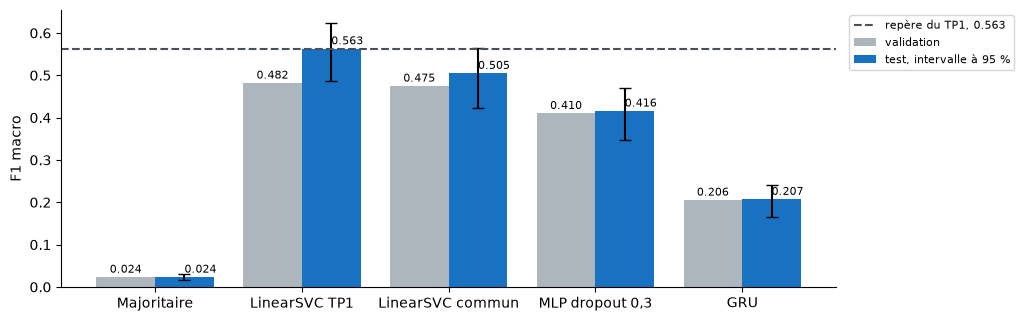

In [71]:
# F1 macro de validation et de test, avec l'intervalle à 95 % du test et le repère du TP1.
REPERE_TP1 = 0.563  # F1 macro de LinearSVC sur ce test au TP1
positions = np.arange(len(bilan_test))
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.bar(positions - 0.2, bilan_test['F1 validation'], 0.4, color='#adb5bd', label='validation')
erreurs = [bilan_test['F1 test'] - bilan_test['Intervalle 95 % bas'],
           bilan_test['Intervalle 95 % haut'] - bilan_test['F1 test']]
ax.bar(positions + 0.2, bilan_test['F1 test'], 0.4, yerr=erreurs, capsize=4, color='#1971c2',
       label='test, intervalle à 95 %')
valeurs = zip(bilan_test['F1 validation'], bilan_test['F1 test'])
for position, (validation, test) in enumerate(valeurs):
    ax.text(position - 0.2, validation + 0.01, f'{validation:.3f}', ha='center', fontsize=8)
    ax.text(position + 0.2, test + 0.01, f'{test:.3f}', ha='left', fontsize=8)
ax.axhline(REPERE_TP1, linestyle='--', color='#495057', label=f'repère du TP1, {REPERE_TP1}')
ax.set_xticks(positions, bilan_test.index)
ax.set_ylabel('F1 macro')
ax.legend(fontsize=8, loc='upper left', bbox_to_anchor=(1.01, 1))
ax.spines[['top', 'right']].set_visible(False)
plt.show()

> *Mes observations :*
>
> `LinearSVC TP1` retrouve exactement son F1 macro du TP1, 0,563, donc le découpage et le pipeline sont bien ceux du TP1. `LinearSVC commun` obtient 0,505, le MLP figé 0,416 et le GRU 0,207, dans le même ordre qu'en validation. Le test dépasse la validation de 0,030 pour LinearSVC commun et de 0,006 pour le MLP, et le GRU ne bouge presque pas. Les intervalles à 95 % sont larges, de 0,422 à 0,565 pour LinearSVC commun et de 0,346 à 0,471 pour le MLP, donc ils se recouvrent de 0,422 à 0,471. L'écart-type entre les trois seeds du MLP ne vaut que 0,014 sur le test.
>
> *Ma conclusion :* les choix figés tiennent sur le test, sans chute de la validation au test qui signalerait des réglages trop ajustés aux folds. Le MLP reste à 0,089 sous LinearSVC commun, mais leurs intervalles se recouvrent, donc 193 répliques ne suffisent pas à les départager.

Comme dans la section 4.1, je compte les répliques de test où un seul des deux modèles a raison, puis je teste ce déséquilibre avec McNemar.

In [72]:
# Répliques de test où un seul des deux modèles a raison, puis test de McNemar exact.
PAIRES_TEST = [('LinearSVC commun', 'MLP dropout 0,3'), ('LinearSVC commun', 'GRU'),
               ('MLP dropout 0,3', 'GRU')]
display(pd.DataFrame([comparer_paire(a, b, jeux_test, y_test) for a, b in PAIRES_TEST])
        .set_index(['A', 'B']).round(1))

A seul juste  B seul juste  Deux justes  \
A                B                                                          
LinearSVC commun MLP dropout 0,3          33.0          16.3         65.0   
                 GRU                      74.0          16.7         24.0   
MLP dropout 0,3  GRU                      60.0          19.3         21.3   

                                  Deux faux p-value maximale  
A                B                                            
LinearSVC commun MLP dropout 0,3       78.7          6.0e-02  
                 GRU                   78.3          7.7e-09  
MLP dropout 0,3  GRU                   92.3          1.7e-05

> *Mes observations :*
>
> Sur le test, `LinearSVC commun` a seul raison sur 33,0 répliques, contre 16,3 pour le MLP figé en moyenne sur ses seeds, mais la p-value la plus forte vaut 0,060. Face au GRU, LinearSVC a seul raison sur 74,0 répliques contre 16,7, avec une p-value de 7,7 × 10⁻⁹. Le MLP a seul raison sur 60,0 répliques contre 19,3 pour le GRU, avec 1,7 × 10⁻⁵.
>
> *Ma conclusion :* l'avance de LinearSVC sur le MLP figé n'est pas significative au seuil de 5 % pour au moins une seed. L'avance des deux modèles sur le GRU l'est nettement. Le dropout a donc rapproché le MLP de LinearSVC, sans le rattraper.

Je compare ensuite le F1 de chaque locuteur entre validation et test. Une classe de test ne compte que 16 à 26 répliques, donc un écart par classe reste fragile.

In [73]:
# F1 de chaque locuteur sur le test, à côté de la validation, pour les trois modèles figés.
FIGES_ANALYSE = ['LinearSVC commun', 'MLP dropout 0,3', 'GRU']
f1_classes_test = pd.concat({nom: pd.DataFrame({
    'Validation': metriques_par_classe(nom)['F1'],
    'Test': metriques_par_classe(nom, jeux_test, y_test)['F1']}) for nom in FIGES_ANALYSE}, axis=1)
f1_classes_test['Support test'] = y_test.value_counts().reindex(CLASSES)
display(f1_classes_test.round(3))

LinearSVC commun        MLP dropout 0,3               GRU  \
                      Validation   Test      Validation   Test Validation   
CORIOLANUS                 0.438  0.645           0.393  0.517      0.253   
DUKE VINCENTIO             0.520  0.557           0.536  0.424      0.259   
GLOUCESTER                 0.495  0.577           0.398  0.480      0.189   
ISABELLA                   0.491  0.516           0.353  0.206      0.147   
JULIET                     0.378  0.353           0.298  0.435      0.203   
KING RICHARD II            0.533  0.429           0.455  0.464      0.192   
LEONTES                    0.389  0.643           0.285  0.398      0.104   
MENENIUS                   0.487  0.571           0.510  0.433      0.288   
PETRUCHIO                  0.650  0.350           0.539  0.450      0.246   
ROMEO                      0.392  0.410           0.364  0.354      0.201   

                       Support test  
                  Test               
CORIOLANUS       0.164           17  
DUKE VINCENTIO   0.228           25  
GLOUCESTER       0.171           26  
ISABELLA         0.143           16  
JULIET           0.339           17  
KING RICHARD II  0.086           16  
LEONTES          0.256           16  
MENENIUS         0.248           22  
PETRUCHIO        0.165           19  
ROMEO            0.274           19

> *Mes observations :*
>
> Avec 16 à 26 répliques par classe, le F1 de test bouge fortement d'une classe à l'autre. Pour `LinearSVC commun`, PETRUCHIO tombe de 0,650 à 0,350, alors que LEONTES monte de 0,389 à 0,643 et CORIOLANUS de 0,438 à 0,645. Le MLP figé baisse surtout sur ISABELLA, de 0,353 à 0,206, et monte sur CORIOLANUS, de 0,393 à 0,517. Le GRU reste sous 0,34 pour tous les locuteurs.
>
> *Ma conclusion :* les écarts par classe entre validation et test dépassent souvent 0,1, donc je ne conclus rien sur une classe isolée du test. La chute de PETRUCHIO pour LinearSVC rappelle que son score reposait en partie sur « kate » (section 4.3), mais 19 répliques ne suffisent pas à le confirmer.

Je trace les matrices de confusion du test pour les trois modèles figés, avec les mêmes conventions que dans la section 4.1, puis je relève leurs plus fortes confusions.

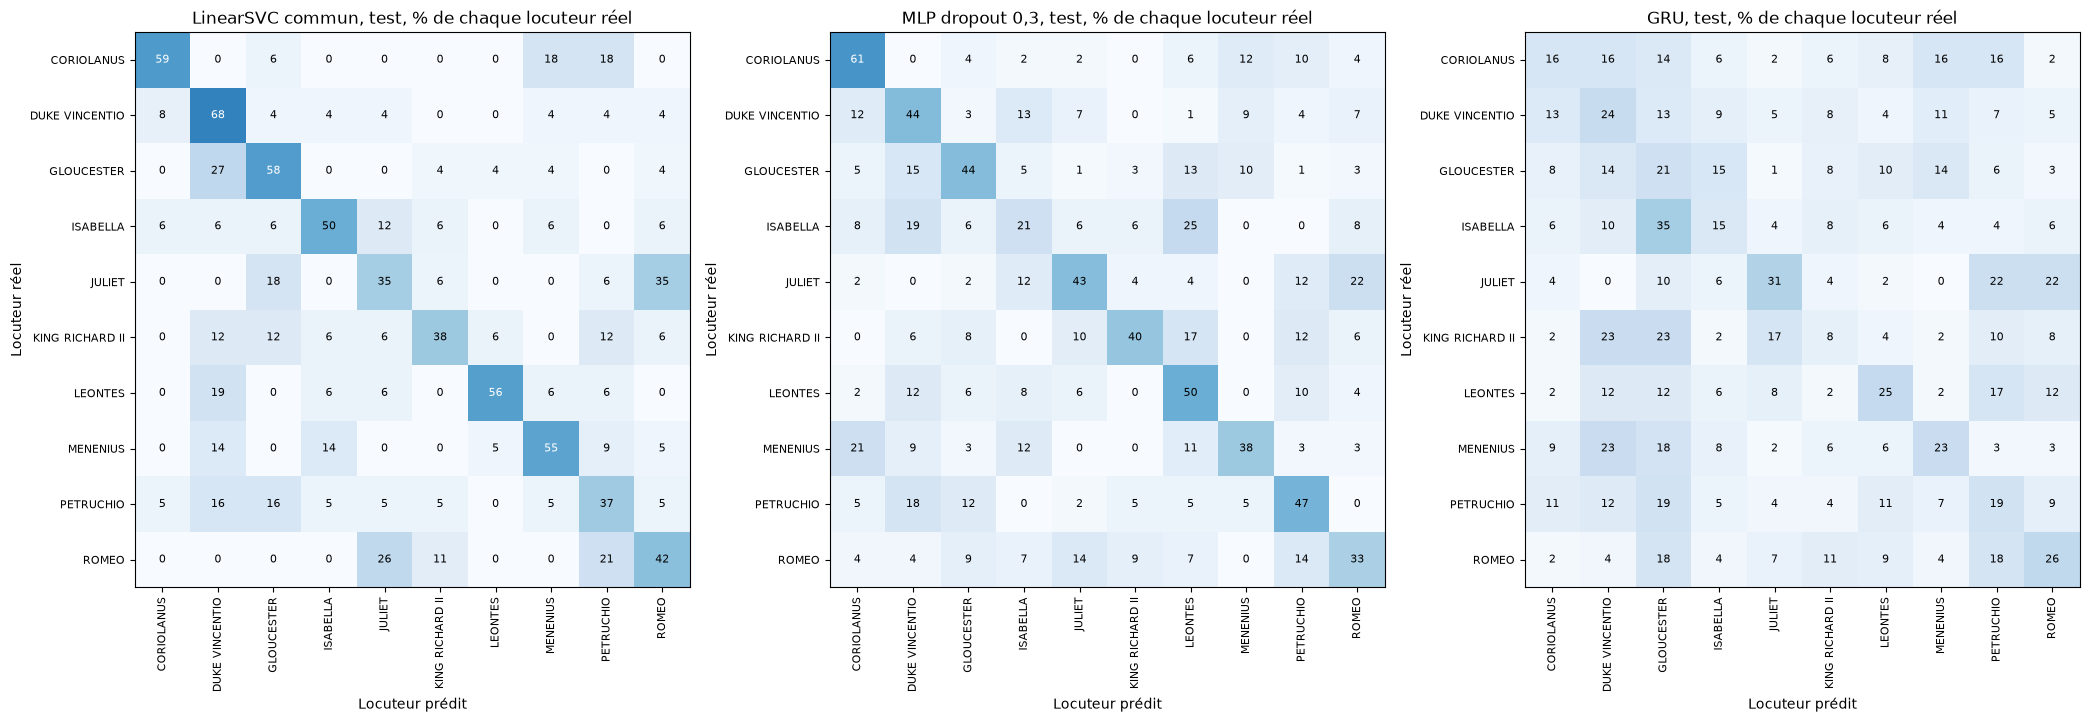

In [74]:
# Matrices de confusion du test pour les trois modèles figés, en % de chaque locuteur réel.
matrices_test = {nom: matrice_confusion(nom, jeux_test, y_test) for nom in FIGES_ANALYSE}
fig, axes = plt.subplots(1, 3, figsize=(21, 7))
for axe, (nom, matrice) in zip(axes, matrices_test.items()):
    tracer_matrice(axe, f'{nom}, test', matrice)
plt.tight_layout()
plt.show()

In [75]:
# Plus fortes confusions du test et couples suivis depuis le TP1, seeds sommées pour les réseaux.
decrire_confusions(matrices_test)

LinearSVC commun : rappel moyen 49.7 %
   plus fortes confusions
      JULIET → ROMEO : 35.3 % (6 sur 17)
      GLOUCESTER → DUKE VINCENTIO : 26.9 % (7 sur 26)
      ROMEO → JULIET : 26.3 % (5 sur 19)
   couples suivis depuis le TP1
      JULIET → ROMEO : 35.3 % (6 sur 17)
      ROMEO → JULIET : 26.3 % (5 sur 19)
      GLOUCESTER → DUKE VINCENTIO : 26.9 % (7 sur 26)
      DUKE VINCENTIO → GLOUCESTER : 4.0 % (1 sur 25)
MLP dropout 0,3 : rappel moyen 42.1 %
   plus fortes confusions
      ISABELLA → LEONTES : 25.0 % (12 sur 48)
      JULIET → ROMEO : 21.6 % (11 sur 51)
      MENENIUS → CORIOLANUS : 21.2 % (14 sur 66)
   couples suivis depuis le TP1
      JULIET → ROMEO : 21.6 % (11 sur 51)
      ROMEO → JULIET : 14.0 % (8 sur 57)
      GLOUCESTER → DUKE VINCENTIO : 15.4 % (12 sur 78)
      DUKE VINCENTIO → GLOUCESTER : 2.7 % (2 sur 75)
GRU : rappel moyen 20.8 %
   plus fortes confusions
      ISABELLA → GLOUCESTER : 35.4 % (17 sur 48)
      KING RICHARD II → DUKE VINCENTIO : 22.9 % (11 s

> *Mes observations :*
>
> Pour `LinearSVC commun`, la diagonale domine chaque ligne sauf JULIET, partagée à égalité entre JULIET et ROMEO, à 35 %. Son rappel moyen vaut 49,7 %. GLOUCESTER part vers DUKE VINCENTIO dans 26,9 % des cas, contre 12,6 % en validation (section 4.1), mais cela ne fait que 7 répliques sur 26.
>
> Pour le MLP figé, le rappel moyen vaut 42,1 %. La diagonale domine chaque ligne sauf ISABELLA, plus souvent prédite LEONTES, à 25 %, que bien classée, à 21 %. JULIET → ROMEO reste sa plus forte confusion parmi les couples du TP1, à 21,6 %.
>
> Pour le GRU, le rappel moyen reste à 20,8 %, et la diagonale ne domine plus. ISABELLA part vers GLOUCESTER dans 35,4 % des cas, et KING RICHARD II se partage entre DUKE VINCENTIO et GLOUCESTER, à 22,9 % chacun.
>
> *Ma conclusion :* sur le test, LinearSVC et le MLP gardent leur confusion de validation entre JULIET et ROMEO, et le GRU se replie encore sur les locuteurs fréquents. Pour LinearSVC, une réplique vaut 4 à 6 points de pourcentage dans une ligne, donc je ne lis que les cases les plus fortes.

Je vérifie enfin si les explications de la section 4.2 tiennent sur des répliques jamais vues. Les noms, le vocabulaire et les locuteurs par token viennent cette fois des 769 répliques de développement.

In [76]:
# Facteurs des répliques de test, listes ajustées sur les 769 répliques, puis groupes et pièces.
facteurs_test = facteurs_fold({'train': X_train.index, 'validation': X_test.index}, X_test)
facteurs_test['Nom'] = facteurs_test['Noms'].str.len() > 0
print(f'Répliques de test avec au moins un nom : '
      f'{pourcentage(facteurs_test["Nom"].sum(), len(facteurs_test)):.1f} %')

# Quatre groupes selon LinearSVC commun et le MLP figé, moyennés sur les seeds du MLP
svc_test = jeux_test('LinearSVC commun')[0]
tables_test = [facteurs_par_groupe(jeu, svc_test, y_test, facteurs_test)
               for jeu in jeux_test('MLP dropout 0,3')]
display(pd.concat(tables_test).groupby(level=0).mean().reindex(ORDRE_GROUPES).round(1))

# Erreurs du test qui restent dans la pièce, face au hasard
display(pd.DataFrame([part_intra(nom, jeux_test, y_test) for nom in FIGES_ANALYSE])
        .set_index('Modèle').round(2))

Répliques de test avec au moins un nom : 32.6 %


,Répliques,Longueur,Avec un nom (%),Inconnus (%),Partagés (%)
Groupe,,,,,
Deux justes,65.0,58.6,50.4,12.0,56.5
LinearSVC seul juste,33.0,41.3,31.4,12.3,56.2
MLP seul juste,16.3,52.7,45.6,11.6,56.4
Deux faux,78.7,38.5,16.1,12.2,57.6


,Erreurs,Dans la pièce (%),Hasard (%),Rapport au hasard
Modèle,,,,
LinearSVC commun,95.00,20.00,8.42,2.38
"MLP dropout 0,3",111.67,20.60,9.64,2.14
GRU,152.33,10.05,9.00,1.12


> *Mes observations :*
>
> Au moins un nom apparaît dans 32,6 % des répliques de test. Les répliques justes pour les deux modèles contiennent un nom dans 50,4 % des cas, contre 16,1 % des erreurs communes, et elles sont plus longues, 58,6 tokens contre 38,5. Les 16,3 répliques que seul le MLP trouve contiennent un nom dans 45,6 % des cas, contre 31,4 % pour les 33,0 que seul LinearSVC trouve. Les erreurs restent dans la pièce dans 20,0 % des cas pour LinearSVC et 20,6 % pour le MLP, contre 8,42 % et 9,64 % au hasard. Elles y restent dans 10,05 % des cas pour le GRU.
>
> *Ma conclusion :* les noms et la longueur expliquent encore les erreurs communes sur des répliques jamais vues. Avec le dropout, le MLP trouve seul des répliques nommées, à l'inverse de la section 4.2, mais sur 16,3 répliques seulement, donc je le note sans le généraliser. La pièce explique toujours environ une erreur sur cinq pour LinearSVC et le MLP, et presque rien pour le GRU.

> *Ma conclusion :* les choix figés en validation croisée se confirment sur le test, dans le même ordre. `LinearSVC commun` obtient 0,505 de F1 macro, le MLP avec dropout 0,416 et le GRU 0,207, et `LinearSVC TP1` retrouve son 0,563. Le MLP figé reste derrière LinearSVC, mais l'écart n'est pas significatif sur 193 répliques pour toutes les seeds. Le test ne contredit aucune conclusion de validation, et il reste exploratoire, car il avait déjà servi au TP1.

### 4.5 Mon journal d'expériences

Une ligne après chaque essai, et une hypothèse reste même si le résultat ne la confirme pas.

| Expérience | Hypothèse | Changement | Observation chiffrée | Décision |
|---|---|---|---|---|
| 1. Tokenizer commun (section 3.3) | « I » et les contractions aident LinearSVC | `token_pattern` par défaut remplacé par `tokeniser` | F1 macro 0,475 contre 0,482, écart moyen −0,007, 1 fold gagné sur 5, écart-type entre folds 0,039 | Hypothèse non confirmée. Tokenizer commun conservé comme référence des réseaux, car l'écart reste sous la dispersion entre folds |
| 2. Plafond d'epochs du MLP (section 3.4) | 40 epochs suffisent au MLP | Plafond relevé de 40 à 100 epochs | À 40, gain de 0,020 sur les 10 dernières epochs et maximum à l'epoch 38. À 100, gain de −0,002, epoch retenue 62, F1 macro de 0,358 à 0,376 | Plafond de 100 pour le MLP. Même critère de plafond pour le LSTM et le GRU, à partir de 40 |
| 3. MLP face à LinearSVC (H1 et H3, section 3.4) | Le MLP reste à moins de 0,05 de LinearSVC, et il mémorise le train en moins de 20 epochs | Moyenne des embeddings, couche cachée ReLU de 64, 3 seeds | F1 macro 0,376 ± 0,016 contre 0,475 ± 0,039, écart moyen −0,099, 0 fold gagné sur 5. F1 train de 0,99 atteint entre les epochs 41 et 49, écart train/validation de 0,604 à 0,644 | H1 réfutée. H3 tient pour l'écart, pas pour le délai. Poids égal des tokens dans la moyenne à tester dans les sections 4.2 et 4.3 |
| 4. Largeur cachée du MLP (section 3.4) | La largeur change peu le F1 macro | Largeurs 32 et 128 face à 64 | F1 macro 0,387, 0,376 et 0,378, écart de 0,011 au plus, sous l'écart-type entre seeds de 0,021 à 0,031 | Hypothèse confirmée. Largeur 64 gardée, commune aux trois réseaux |
| 5. LSTM face au MLP (H2 et H3, section 3.5) | Le LSTM dépasse le MLP, car il lit l'ordre des mots | LSTM unidirectionnel de 64, état final, 40 epochs, 3 seeds | F1 macro 0,206 ± 0,026 contre 0,376 pour le MLP, écart moyen −0,170, 0 fold gagné sur 5. F1 train de 0,99 entre les epochs 21 et 26, écart train/validation 0,792. Accuracy plate, de 0,206 à 0,223 selon la longueur | Hypothèse réfutée, H2 ouverte jusqu'à la section 4.3. H3 tient presque pour le LSTM. La mémorisation lente du MLP vient de la moyenne |
| 6. Norme du gradient (section 3.5) | Le plafonnement à 1 sert surtout aux réseaux récurrents | Norme avant plafonnement notée à chaque batch | LSTM : norme maximale 413,5, 51,2 % des batches plafonnés. MLP : 2,3 et 1,2 % | Hypothèse confirmée. Plafonnement gardé pour le GRU |
| 7. GRU face au LSTM (H4, section 3.6) | À largeur égale, le GRU a moins de paramètres, s'entraîne plus vite et garde un F1 macro comparable | Cellule GRU à la place du LSTM, tout le reste commun | 156 170 paramètres contre 164 490 sur le fold 1. F1 macro 0,206 ± 0,027 contre 0,206 ± 0,026, écart moyen −0,001, 2 folds gagnés sur 5. Environ 0,8 s par epoch pour les deux. 28,2 % de batches plafonnés contre 51,2 % | H4 tient pour les paramètres et le score, pas pour le temps. GRU gardé pour la section 4 |
| 8. Pièce ou style (section 4.2) | Le modèle reconnaît la pièce plutôt que le style (TP1, section 8.3) | Pièces reconstruites à partir des étiquettes du corpus, erreurs comparées au hasard | Erreurs dans la pièce : LinearSVC 18,6 % contre 9,1 % au hasard, MLP 15,0 % contre 8,9 %, GRU 11,1 % contre 8,9 %. Plus de 81 % des erreurs sortent de la pièce | Hypothèse en partie confirmée pour LinearSVC, faible pour les réseaux. La pièce n'explique qu'une erreur sur cinq |
| 9. Facteurs des erreurs (section 4.2) | Les noms, la longueur, les tokens inconnus ou le vocabulaire partagé expliquent les erreurs | Quatre groupes selon LinearSVC commun et le MLP, facteurs calculés sur le train de chaque fold | Avec un nom : 45,8 % des répliques justes pour les deux, 35,8 % pour LinearSVC seul, 22,4 % pour le MLP seul, 14,7 % des erreurs communes. Longueur de 60,3 à 39,0 tokens. Inconnus et partagés stables | Noms et longueur retenus comme explications. Masquage des noms en priorité dans la section 4.3 |
| 10. Noms masqués (section 4.3) | LinearSVC perd plus que le MLP sans les noms, et PETRUCHIO chute le plus | Noms de `detecter_noms` retirés, liste du train de chaque fold | LinearSVC 0,475 → 0,421 (−0,054, 5 folds en baisse, p 1,7 × 10⁻⁷), MLP 0,376 → 0,325 (−0,051), GRU 0,206 → 0,182 (−0,024). PETRUCHIO −0,127 pour LinearSVC, −0,044 pour le MLP | Hypothèse réfutée pour l'écart entre modèles, vraie pour PETRUCHIO avec LinearSVC. Les noms portent environ 0,05 de F1 |
| 11. Ordre des mots (H2, section 4.3) | Le GRU et les bigrammes baissent, le MLP et les unigrammes ne bougent pas | Tokens mélangés par un générateur fixé par l'indice de la réplique | Unigrammes 0,464 inchangé, bigrammes −0,030 (p 0,16), MLP +0,001, GRU −0,007 | Le GRU n'exploite pas l'ordre. H2 tient dans sa logique, pas dans la baisse prévue |
| 12. Quantité de données (section 4.3) | L'écart entre le MLP et LinearSVC se réduit quand le train grandit | 25, 50, 75 et 100 % du train, plafond d'epochs divisé par la part | Écart de 0,079, 0,099, 0,087 et 0,099. Les deux courbes montent encore à 100 % | Hypothèse réfutée. Plus de données aideraient les deux modèles autant |
| 13. Régularisation du MLP (section 4.3) | Dropout et weight decay réduisent l'écart train/validation sans monter le F1 | Dropout 0,3, puis weight decay 1e-4, plafond de 200 epochs | Dropout : F1 0,410 (+0,034, aucun fold en baisse, p 0,019), écart 0,590. Weight decay : F1 0,367, écart 0,628 | Hypothèse en partie réfutée. MLP avec dropout 0,3 figé pour la section 4.4 |
| 14. Test des choix figés (section 4.4) | Les choix figés en validation gardent leur ordre sur le test | Réentraînement sur les 769 répliques jusqu'à l'epoch retenue, une seule mesure des 193 répliques de test | LinearSVC TP1 0,563, LinearSVC commun 0,505 (de 0,422 à 0,565), MLP dropout 0,416 (de 0,346 à 0,471), GRU 0,207. McNemar LinearSVC contre MLP, p 0,060 | Ordre confirmé, écart LinearSVC contre MLP non significatif sur le test. Test exploratoire, déjà vu au TP1 |

### 4.6 Ce que je peux conclure

Je réponds à quatre questions, soit quel signal je prédis, ce que chaque modèle apprend réellement, sur quelles données il généralise et quelle métrique traduit le besoin. Quel modèle répond le mieux au problème, scores et coût compris ? Quelles hypothèses, de H1 à H4, mes expériences soutiennent-elles ? Qu'est-ce qui reste incertain sur le contexte, le style et la généralisation ?

Je résume d'abord les trois choix figés sur un seul graphique, score et coût réunis.

,F1 validation,Écart-type validation,F1 test,Intervalle 95 % bas,Intervalle 95 % haut,Paramètres (fold 1),Temps de validation (s)
Modèle,,,,,,,
LinearSVC commun,0.475,0.039,0.505,0.422,0.565,50260,0.290
"MLP dropout 0,3",0.410,0.034,0.416,0.346,0.471,135370,190.262
GRU,0.206,0.027,0.207,0.165,0.241,156170,465.391


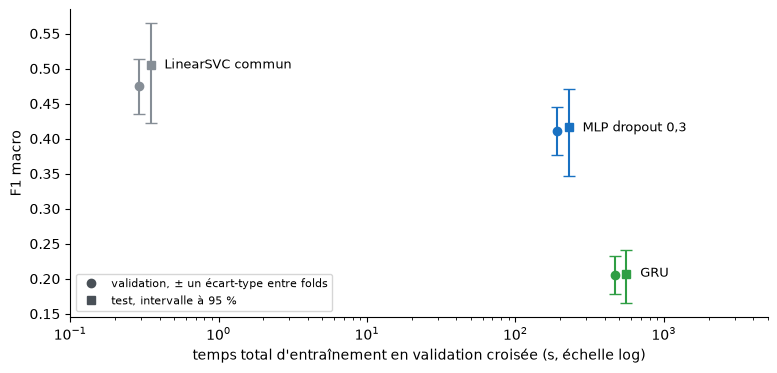

In [1]:
# Synthèse des trois choix figés : F1 macro de validation et de test face au temps d'entraînement.
SYNTHESE = {'LinearSVC commun': COULEURS['LinearSVC commun'], 'MLP dropout 0,3': COULEURS['MLP'],
            'GRU': COULEURS['GRU']}


def ligne_synthese(nom: str) -> dict:
    """F1 de validation et de test, intervalle du test, taille et temps total de validation."""
    bilan, test = ligne_bilan(nom), bilan_test.loc[nom]
    return {'Modèle': nom, 'F1 validation': bilan['F1 macro'],
            'Écart-type validation': bilan['F1 écart-type'], 'F1 test': test['F1 test'],
            'Intervalle 95 % bas': test['Intervalle 95 % bas'],
            'Intervalle 95 % haut': test['Intervalle 95 % haut'],
            'Paramètres (fold 1)': bilan['Paramètres (fold 1)'],
            'Temps de validation (s)': bilan['Temps total (s)']}


synthese = pd.DataFrame([ligne_synthese(nom) for nom in SYNTHESE]).set_index('Modèle')
display(synthese.astype({'Paramètres (fold 1)': 'Int64'}).round(3))

# Validation en rond avec un écart-type, test en carré avec l'intervalle à 95 %
fig, ax = plt.subplots(figsize=(9, 4))
for nom, ligne in synthese.iterrows():
    temps, couleur = ligne['Temps de validation (s)'], SYNTHESE[nom]
    ax.errorbar(temps, ligne['F1 validation'], yerr=ligne['Écart-type validation'], fmt='o',
                color=couleur, capsize=4)
    bas = ligne['F1 test'] - ligne['Intervalle 95 % bas']
    haut = ligne['Intervalle 95 % haut'] - ligne['F1 test']
    ax.errorbar(temps * 1.2, ligne['F1 test'], yerr=[[bas], [haut]], fmt='s', color=couleur,
                capsize=4)
    ax.annotate(nom, (temps * 1.2, ligne['F1 test']), textcoords='offset points',
                xytext=(10, 0), va='center', fontsize=9)
ax.plot([], [], 'o', color='#495057', label='validation, ± un écart-type entre folds')
ax.plot([], [], 's', color='#495057', label='test, intervalle à 95 %')
ax.set_xscale('log')
ax.set_xlim(0.1, 5000)
ax.set(xlabel="temps total d'entraînement en validation croisée (s, échelle log)",
       ylabel='F1 macro')
ax.legend(fontsize=8, loc='lower left')
ax.spines[['top', 'right']].set_visible(False)
plt.show()

> *Mes observations :*
>
> `LinearSVC commun` domine sur les deux axes, avec le meilleur F1 en validation, 0,475, et sur le test, 0,505, pour moins d'une seconde d'ajustement sur les cinq folds. Le MLP avec dropout coûte environ trois minutes de validation pour 0,065 de F1 en moins, et le GRU près de huit minutes pour un F1 deux fois plus bas. Les intervalles du test de LinearSVC et du MLP se recouvrent, alors que celui du GRU reste nettement en dessous.

**Quel signal je prédis.** Je prédis le locuteur d'une réplique isolée, et le signal reste lexical. Les noms valent environ 0,05 de F1 macro pour LinearSVC et le MLP (section 4.3), et les répliques longues sont mieux classées (sections 3.5 et 4.2). L'ordre des mots n'apporte rien de significatif (section 4.3). Les erreurs de LinearSVC restent dans la pièce deux fois plus souvent qu'au hasard, donc une part du signal tient à la pièce plutôt qu'au locuteur (section 4.2).

**Ce que chaque modèle apprend.** LinearSVC pondère des termes rares, dont des noms comme « kate », et sépare tout le train. Le MLP résume la réplique par une moyenne d'embeddings, mémorise le train vers l'epoch 43 et généralise mieux avec un dropout de 0,3. Le LSTM et le GRU mémorisent le train en une vingtaine d'epochs sans exploiter l'ordre, et leurs erreurs dérivent vers les locuteurs fréquents.

**Sur quelles données il généralise.** Chaque modèle apprend sur 615 répliques par fold, et les courbes d'apprentissage de LinearSVC et du MLP montent encore à 100 % du train (section 4.3). Le test confirme l'ordre de validation, mais il partage les pièces du train, car le découpage se fait par réplique. Je ne mesure donc pas la généralisation à une pièce inconnue.

**Quelle métrique traduit le besoin.** Le F1 macro, car les dix locuteurs comptent autant et leurs effectifs vont de 62 à 103 en développement. Je l'accompagne de l'écart-type entre folds et entre seeds, du test de McNemar sur les mêmes répliques et d'un intervalle bootstrap sur le test. La dispersion seule ne dit pas si un écart est réel.

**Quel modèle répond le mieux.** `LinearSVC commun`, avec 0,475 de F1 macro en validation et 0,505 sur le test, pour un ajustement de moins d'une seconde. Le MLP avec dropout le suit à 0,410 et 0,416 pour quelques minutes d'entraînement, et le GRU reste à 0,206 et 0,207. Sur ce petit jeu, le deep learning ne rembourse pas son coût.

**Ce que mes expériences disent de H1 à H4.**

| Hypothèse | Verdict | Ce qui le montre |
|---|---|---|
| H1, indices lexicaux | Réfutée | Le MLP obtient 0,376 contre 0,475 pour LinearSVC en validation, soit 0,099 d'écart (section 3.4). Avec dropout, l'écart vaut encore 0,065 en validation et 0,089 sur le test (sections 4.3 et 4.4). |
| H2, ordre des mots | Logique confirmée, baisse prévue absente | Le LSTM et le GRU restent 0,17 sous le MLP (sections 3.5 et 3.6). Mélanger les mots ne coûte que 0,007 au GRU, donc il n'exploite pas l'ordre (section 4.3). |
| H3, mémorisation | Confirmée pour l'écart, en partie pour le délai | L'écart train/validation va de 0,59 à 0,79 pour tous les réseaux. Le F1 train atteint 0,99 vers l'epoch 22 pour le LSTM et le GRU, mais vers l'epoch 43 pour le MLP (sections 3.4 à 3.6). |
| H4, coût du GRU | Confirmée pour les paramètres et le score, réfutée pour le temps | 156 170 paramètres contre 164 490 et un écart de F1 de −0,001, mais environ 0,8 s par epoch pour les deux réseaux (section 3.6). |

**Ce qui reste incertain.**

- Le contexte, car je classe chaque réplique seule, alors que les erreurs restent deux fois plus souvent dans la pièce qu'au hasard. Les répliques voisines aideraient sans doute, mais je ne l'ai pas mesuré.
- Le style, car retirer les noms ne coûte qu'environ 0,05 de F1, donc le reste du signal vient d'autres mots. Je ne sais pas séparer le style d'un locuteur du sujet de ses scènes.
- La généralisation, car le test a déjà servi au TP1, il partage les pièces du train et l'étiquette GLOUCESTER couvre deux pièces. Avec 193 répliques, l'intervalle de LinearSVC va encore de 0,422 à 0,565.

> *Ma conclusion :* pour identifier le locuteur d'une réplique de Tiny Shakespeare, LinearSVC sur TF–IDF reste le meilleur choix, en score comme en coût. Les réseaux mémorisent le train sans exploiter l'ordre des mots. Le meilleur d'entre eux, le MLP avec dropout, reste 0,065 sous LinearSVC en validation. Les deux familles s'appuient sur les mêmes indices lexicaux, noms et longueur, et toutes deux gagneraient à avoir plus de répliques.

### Pour aller plus loin

Ces pistes sortent du cadre de ce TP, et chacune répond à un résultat.

- Un encodeur pré-entraîné de type BERT, car les courbes d'apprentissage montent encore à 100 % du train (section 4.3). Des représentations apprises sur un grand corpus compenseraient le manque de répliques.
- L'attention au niveau des caractères sur ce même corpus, car environ 14 % des tokens de validation sont inconnus du train (section 2.1). Des caractères couvriraient ces mots rares.
- Les répliques voisines comme contexte, car les erreurs restent dans la pièce deux fois plus souvent qu'au hasard (section 4.2).
- Un découpage par pièce, pour mesurer enfin la généralisation à des pièces jamais vues.